# Máquinas Térmicas - Lección 15b (Bonus)
## La planta termoeléctrica completa: de la llama al giro y del giro a la red

**Fuentes estudiantiles (PUJ):**
- Juan Andrés Sánchez, Juan David Aparicio y Juan David Roa — *Planta Termoeléctrica* (entrega del curso): ciclo combinado con turbina de gas Siemens SGT-800, Euler por etapa en el compresor (15 etapas), la turbina de gas (3), la turbina de vapor y la bomba centrífuga, caldera de serpentín, condensador de coraza y tubos, e integración transitoria.
- D. A. Arias-Guerrero, M. Castillo-Hernández, J. D. Mayorga-Guzmán y C. A. Bayona-Roa — *Computational Modeling of the Combustion Reaction Kinetics of the Oil Palm's Empty Fruit Bunch and Mesocarp Fiber* (artículo en revisión): combustibles EFB/PMF y caldera de biomasa de 30 t/h (configuración B).

**Datos de validación de plantas reales:**
- Siemens Energy, ficha y póster de la **SGT-800** (calificación de 62 MW, ISO): eficiencia, relación de presiones, caudal y temperatura de escape.
- Siemens, **SCC-800 1×1**: banda de eficiencia neta del ciclo combinado.
- Åström & Bell (1998, 2000): **datos de operación** de la unidad P16-G16 (160 MW) de Öresundsverket, Malmö, ante escalones de combustible (Fig. 10).

**Adaptación AVA:** Camilo Bayona

### Objetivos de aprendizaje
1. Explicar con una cadena causal **cómo una turbomáquina transforma entalpía en par** (Euler) y en qué se diferencia del pistón y la biela de los motores de combustión interna.
2. Calcular **etapa por etapa** el cambio de densidad, área y velocidad en el compresor y la turbina, y por qué el canal se cierra o se abre.
3. Acoplar la **combustión 0D**, la **recuperación de calor** con pinch y el **ciclo de vapor**, y verificar el diseño contra el fabricante.
4. Resolver en el tiempo la **dinámica del domo** (*shrink & swell*), del metal de la caldera, del condensador y de la **frecuencia de la red**, y validarla contra datos de una planta real.
5. Operar la planta desde un **tablero global** según la demanda de electricidad y juzgar las estrategias de control.

> **Qué es de quién.** Los recuadros marcados 🎓 son contribución de los estudiantes investigadores. El resto es el modelo estándar del curso (Çengel, Dixon, Kehlhofer, Åström-Bell, Kundur) o desarrollo de esta adaptación. Cada supuesto propio se declara con la palabra **SUPUESTO** en el código.

In [1]:
# Instalación solo en Google Colab; en el entorno local del curso es un no-op
import sys, os, subprocess, urllib.request
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cantera==3.2.0", "CoolProp", "ipywidgets"], check=True)
    from google.colab import output
    output.enable_custom_widget_manager()
os.makedirs("data", exist_ok=True)
REPO = "https://raw.githubusercontent.com/camilobayonaroa/ThermalMachines/"
for arch in ("planta_resultados.json", "astrom_bell_fig10.json"):
    ruta = os.path.join("data", arch)
    for rama in ("main", "nb15b-planta-termoelectrica"):
        if os.path.exists(ruta): break
        try: urllib.request.urlretrieve(REPO + rama + "/notebooks/data/" + arch, ruta)
        except Exception: pass
    print(arch, "disponible:", os.path.exists(ruta))

planta_resultados.json disponible: True
astrom_bell_fig10.json disponible: True


In [2]:
# === Setup ===================================================================
import math, json, time, bisect, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch, Circle, Wedge, Polygon, FancyArrowPatch
import pandas as pd
import cantera as ct
import CoolProp.CoolProp as CP
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, fsolve, least_squares
from ipywidgets import (interactive_output, FloatSlider, IntSlider, Dropdown, ToggleButtons, Play, HBox, VBox,
                        Layout, jslink, Button, Output, HTML, Checkbox)
from IPython.display import display
warnings.filterwarnings("ignore"); ct.suppress_thermo_warnings()
trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

COL = {"tinta": "#3a3a38", "gris": "#8a8a86", "aviso": "#e34948", "gas": "#e34948", "tibio": "#eb6834", "vapor": "#4a3aa7",
       "agua": "#2a78d6", "metal": "#c3c2b7", "red": "#1baf7a", "modelo": "#e34948", "medido": "#3a3a38", "entrega": "#eb6834"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
G = 9.81
P_ISO, T_ISO = 101325.0, 288.15
F0 = 60.0                                    # Hz: frecuencia del sistema colombiano
RPM_TG = 6600.0; OMEGA_TG = RPM_TG*2*np.pi/60  # SGT-800 (acoplada al generador por caja reductora)

# ---------- Tablas de propiedades del agua (CoolProp) para EDO rápidas -------------------------------------
# saturación 0.5-15 MPa (domo); vapor sobrecalentado y líquido subenfriado en theta = |T - Tsat(p)| para no
# interpolar NUNCA a través del domo de saturación; expansión húmeda h(p_c, s) para la turbina.
P_SAT = np.linspace(0.5e6, 15e6, 600)
SAT = {k: np.array([CP.PropsSI(kk, "P", p, "Q", q, "Water") for p in P_SAT])
       for k, kk, q in [("rw", "D", 0), ("rs", "D", 1), ("hw", "H", 0), ("hs", "H", 1), ("Ts", "T", 0)]}
for k in list(SAT): SAT["d" + k] = np.gradient(SAT[k], P_SAT)
P_PT = np.linspace(0.5e6, 14.5e6, 29)
TH = np.r_[0.0, 0.25, 0.5, 1, 2, 3, 5, 7.5, 10, 15, 20, 25, 30, 40, 50, 60, 80, 100, 125, 150, 175, 200, 250, 300, 350, 400, 450]
TSAT_PT = np.array([CP.PropsSI("T", "P", p, "Q", 0, "Water") for p in P_PT])
def _fase(k, signo, q):
    Z = np.empty((len(P_PT), len(TH)))
    for i, p in enumerate(P_PT):
        for j, th in enumerate(TH):
            if th == 0.0 and k != "C": Z[i, j] = CP.PropsSI(k, "P", p, "Q", q, "Water")
            else: Z[i, j] = CP.PropsSI(k, "P", p, "T", max(TSAT_PT[i] + signo*max(th, 0.02), 274.0), "Water")
    return Z
HV, SV, CPV = _fase("H", +1, 1), _fase("S", +1, 1), _fase("C", +1, 1)
HL, CPL = _fase("H", -1, 0), _fase("C", -1, 0)
P_C = np.linspace(2e3, 40e3, 39); S_C = np.linspace(5800.0, 7800.0, 81)
H_CS = np.array([[CP.PropsSI("H", "P", pc, "S", s, "Water") for s in S_C] for pc in P_C])
CSAT = {k: np.array([CP.PropsSI(kk, "P", pc, "Q", q, "Water") for pc in P_C])
        for k, kk, q in [("Ts", "T", 0), ("hf", "H", 0), ("hg", "H", 1), ("rg", "D", 1), ("rf", "D", 0)]}

# ---------- interpolación rápida en Python puro (las EDO llaman esto ~10^5 veces) ---------------------------
def _ix(g, x):
    i = bisect.bisect_right(g, x) - 1; n = len(g); i = 0 if i < 0 else (n - 2 if i > n - 2 else i)
    return i, (x - g[i])/(g[i + 1] - g[i])
class Tabla1D:
    def __init__(self, x, cols):
        self.x = [float(v) for v in x]; self.k = list(cols); self.c = [[float(v) for v in cols[k]] for k in self.k]
    def todo(self, x):
        i, t = _ix(self.x, x); return {k: c[i] + t*(c[i + 1] - c[i]) for k, c in zip(self.k, self.c)}
_SAT, _CS = Tabla1D(P_SAT, SAT), Tabla1D(P_C, CSAT)
def sat(p): return _SAT.todo(p)
def csat(pc): return _CS.todo(pc)
_PPT, _TH, _TSAT = P_PT.tolist(), TH.tolist(), TSAT_PT.tolist()
_L = {"HV": HV.tolist(), "SV": SV.tolist(), "CPV": CPV.tolist(), "HL": HL.tolist(), "CPL": CPL.tolist()}
_PC, _SC, _HCS, _TSC = P_C.tolist(), S_C.tolist(), H_CS.tolist(), CSAT["Ts"].tolist()
def bilin(Z, xg, yg, x, y):
    i, tx = _ix(xg, x); j, ty = _ix(yg, y)
    return Z[i][j]*(1 - tx)*(1 - ty) + Z[i + 1][j]*tx*(1 - ty) + Z[i][j + 1]*(1 - tx)*ty + Z[i + 1][j + 1]*tx*ty
def tsat_p(p): i, t = _ix(_PPT, p); return _TSAT[i] + t*(_TSAT[i + 1] - _TSAT[i])
def h_v(p, T): return bilin(_L["HV"], _PPT, _TH, p, max(T - tsat_p(p), 0.0))
def h_l(p, T): return bilin(_L["HL"], _PPT, _TH, p, max(tsat_p(p) - T, 0.0))
def cp_v(p, T): return bilin(_L["CPV"], _PPT, _TH, p, max(T - tsat_p(p), 0.0))
def cp_l(p, T): return bilin(_L["CPL"], _PPT, _TH, p, max(tsat_p(p) - T, 0.0))
def _theta(Z, p, h):
    i, t = _ix(_PPT, p); fila = [a + t*(b - a) for a, b in zip(Z[i], Z[i + 1])]
    j, u = _ix(fila, h); return _TH[j] + u*(_TH[j + 1] - _TH[j])
def T_ph_v(p, h): return tsat_p(p) + _theta(_L["HV"], p, h)
def T_ph_l(p, h): return tsat_p(p) - _theta([[-v for v in r] for r in _L["HL"]], p, -h)
def s_ph_v(p, h): return bilin(_L["SV"], _PPT, _TH, p, _theta(_L["HV"], p, h))
def h_ps_c(pc, s): return bilin(_HCS, _PC, _SC, pc, s)
def pc_de_Tsat(T): j, u = _ix(_TSC, T); return _PC[j] + u*(_PC[j + 1] - _PC[j])

class GasTab:
    # entalpía y cp de una mezcla de gases de composición congelada (Cantera), tabulada para las EDO
    def __init__(self, comp, por="Y"):
        g = ct.Solution("gri30.yaml"); self.T = np.linspace(280.0, 2400.0, 425); h = []
        for T in self.T:
            if por == "Y": g.TPY = T, ct.one_atm, comp
            else: g.TPX = T, ct.one_atm, comp
            h.append(g.enthalpy_mass)
        self.h = np.array(h); self.cp = np.gradient(self.h, self.T)
        self._h, self._cp, self._T0, self._dT = self.h.tolist(), self.cp.tolist(), float(self.T[0]), float(self.T[1] - self.T[0])
    def _w(self, T):
        f = (T - self._T0)/self._dT; i = min(max(int(f), 0), len(self._h) - 2); return i, f - i
    def hT(self, T): i, t = self._w(T); return self._h[i] + t*(self._h[i + 1] - self._h[i])
    def cpT(self, T): i, t = self._w(T); return self._cp[i] + t*(self._cp[i + 1] - self._cp[i])
    def Th(self, h):
        i, t = _ix(self._h, h); return self._T0 + self._dT*(i + t)

ARCH = os.path.join("data", "planta_resultados.json")
CACHE = json.load(open(ARCH)) if os.path.exists(ARCH) else {}
RECALCULAR = False      # True: rehace todos los cálculos pesados (mapa de la TG, escenarios del tablero) y reescribe la caché
print(f"Setup OK — tablas de agua listas ({len(P_SAT)} pts de saturación, {HV.size} de vapor); caché: {sorted(CACHE)}")

Setup OK — tablas de agua listas (600 pts de saturación, 783 de vapor); caché: ['cal_tg', 'carga_parcial', 'escenarios', 'fig10', 'gt_map']


## 1. Contexto: cinco ideas que explican una planta termoeléctrica

Una planta de ciclo combinado convierte energía **química → térmica → de presión y velocidad → de rotación → eléctrica**. En los motores de pistón (Lecciones 10-11) el paso "presión → giro" lo hace la biela-manivela. En la planta lo hacen las **turbomáquinas**, y de ese cambio se desprende todo lo demás:

1. **El par nace del momento angular, no de un brazo de palanca.** En el pistón, $\tau=F_{gas}\,r\,\sin(\theta+\phi)/\cos\phi$ oscila en cada ciclo. En la turbomáquina el flujo es continuo y el álabe cambia la **velocidad tangencial** del fluido: $\tau=\dot m\,(r_2c_{\theta2}-r_1c_{\theta1})$ (Euler). El par es estacionario, sin carreras ni volantes de inercia.
2. **Comprimir es difícil, expandir es fácil.** Un gradiente adverso de presión despega la capa límite. Por eso el compresor necesita **15 etapas** de poca carga y la turbina solo **3**, cada una con un salto de entalpía grande. En el pistón ambas carreras usan el mismo cilindro.
3. **La "relación de compresión" es volumétrica también aquí, pero se reparte en el espacio.** En el pistón el volumen cambia en el tiempo. En la turbomáquina la densidad cambia a lo largo del eje, y para mantener la velocidad axial el **canal anular se cierra** en el compresor y se **abre** en la turbina ($A\propto 1/\rho$).
4. **El calor que la turbina de gas no aprovecha alimenta un segundo ciclo.** Los gases salen a ~600 °C, y una caldera de recuperación (HRSG) genera vapor para una turbina de vapor. El límite lo pone el **pinch**: la mínima diferencia de temperatura entre gas y agua.
5. **La red impone la velocidad y la demanda impone la potencia.** Todos los generadores giran sincronizados a 60 Hz. Si la demanda supera la generación, la energía cinética de los rotores cubre la diferencia y la **frecuencia cae**. La turbina de gas responde en segundos. El vapor depende de la inercia térmica del metal y del agua del domo, que responde en minutos y además puede **invertir** la respuesta del nivel (*swell*).

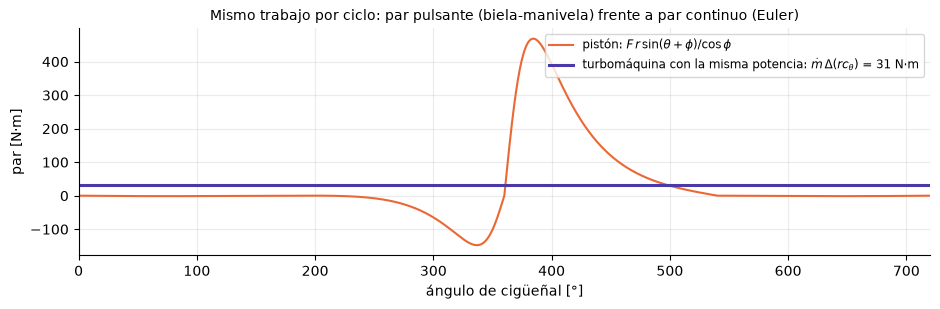

par pico/medio del pistón = 15.3 : el pistón necesita volante; la turbina no


In [3]:
# Pistón vs. turbomáquina: el mismo trabajo por ciclo entregado con par oscilante o con par constante
th = np.linspace(0, 4*np.pi, 1441)                     # 2 vueltas = 1 ciclo de 4 tiempos
r, l, B = 0.045, 0.145, 0.086; Ap = np.pi*B**2/4; rc = 10.0
x = r*np.cos(th) + np.sqrt(l**2 - (r*np.sin(th))**2); V = Ap*(r + l - x) + Ap*2*r/(rc - 1)
fase = (th % (4*np.pi))
p = np.where(fase < np.pi, 0.95e5, 0.0)                                         # admisión
Vb, Vt = V.max(), V.min()
p = np.where((fase >= np.pi) & (fase < 2*np.pi), 0.95e5*(Vb/V)**1.33, p)        # compresión
p = np.where((fase >= 2*np.pi) & (fase < 3*np.pi), 6.0e6*(Vt/V)**1.30, p)       # expansión (Otto ideal: p3 ~ 6 MPa)
p = np.where(fase >= 3*np.pi, 1.05e5, p)                                        # escape
phi = np.arcsin(r*np.sin(th)/l)
tau = (p - 1.0e5)*Ap*r*np.sin(th + phi)/np.cos(phi)
tau_med = trapz(tau, th)/(th[-1] - th[0])
fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.plot(np.degrees(th), tau, color=COL["tibio"], lw=1.5, label="pistón: $F\\,r\\,\\sin(\\theta+\\phi)/\\cos\\phi$")
ax.axhline(tau_med, color=COL["vapor"], lw=2.2, label=f"turbomáquina con la misma potencia: $\\dot m\\,\\Delta(r c_\\theta)$ = {tau_med:.0f} N·m")
ax.set_xlabel("ángulo de cigüeñal [°]"); ax.set_ylabel("par [N·m]"); ax.set_xlim(0, 720); ax.legend(loc="upper right", fontsize=8.5)
ax.set_title("Mismo trabajo por ciclo: par pulsante (biela-manivela) frente a par continuo (Euler)", fontsize=10)
plt.tight_layout(); plt.show()
print(f"par pico/medio del pistón = {tau.max()/tau_med:.1f} : el pistón necesita volante; la turbina no")

## 2. La planta y sus estados

El esquema reemplaza el dibujo a mano de la entrega. La numeración sigue a Çengel: **gas 5-9** (5 entrada del compresor, 6 salida del compresor, 7 entrada de la turbina, 8 escape, 9 chimenea) y **vapor 1-4** (1 salida del condensador, 2 salida de la bomba, 3 entrada de la turbina de vapor, 4 escape). El recuadro punteado es la **configuración B**, en la que el hogar de biomasa EFB/PMF del artículo reemplaza a la turbina de gas.

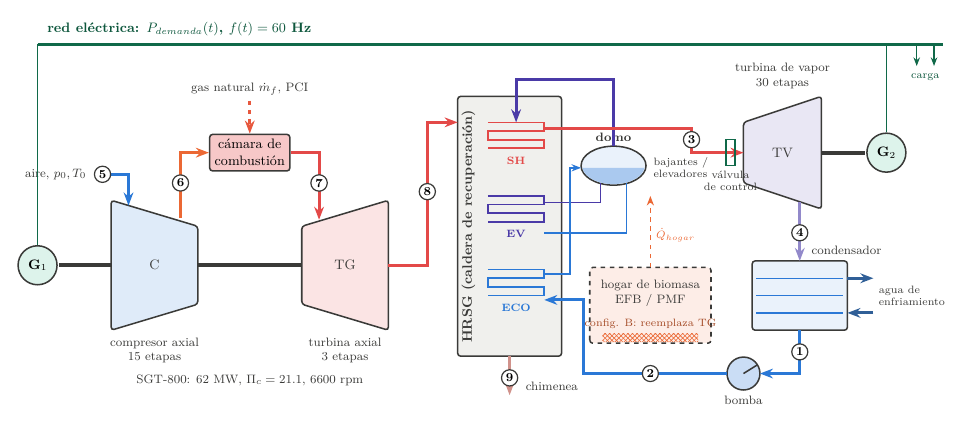

In [4]:
# Datos de la entrega frente a los del fabricante (póster SGT-800, calificación de 62 MW, ISO, gas natural)
SGT800 = {"P_el [MW]": 62.0, "eta [%]": 41.1, "heat rate [kJ/kWh]": 8759, "Pi [-]": 21.1, "m_escape [kg/s]": 135.5,
          "T_escape [°C]": 596, "rpm": 6600}
ENTREGA = {"P_el [MW]": 62.50, "eta [%]": 39.31, "heat rate [kJ/kWh]": 9158, "Pi [-]": 21.10, "m_escape [kg/s]": 135.5,
           "T_escape [°C]": 595.9, "rpm": 6600}
ENTREGA_CC = {"P_neta CC [MW]": 85.64, "eta CC [%]": 53.86, "m_vapor [kg/s]": 21.68, "T_chimenea [°C]": 176.6,
              "Q_caldera [MW]": 61.59, "p3 / T3": "12 MPa / 540 °C", "p_cond [kPa]": 9.0}
df = pd.DataFrame({"SGT-800 (fabricante)": SGT800, "Entrega (diésel n.° 2)": ENTREGA})
display(df)
print("Ciclo combinado de la entrega:", ENTREGA_CC)

,SGT-800 (fabricante),Entrega (diésel n.° 2)
P_el [MW],62.0,62.50
eta [%],41.1,39.31
heat rate [kJ/kWh],8759.0,9158.00
Pi [-],21.1,21.10
m_escape [kg/s],135.5,135.50
T_escape [°C],596.0,595.90
rpm,6600.0,6600.00


Ciclo combinado de la entrega: {'P_neta CC [MW]': 85.64, 'eta CC [%]': 53.86, 'm_vapor [kg/s]': 21.68, 'T_chimenea [°C]': 176.6, 'Q_caldera [MW]': 61.59, 'p3 / T3': '12 MPa / 540 °C', 'p_cond [kPa]': 9.0}


## 3. Cinemática de la rotación: Euler y los triángulos de velocidad

**Ecuación de Euler.** Para un volumen de control que gira con el rotor, el par es el cambio de **momento angular** del flujo:

$$\tau=\dot m\,(r_2c_{\theta2}-r_1c_{\theta1}),\qquad w=\frac{\tau\,\omega}{\dot m}=U_2c_{\theta2}-U_1c_{\theta1}=\Delta h_0 .$$

**Triángulos.** La velocidad absoluta es la relativa más la de arrastre: $\vec c=\vec w+\vec U$, con $U=\omega r$. En una etapa axial ($r$ constante) se usan tres números adimensionales:

$$\phi=\frac{c_a}{U}\ \text{(caudal)},\qquad \psi=\frac{\Delta h_0}{U^2}\ \text{(carga)},\qquad R=\frac{\Delta h_{rotor}}{\Delta h_{etapa}}\ \text{(reacción)} .$$

**Por qué un compresor necesita muchas etapas.** En el rotor del compresor el fluido **desacelera** en marco relativo ($w_2<w_1$) contra un gradiente adverso de presión. Si desacelera demasiado, la capa límite se desprende y la etapa entra en pérdida. El **criterio de de Haller** pone el límite práctico: $w_2/w_1\gtrsim 0.72$, y con él $\psi$ queda en 0.3-0.45. En la turbina el fluido **acelera** ($w_3>w_2$), así que puede tolerar $\psi\approx 2$ y tomar mucha más energía por etapa.

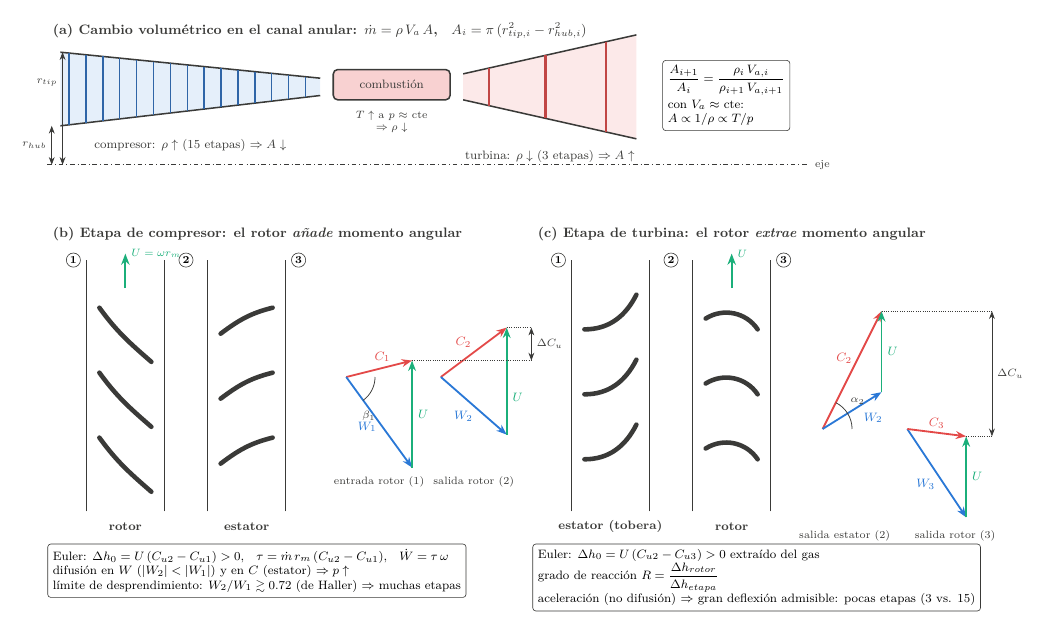

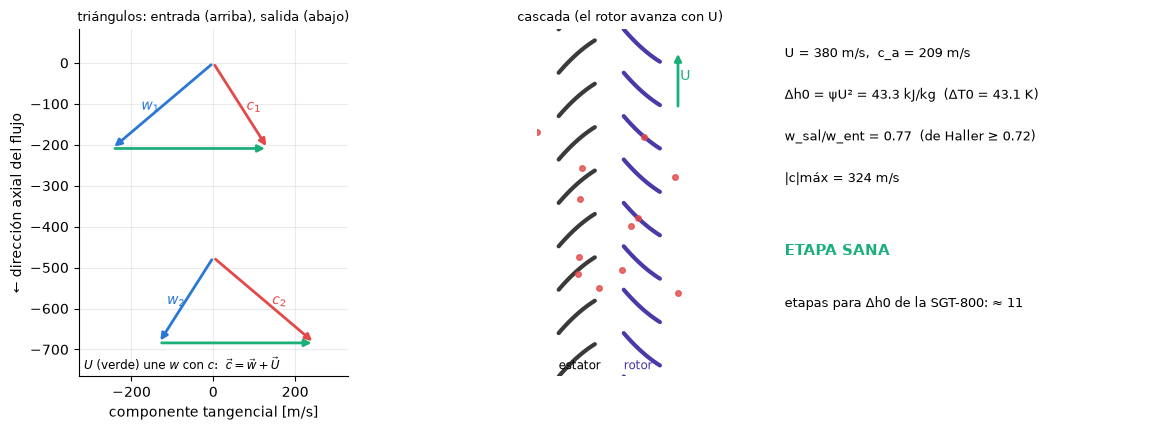

In [5]:
def triangulos(phi, psi, R, U=380.0, maquina="compresor"):
    # Etapa axial normal (c_a constante, r constante). Devuelve vectores (axial, tangencial) en m/s.
    ca = phi*U
    if maquina == "compresor":
        # el rotor AUMENTA c_theta: c_th2 - c_th1 = psi*U ; reaccion R = 1 - (c_th1 + c_th2)/(2U)
        cth1 = U*(1 - R) - psi*U/2; cth2 = cth1 + psi*U
        c1, c2 = np.array([ca, cth1]), np.array([ca, cth2])
        w1, w2 = c1 - [0, U], c2 - [0, U]
        haller = np.linalg.norm(w2)/np.linalg.norm(w1)
        return dict(c1=c1, c2=c2, w1=w1, w2=w2, U=U, ca=ca, haller=haller, dh=psi*U**2)
    # turbina: el estator acelera y gira el flujo (c_th2 grande), el rotor lo devuelve: c_th2 - c_th3 = psi*U
    cth2 = U*(1 - R) + psi*U/2; cth3 = cth2 - psi*U
    c2, c3 = np.array([ca, cth2]), np.array([ca, cth3])
    w2, w3 = c2 - [0, U], c3 - [0, U]
    return dict(c1=c2, c2=c3, w1=w2, w2=w3, U=U, ca=ca, haller=np.linalg.norm(w3)/np.linalg.norm(w2), dh=psi*U**2)

def dibujar_triangulos(ax, T, maquina):
    U = T["U"]; o1, o2 = np.array([0.0, 0.0]), np.array([0.0, -1.25*U])
    pts = []
    for (o, c, w, n) in [(o1, T["c1"], T["w1"], "1" if maquina == "compresor" else "2"), (o2, T["c2"], T["w2"], "2" if maquina == "compresor" else "3")]:
        pts += [o, o + np.array([c[1], -c[0]]), o + np.array([w[1], -w[0]])]
        ax.annotate("", xy=o + np.array([c[1], -c[0]]), xytext=o, arrowprops=dict(arrowstyle="-|>", color=COL["gas"], lw=2))
        ax.annotate("", xy=o + np.array([w[1], -w[0]]), xytext=o, arrowprops=dict(arrowstyle="-|>", color=COL["agua"], lw=2))
        ax.annotate("", xy=o + np.array([c[1], -c[0]]), xytext=o + np.array([w[1], -w[0]]), arrowprops=dict(arrowstyle="-|>", color=COL["red"], lw=2))
        ax.text(*(o + np.array([c[1], -c[0]])*0.55 + [8, 0]), f"$c_{n}$", color=COL["gas"])
        ax.text(*(o + np.array([w[1], -w[0]])*0.55 + [-40, 0]), f"$w_{n}$", color=COL["agua"])
    ax.text(0.02, 0.02, "$U$ (verde) une $w$ con $c$:  $\\vec c=\\vec w+\\vec U$", transform=ax.transAxes, fontsize=8.5)
    P_ = np.array(pts); m = 0.12*np.ptp(P_, axis=0).max()
    ax.set_xlim(P_[:, 0].min() - m, P_[:, 0].max() + m); ax.set_ylim(P_[:, 1].min() - m, P_[:, 1].max() + m)
    ax.set_aspect("equal"); ax.set_xlabel("componente tangencial [m/s]"); ax.set_ylabel("← dirección axial del flujo")
    ax.set_title("triángulos: entrada (arriba), salida (abajo)", fontsize=9)

def dibujar_cascada(ax, T, maquina, t):
    # filas: estator fijo arriba y rotor que se desplaza con U*t (marco absoluto); trazadores que avanzan con c
    U, ca = T["U"], T["ca"]; s = 0.06; L = 0.05; esc = 1.0
    ang = lambda v: np.arctan2(v[1], v[0])
    b_in, b_out = ang(T["w1"]), ang(T["w2"])                 # ángulos relativos: geometría del álabe del rotor
    a_in, a_out = (ang(T["c2"]), ang(T["c1"])) if maquina == "compresor" else (ang(T["c2"]), ang(T["c1"]))
    def alabe(x0, y0, b1, b2, color):
        xs = np.linspace(0, L, 20); dth = np.tan(b1) + (np.tan(b2) - np.tan(b1))*xs/L
        ys = y0 + np.cumsum(np.r_[0, np.diff(xs)]*dth)
        ax.plot(x0 + xs, ys, color=color, lw=3, solid_capstyle="round")
    off = (U*t*1e-3) % s
    for k in range(-3, 6):
        alabe(0.0, k*s, a_in, a_out, COL["tinta"])                      # estator (fijo)
        alabe(0.09, k*s + off, b_in, b_out, COL["vapor"])             # rotor (se mueve con U)
    ax.annotate("", xy=(0.165, 0.27), xytext=(0.165, 0.19), arrowprops=dict(arrowstyle="-|>", color=COL["red"], lw=2))
    ax.text(0.168, 0.23, "U", color=COL["red"])
    rng = np.random.default_rng(3); y0 = rng.uniform(-0.1, 0.25, 12); t0s = rng.uniform(0, 1, 12)
    for yy, tt in zip(y0, t0s):
        ph = ((t*1e-3*ca/0.2) + tt) % 1.0; xx = -0.03 + ph*0.2
        cth = T["c2"][1] if (0.0 < xx < 0.05) else (T["c1"][1] if xx < 0.09 else T["c2"][1])
        ax.plot(xx, yy + 0.03*np.sin(2*np.pi*ph), "o", ms=4, color=COL["gas"], alpha=0.8)
    ax.text(0.0, -0.17, "estator", fontsize=8.5); ax.text(0.09, -0.17, "rotor", fontsize=8.5, color=COL["vapor"])
    ax.set_xlim(-0.03, 0.2); ax.set_ylim(-0.18, 0.3); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("cascada (el rotor avanza con U)", fontsize=9)

def w1_triangulos(maquina, phi, psi, R, t):
    T = triangulos(phi, psi, R, U=380.0 if maquina == "compresor" else 411.0, maquina=maquina)
    fig, axs = plt.subplots(1, 3, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.15, 1.0, 0.85]})
    dibujar_triangulos(axs[0], T, maquina); dibujar_cascada(axs[1], T, maquina, t)
    cp = 1005.0 if maquina == "compresor" else 1150.0
    lim = 0.72; ok = T["haller"] >= lim if maquina == "compresor" else True
    txt = [f"U = {T['U']:.0f} m/s,  c_a = {T['ca']:.0f} m/s",
           f"Δh0 = ψU² = {T['dh']/1e3:.1f} kJ/kg  (ΔT0 = {T['dh']/cp:.1f} K)",
           f"w_sal/w_ent = {T['haller']:.2f}" + ("  (de Haller ≥ 0.72)" if maquina == "compresor" else "  (acelera: sin límite de Haller)"),
           f"|c|máx = {max(np.linalg.norm(T['c1']), np.linalg.norm(T['c2'])):.0f} m/s"]
    axs[2].axis("off")
    for i, s_ in enumerate(txt): axs[2].text(0.0, 0.92 - 0.12*i, s_, fontsize=9.5, transform=axs[2].transAxes)
    estado = ("ETAPA SANA" if ok else "PÉRDIDA (desprendimiento): baje ψ o suba φ")
    axs[2].text(0.0, 0.35, estado, fontsize=11, weight="bold", color=COL["red"] if ok else COL["aviso"], transform=axs[2].transAxes)
    n_et = int(np.ceil((470e3 if maquina == "compresor" else 1000e3)/T["dh"]))
    axs[2].text(0.0, 0.2, f"etapas para Δh0 de la SGT-800: ≈ {n_et}", fontsize=9.5, transform=axs[2].transAxes)
    plt.tight_layout(); plt.show()

w_maq = ToggleButtons(options=["compresor", "turbina"], value="compresor", description="máquina")
w_phi = FloatSlider(value=0.55, min=0.25, max=0.9, step=0.01, description="φ = c_a/U", continuous_update=False)
w_psi = FloatSlider(value=0.30, min=0.1, max=2.6, step=0.01, description="ψ = Δh0/U²", continuous_update=False)
w_R = FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, description="reacción R", continuous_update=False)
w_t = Play(value=0, min=0, max=400, step=4, interval=120, description="animar"); w_ts = IntSlider(value=0, min=0, max=400, description="t [ms]")
jslink((w_t, "value"), (w_ts, "value"))
def _maq(ch):
    if ch["new"] == "turbina": w_psi.value, w_phi.value = 1.9, 0.6
    else: w_psi.value, w_phi.value = 0.30, 0.55
w_maq.observe(_maq, names="value")
display(VBox([HBox([w_maq, w_R]), HBox([w_phi, w_psi]), HBox([w_t, w_ts]),
              interactive_output(w1_triangulos, dict(maquina=w_maq, phi=w_phi, psi=w_psi, R=w_R, t=w_ts))]))

**Widget 1. Triángulos de velocidad y cascada.**
1. En **compresor**, sube $\psi$ hasta que $w_2/w_1<0.72$. Ese es el límite de carga por etapa, y por eso la SGT-800 necesita unas 15 etapas.
2. Cambia a **turbina**: con $\psi\approx2$ el flujo acelera y 3 etapas bastan para extraer ~1000 kJ/kg.
3. Con **R = 0.5** los triángulos son simétricos: la mitad de la presión cambia en el rotor y la mitad en el estator.
4. Pulsa **animar**: el rotor se desplaza con $U$ y "recoge" el flujo en la dirección de $w$, no de $c$.

## 4. El cambio volumétrico en la rotación: compresor y turbina etapa por etapa

**Continuidad en un canal anular.** Con radio medio $r_m$ y altura de álabe $h$,

$$\dot m=\rho\,c_a\,A,\qquad A=\pi\,(r_{tip}^2-r_{hub}^2)=2\pi r_m h .$$

Para mantener $c_a$ (y con ella los triángulos de §3) etapa tras etapa, el área debe seguir a la densidad: $A_i\propto 1/\rho_i$. En el compresor $\rho$ crece ~7 veces de la entrada a la salida, así que el álabe se acorta. En la turbina $\rho$ cae ~10 veces y el álabe se alarga. Es el análogo exacto del cambio de volumen del cilindro, pero repartido **a lo largo del eje** en vez de **a lo largo del tiempo**.

**Modelo por etapas** (gas real; CoolProp para el aire y Cantera para los productos):
- **compresor:** 15 etapas de igual trabajo $\Delta h_0=\Delta h_{0,C}/15$ con eficiencia politrópica $\eta_{pc}$, integrando $dh=v\,dp/\eta_{pc}$;
- **cámara:** equilibrio químico HP con gas natural, con la relación combustible/aire que da la TIT;
- **turbina:** 3 etapas, integrando $dh=\eta_{pt}\,v\,dp$.

Potencia eléctrica: $P=(\dot W_T-\dot W_C)\,\eta_m\eta_{gen}$.

> 🎓 **Hallazgo en la entrega.** El código calcula la velocidad axial de **todas** las etapas, del compresor y de la turbina, con el caudal volumétrico del aire **a la entrada** ($\dot V=\dot m/1.225$). Ignora así el cambio de densidad, que es justamente el fenómeno central de esta sección. Además, los ángulos de los álabes se ajustaron hasta clavar $\Pi$ = 21.1, $P$ = 62.5 MW y $T_8$ = 596 °C, y la etapa 3 de la turbina quedó con $\Pi_{etapa}$ = 0.22 y $\Delta T$ = 391 K, una carga irreal. Abajo se recalcula con la densidad real de cada etapa.

In [6]:
# === Turbina de gas por etapas (gas real) =====================================================================
GN = "CH4:0.93, C2H6:0.04, C3H8:0.01, N2:0.01, CO2:0.01"      # SUPUESTO: gas natural típico (PCI calculado abajo)
AIRE_CT = "O2:0.2095, N2:0.7808, AR:0.0093, CO2:0.0004"
GEO_C = dict(N=15, r_m=0.55)        # radio medio de la entrega (etapa 1: r_tip 0.72, r_hub 0.38), constante
GEO_T = dict(N=3, r_m=0.595)        # radio medio de la entrega (las 3 etapas)
GEO_ENTREGA_C = [(0.72 - 0.02*i/14, 0.38 + 0.10*i/14) for i in range(15)]           # (r_tip, r_hub) de la entrega
GEO_ENTREGA_T = [(0.76, 0.43), (0.78, 0.41), (0.80, 0.39)]
def pci_gn():
    g = ct.Solution("gri30.yaml"); g.TPX = 298.15, ct.one_atm, GN; X = g.mole_fraction_dict()
    nC = X["CH4"] + 2*X["C2H6"] + 3*X["C3H8"]; nH = 4*X["CH4"] + 6*X["C2H6"] + 8*X["C3H8"]
    hm = lambda sp: g.species(sp).thermo.h(298.15)
    Hr = sum(X[k]*hm(k) for k in X) + (nC + nH/4)*hm("O2")
    Hp = (nC + X.get("CO2", 0))*hm("CO2") + nH/2*hm("H2O") + X.get("N2", 0)*hm("N2")
    return (Hr - Hp)/g.mean_molecular_weight, (nC + X.get("CO2", 0))*44.01/g.mean_molecular_weight
LHV_GN, CO2_GN = pci_gn()

def compresor(m_a, PI, T1=T_ISO, p1=P_ISO*0.99, eta_p=0.90, sub=6):
    N = GEO_C["N"]; ps = p1*PI**(np.arange(N*sub + 1)/(N*sub))
    h = CP.PropsSI("H", "T", T1, "P", p1, "Air"); hs = [h]
    for k in range(N*sub):
        s = CP.PropsSI("S", "H", h, "P", ps[k], "Air"); hiso = CP.PropsSI("H", "S", s, "P", ps[k + 1], "Air")
        h = h + (hiso - h)/eta_p; hs.append(h)
    hs = np.array(hs); dh = hs[-1] - hs[0]
    hb = hs[0] + dh*np.arange(N + 1)/N; pb = np.interp(hb, hs, ps)                 # etapas de igual trabajo
    Tb = np.array([CP.PropsSI("T", "H", a, "P", b, "Air") for a, b in zip(hb, pb)])
    rb = np.array([CP.PropsSI("D", "H", a, "P", b, "Air") for a, b in zip(hb, pb)])
    sb = np.array([CP.PropsSI("S", "H", a, "P", b, "Air") for a, b in zip(hb, pb)])
    return dict(h=hb, p=pb, T=Tb, rho=rb, s=sb, W=m_a*dh, dh=dh, T2=Tb[-1], p2=pb[-1])

def combustor(m_a, T2, p2, TIT, dp=0.04, Tf=288.15):
    a = ct.Solution("gri30.yaml"); a.TPX = T2, p2, AIRE_CT; ha = a.enthalpy_mass
    f = ct.Solution("gri30.yaml"); f.TPX = Tf, p2, GN; hf = f.enthalpy_mass
    g = ct.Solution("gri30.yaml")
    def estado(far):
        g.TPY = T2, p2*(1 - dp), (a.Y + far*f.Y)/(1 + far)
        g.HP = (ha + far*hf)/(1 + far), p2*(1 - dp); g.equilibrate("HP"); return g.T
    far = brentq(lambda x: estado(x) - TIT, 1e-4, 0.06, xtol=1e-10); estado(far)
    return dict(far=far, m_f=m_a*far, Y=g.Y.copy(), X=g.mole_fraction_dict(1e-4), p3=g.P)

def turbina(m_g, Y, TIT, p3, p4, eta_p=0.88, sub=30):
    g = ct.Solution("gri30.yaml"); g.TPY = TIT, p3, Y; h3 = g.enthalpy_mass; N = GEO_T["N"]
    ps = p3*(p4/p3)**(np.arange(sub*N + 1)/(sub*N)); h = h3; hs, Ts, rs, ss = [h3], [TIT], [g.density], [g.entropy_mass]
    for k in range(sub*N):
        g.HPY = h, ps[k], Y; s = g.entropy_mass; g.SPY = s, ps[k + 1], Y
        h = h - eta_p*(h - g.enthalpy_mass); g.HPY = h, ps[k + 1], Y
        hs.append(h); Ts.append(g.T); rs.append(g.density); ss.append(g.entropy_mass)
    hs = np.array(hs); dh = h3 - hs[-1]; hb = h3 - dh*np.arange(N + 1)/N
    f = lambda arr: np.interp(-hb, -hs, arr)
    return dict(h=hb, p=np.exp(f(np.log(ps))), T=f(Ts), rho=f(rs), s=f(ss), W=m_g*dh, dh=dh, T4=Ts[-1])

def ciclo_tg(m_exh=135.5, PI=21.1, TIT=1600.0, eta_pc=0.90, eta_pt=0.88, T1=T_ISO, dp_esc=0.0, eta_mg=0.99*0.985, sub=(6, 30)):
    m_a = m_exh/1.022
    for _ in range(3):
        c = compresor(m_a, PI, T1, eta_p=eta_pc, sub=sub[0]); cb = combustor(m_a, c["T2"], c["p2"], TIT)
        m_a = m_exh/(1 + cb["far"])
    t = turbina(m_exh, cb["Y"], TIT, cb["p3"], P_ISO + dp_esc, eta_p=eta_pt, sub=sub[1])
    P = (t["W"] - c["W"])*eta_mg; Qf = cb["m_f"]*LHV_GN
    return dict(P=P, eta=P/Qf, T8=t["T4"], m_a=m_a, m_f=cb["m_f"], Qf=Qf, comp=c, comb=cb, turb=t, HR=3600/(P/Qf), PI=PI, TIT=TIT)
print(f"PCI del gas natural = {LHV_GN/1e6:.2f} MJ/kg; {CO2_GN:.3f} kg CO2/kg")

PCI del gas natural = 47.67 MJ/kg; 2.674 kg CO2/kg


In [7]:
# === Validación V1: SGT-800 (62 MW, ISO). Se calibran TIT y eta_pt contra P y T_escape; la eficiencia es PREDICCIÓN ===
if "cal_tg" in CACHE and not RECALCULAR:
    TIT0, ETA_PT = CACHE["cal_tg"]["TIT"], CACHE["cal_tg"]["eta_pt"]
else:
    def _res(x):
        r = ciclo_tg(TIT=x[0], eta_pt=x[1]); return [(r["P"] - 62e6)/62e6, (r["T8"] - 869.15)/869.15]
    _s = least_squares(_res, [1600, 0.88], x_scale=[100, 0.02], diff_step=1e-4)
    TIT0, ETA_PT = float(_s.x[0]), float(_s.x[1]); CACHE["cal_tg"] = dict(TIT=TIT0, eta_pt=ETA_PT)
TG = ciclo_tg(TIT=TIT0, eta_pt=ETA_PT)
Y_EXH = TG["comb"]["Y"]
V1 = {"P [MW]": (TG["P"]/1e6, 62.0), "T escape [°C]": (TG["T8"] - 273.15, 596.0), "eta [%] (predicción)": (100*TG["eta"], 41.1),
      "heat rate [kJ/kWh] (predicción)": (TG["HR"], 8759.0)}
print(f"Calibración: TIT equivalente = {TIT0:.1f} K ({TIT0 - 273.15:.0f} °C), eta_pt = {ETA_PT:.4f} (eta_pc = 0.90 SUPUESTO)")
for k, (m, r) in V1.items(): print(f"  {k:32s} modelo {m:8.2f}   SGT-800 {r:8.2f}   error {100*(m - r)/r:+.2f} %")

Calibración: TIT equivalente = 1611.3 K (1338 °C), eta_pt = 0.8779 (eta_pc = 0.90 SUPUESTO)
  P [MW]                           modelo    62.00   SGT-800    62.00   error +0.00 %
  T escape [°C]                    modelo   596.00   SGT-800   596.00   error -0.00 %
  eta [%] (predicción)             modelo    41.02   SGT-800    41.10   error -0.20 %
  heat rate [kJ/kWh] (predicción)  modelo  8777.04   SGT-800  8759.00   error +0.21 %


In [8]:
# === Etapa por etapa: densidad, área y altura de álabe necesarias vs. la geometría de la entrega =================
def canal(TG):
    cpr, tur = TG["comp"], TG["turb"]; m_a, m_g = TG["m_a"], TG["m_a"] + TG["m_f"]
    A_ent = [np.pi*(a**2 - b**2) for a, b in GEO_ENTREGA_C]; At_ent = [np.pi*(a**2 - b**2) for a, b in GEO_ENTREGA_T]
    ca_c = m_a/(cpr["rho"][0]*A_ent[0])                 # c_a de diseño = la de la etapa 1 de la entrega (densidad real)
    ca_t = m_g/(tur["rho"][-1]*At_ent[-1])              # c_a de diseño = la de la última etapa de la entrega
    filas = []
    for i in range(GEO_C["N"]):
        rho = cpr["rho"][i]; A = m_a/(rho*ca_c); h = A/(2*np.pi*GEO_C["r_m"])
        filas.append(dict(maq="C", etapa=i + 1, p_kPa=cpr["p"][i + 1]/1e3, T_K=cpr["T"][i + 1], rho=rho, A=A, h=h,
                          r_tip=GEO_C["r_m"] + h/2, r_hub=GEO_C["r_m"] - h/2, ca_entrega=m_a/1.225/A_ent[i], ca_real_geo_entrega=m_a/(rho*A_ent[i])))
    for i in range(GEO_T["N"]):
        rho = tur["rho"][i + 1]; A = m_g/(rho*ca_t); h = A/(2*np.pi*GEO_T["r_m"])
        filas.append(dict(maq="T", etapa=i + 1, p_kPa=tur["p"][i + 1]/1e3, T_K=tur["T"][i + 1], rho=rho, A=A, h=h,
                          r_tip=GEO_T["r_m"] + h/2, r_hub=GEO_T["r_m"] - h/2, ca_entrega=m_a/1.225/At_ent[i], ca_real_geo_entrega=m_g/(rho*At_ent[i])))
    return pd.DataFrame(filas), ca_c, ca_t
DFC, CA_C, CA_T = canal(TG)
print(f"c_a de diseño: compresor {CA_C:.0f} m/s, turbina {CA_T:.0f} m/s; rho_salida/rho_entrada del compresor = {DFC.rho[14]/TG['comp']['rho'][0]:.1f}")
display(DFC.round(3).set_index(["maq", "etapa"])[["p_kPa", "T_K", "rho", "A", "h", "ca_entrega", "ca_real_geo_entrega"]])

c_a de diseño: compresor 93 m/s, turbina 221 m/s; rho_salida/rho_entrada del compresor = 7.4


p_kPa       T_K    rho      A      h  ca_entrega  \
maq etapa                                                        
C   1       138.718   319.363  1.213  1.175  0.340      91.939   
    2       186.083   350.512  1.514  0.942  0.273      93.829   
    3       243.443   381.572  1.849  0.771  0.223      95.825   
    4       311.858   412.520  2.222  0.642  0.186      97.935   
    5       392.358   443.333  2.632  0.542  0.157     100.168   
    6       486.070   473.991  3.080  0.463  0.134     102.536   
    7       594.089   504.476  3.567  0.400  0.116     105.049   
    8       717.511   534.773  4.094  0.348  0.101     107.723   
    9       857.658   564.871  4.662  0.306  0.088     110.570   
    10     1015.590   594.762  5.273  0.270  0.078     113.609   
    11     1192.509   624.442  5.927  0.241  0.070     116.859   
    12     1389.910   653.908  6.624  0.215  0.062     120.341   
    13     1608.733   683.161  7.367  0.194  0.056     124.081   
    14     1850.521   712.201  8.155  0.175  0.051     128.107   
    15     2116.578   741.031  8.991  0.159  0.046     132.454   
T   1       902.641  1371.720  2.254  0.272  0.073      87.561   
    2       342.117  1125.309  1.042  0.588  0.157      78.095   
    3       101.325   869.150  0.399  1.533  0.410      70.476   

           ca_real_geo_entrega  
maq etapa                       
C   1                   92.827  
    2                   75.943  
    3                   63.472  
    4                   53.994  
    5                   46.623  
    6                   40.783  
    7                   36.075  
    8                   32.229  
    9                   29.051  
    10                  26.393  
    11                  24.154  
    12                  22.256  
    13                  20.633  
    14                  19.243  
    15                  18.047  
T   1                   48.720  
    2                   94.051  
    3                  221.362

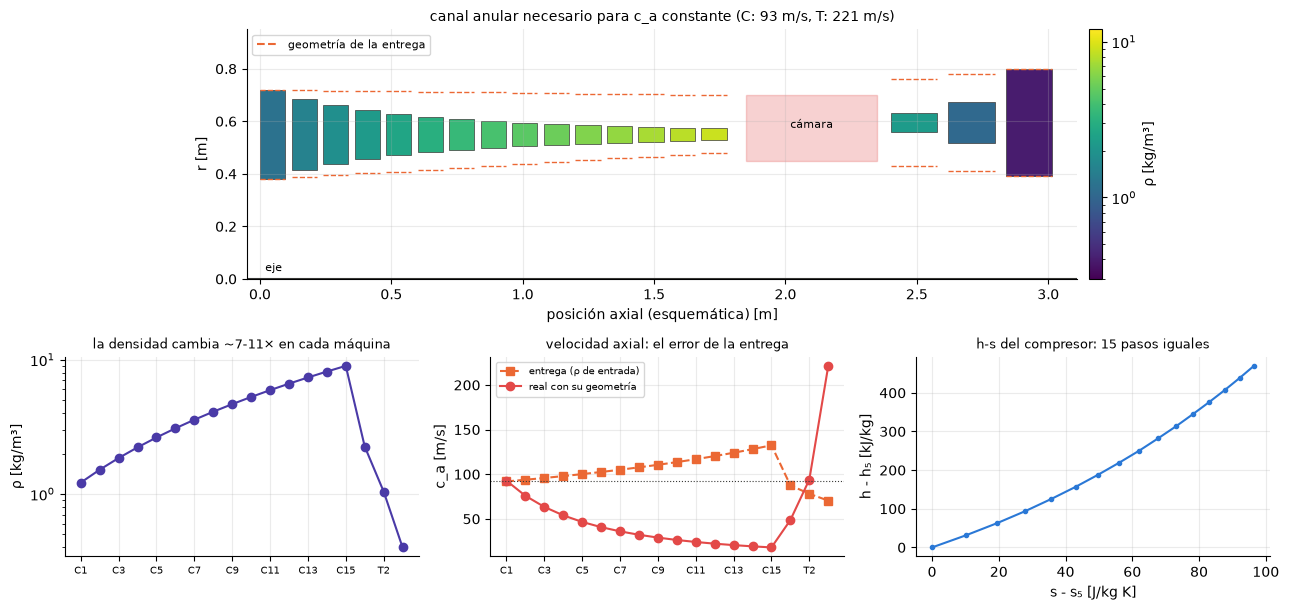

P = 62.0 MW | eta = 41.0 % | T8 = 596 °C | álabe C1/C15 = 34.0/4.6 cm, T1/T3 = 7.3/41.0 cm


In [9]:
def dibujar_canal(ax, DF, TG, titulo=""):
    # semicorte meridional a escala; color = densidad; trazo punteado = geometría de la entrega
    import matplotlib.colors as mcolors
    norm = mcolors.LogNorm(vmin=0.3, vmax=12); cmap = plt.get_cmap("viridis")
    x = 0.0
    for i, f in DF.iterrows():
        dx = 0.12 if f.maq == "C" else 0.22
        if f.maq == "T" and f.etapa == 1: x += 0.6
        ax.add_patch(Rectangle((x, f.r_hub), dx*0.8, f.r_tip - f.r_hub, color=cmap(norm(f.rho)), ec=COL["tinta"], lw=0.5))
        geo = GEO_ENTREGA_C[f.etapa - 1] if f.maq == "C" else GEO_ENTREGA_T[f.etapa - 1]
        ax.plot([x, x + dx*0.8], [geo[0]]*2, "--", color=COL["entrega"], lw=1); ax.plot([x, x + dx*0.8], [geo[1]]*2, "--", color=COL["entrega"], lw=1)
        x += dx
    xc = 15*0.12 + 0.05
    ax.add_patch(Rectangle((xc, 0.45), 0.5, 0.25, color=COL["gas"], alpha=0.25)); ax.text(xc + 0.25, 0.575, "cámara", ha="center", fontsize=8)
    ax.axhline(0, color=COL["tinta"], lw=1.5); ax.text(0.02, 0.03, "eje", fontsize=8)
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap); cb = plt.colorbar(sm, ax=ax, pad=0.01); cb.set_label("ρ [kg/m³]")
    ax.set_xlim(-0.05, x + 0.05); ax.set_ylim(0, 0.95); ax.set_aspect("equal"); ax.set_xlabel("posición axial (esquemática) [m]"); ax.set_ylabel("r [m]")
    ax.set_title(titulo, fontsize=10); ax.plot([], [], "--", color=COL["entrega"], label="geometría de la entrega"); ax.legend(loc="upper left", fontsize=8)

def w2_canal(m_exh, PI, TIT, eta_pc):
    r = ciclo_tg(m_exh=m_exh, PI=PI, TIT=TIT, eta_pc=eta_pc, eta_pt=ETA_PT, sub=(3, 12))
    DF, ca_c, ca_t = canal(r)
    fig = plt.figure(figsize=(13, 6.2)); gs = fig.add_gridspec(2, 3, height_ratios=[1.25, 1])
    ax = fig.add_subplot(gs[0, :]); dibujar_canal(ax, DF, r, f"canal anular necesario para c_a constante (C: {ca_c:.0f} m/s, T: {ca_t:.0f} m/s)")
    a1 = fig.add_subplot(gs[1, 0]); a2 = fig.add_subplot(gs[1, 1]); a3 = fig.add_subplot(gs[1, 2])
    xs = np.arange(len(DF)); lab = [f"{m}{e}" for m, e in zip(DF.maq, DF.etapa)]
    a1.semilogy(xs, DF.rho, "o-", color=COL["vapor"]); a1.set_xticks(xs[::2]); a1.set_xticklabels(lab[::2], fontsize=7); a1.set_ylabel("ρ [kg/m³]")
    a1.set_title("la densidad cambia ~7-11× en cada máquina", fontsize=9)
    a2.plot(xs, DF.ca_entrega, "s--", color=COL["entrega"], label="entrega (ρ de entrada)")
    a2.plot(xs, DF.ca_real_geo_entrega, "o-", color=COL["gas"], label="real con su geometría")
    a2.axhline(ca_c, color=COL["tinta"], lw=0.8, ls=":"); a2.set_xticks(xs[::2]); a2.set_xticklabels(lab[::2], fontsize=7)
    a2.set_ylabel("c_a [m/s]"); a2.legend(fontsize=7.5); a2.set_title("velocidad axial: el error de la entrega", fontsize=9)
    sC = r["comp"]["s"] - r["comp"]["s"][0]
    a3.plot(sC, r["comp"]["h"]/1e3 - r["comp"]["h"][0]/1e3, "o-", color=COL["agua"], ms=3, label="compresor (15)")
    a3.set_xlabel("s - s₅ [J/kg K]"); a3.set_ylabel("h - h₅ [kJ/kg]"); a3.set_title("h-s del compresor: 15 pasos iguales", fontsize=9)
    plt.tight_layout(); plt.show()
    print(f"P = {r['P']/1e6:.1f} MW | eta = {100*r['eta']:.1f} % | T8 = {r['T8'] - 273.15:.0f} °C | álabe C1/C15 = {DF.h[0]*100:.1f}/{DF.h[14]*100:.1f} cm,"
          f" T1/T3 = {DF.h[15]*100:.1f}/{DF.h[17]*100:.1f} cm")

_w2 = dict(m_exh=FloatSlider(value=135.5, min=100, max=150, step=0.5, description="ṁ escape [kg/s]", continuous_update=False),
           PI=FloatSlider(value=21.1, min=12, max=30, step=0.1, description="Π", continuous_update=False),
           TIT=FloatSlider(value=round(TIT0), min=1350, max=1750, step=5, description="TIT [K]", continuous_update=False),
           eta_pc=FloatSlider(value=0.90, min=0.84, max=0.93, step=0.005, description="η_pc", continuous_update=False))
display(VBox([HBox([_w2["m_exh"], _w2["PI"]]), HBox([_w2["TIT"], _w2["eta_pc"]]), interactive_output(w2_canal, _w2)]))

**Widget 2. El canal que exige la densidad.**
1. Compara las cajas (área necesaria) con los trazos naranjas (geometría de la entrega). Con la densidad real, el compresor debe terminar con álabes de ~5 cm, no de 22 cm.
2. Sube $\Pi$: el último álabe se acorta todavía más, y las fugas por la holgura de punta pesan cada vez más. Por eso los compresores de alta $\Pi$ terminan en etapas centrífugas o en carretes separados.
3. Sube la TIT: $\rho$ de la turbina baja y su canal se abre. La potencia sube, pero también la temperatura del metal (en la SGT-800 el enfriamiento de álabes lo resuelve).

## 5. Combustión 0D: el calor que mueve la planta

**Cámara de la turbina de gas.** Equilibrio químico adiabático a presión constante (HP) de aire a $T_6$ con gas natural. La relación combustible/aire $f$ se elige para alcanzar la TIT:

$$h_{mezcla}(T_6,f)=\frac{h_{aire}(T_6)+f\,h_{comb}}{1+f}=h_{prod}^{eq}(\mathrm{TIT},p_7).$$

La cámara opera muy pobre ($\lambda\approx 2.2$): el exceso de aire **enfría** los gases hasta lo que resiste el álabe.

**Hogar de biomasa (configuración B).** Con la composición elemental de EFB/PMF del artículo (base seca), el balance de átomos con exceso de aire $\lambda$ da los productos. El PCI tal como se quema (base húmeda, humedad $w$) es

$$\mathrm{PCI}_{bh}=\mathrm{PCI}_{bs}(1-w)-2.443\,w\quad[\mathrm{MJ/kg}],$$

y la temperatura adiabática sale de $h_{prod}(T_{ad})=h_{prod}(298\,K)+\mathrm{PCI}_{bh}/(1+\mathrm{AFR})$. La liberación de calor en la parrilla tiene dos tiempos:
- **volátiles** ($\chi_v$ = 75 %, SUPUESTO): arden en segundos. Es la cinética del NB08b.
- **carbonizado:** arde en la capa con $\tau_{char}$ = 90 s (SUPUESTO, orden de magnitud de parrillas; no proviene del artículo):

$$\dot Q_{rel}=\chi_v\,\dot m_f\,\mathrm{PCI}+\frac{M_c}{\tau_{char}}\mathrm{PCI},\qquad \frac{dM_c}{dt}=(1-\chi_v)\,\dot m_f-\frac{M_c}{\tau_{char}} .$$

In [10]:
# === Biomasa: balance elemental (composición del artículo, NB08b) ============================================
BIO = {"EFB": dict(C=44.03, H=6.20, O=41.31, N=0.59, S=0.24, LHV=17.66e6, w=0.4849),   # EFB: promedio de 7 estudios (NB08b)
       "PMF": dict(C=51.52, H=5.45, O=40.91, N=1.89, S=0.23, LHV=19.0e6, w=0.078)}
def biomasa(comb, lam=1.4, w=None):
    d = BIO[comb]; w = d["w"] if w is None else w
    nC, nH, nO, nN = d["C"]/100/12.011, d["H"]/100/1.008, d["O"]/100/15.999, d["N"]/100/14.007   # kmol/kg seco
    O2_est = nC + nH/4 - nO/2; nO2 = lam*O2_est
    AFR = nO2*(31.998 + 3.76*28.013)*(1 - w)                                   # kg aire/kg combustible húmedo
    X = {"CO2": nC, "H2O": nH/2 + w/(1 - w)/18.015, "N2": 3.76*nO2 + nN/2, "O2": nO2 - O2_est}
    LHV_ar = d["LHV"]*(1 - w) - 2.443e6*w
    g = ct.Solution("gri30.yaml"); g.TPX = 298.15, ct.one_atm, X; h0 = g.enthalpy_mass
    g.HP = h0 + LHV_ar/(1 + AFR), ct.one_atm; Tad = g.T
    return dict(AFR=AFR, X=X, LHV_ar=LHV_ar, Tad=Tad, co2_kg=nC*44.01*(1 - w), w=w)
def gas_natural(lam, T_aire=298.15, p=ct.one_atm, equilibrio=True):
    g = ct.Solution("gri30.yaml"); g.TP = T_aire, p; g.set_equivalence_ratio(1/lam, GN, AIRE_CT)
    if equilibrio: g.equilibrate("HP")
    return g

# --- Validación V4: llama adiabática estequiométrica CH4-aire (298 K, 1 atm, equilibrio) vs. 2226 K (Turns, 2012) ---
g = ct.Solution("gri30.yaml"); g.TP = 298.15, ct.one_atm; g.set_equivalence_ratio(1.0, "CH4", "O2:1, N2:3.76"); g.equilibrate("HP")
V4 = (g.T, 2226.0)
print(f"V4: T_ad CH4-aire = {g.T:.0f} K vs 2226 K (Turns) -> error {100*(g.T - 2226)/2226:+.2f} %")
g = ct.Solution("gri30.yaml"); AFR_ST_GN = g.stoich_air_fuel_ratio(GN, AIRE_CT, basis="mass")
lam_tg = 1/(TG["comb"]["far"]*AFR_ST_GN)                    # lambda = AFR_real / AFR_esteq
for comb in ["EFB", "PMF"]:
    b = biomasa(comb); print(f"{comb}: PCI_bh = {b['LHV_ar']/1e6:.2f} MJ/kg (humedad {100*b['w']:.1f} %), AFR(λ=1.4) = {b['AFR']:.2f}, T_ad = {b['Tad'] - 273.15:.0f} °C")
print(f"Cámara de la SGT-800: f = {TG['comb']['far']:.4f} (λ ≈ {lam_tg:.2f}); CO2 del gas natural = "
      f"{3.6e9*CO2_GN/(TG['eta']*LHV_GN):.0f} kg/MWh_e en ciclo simple")

V4: T_ad CH4-aire = 2225 K vs 2226 K (Turns) -> error -0.06 %
EFB: PCI_bh = 7.91 MJ/kg (humedad 48.5 %), AFR(λ=1.4) = 3.87, T_ad = 1257 °C
PMF: PCI_bh = 17.33 MJ/kg (humedad 7.8 %), AFR(λ=1.4) = 7.73, T_ad = 1619 °C
Cámara de la SGT-800: f = 0.0240 (λ ≈ 2.24); CO2 del gas natural = 492 kg/MWh_e en ciclo simple


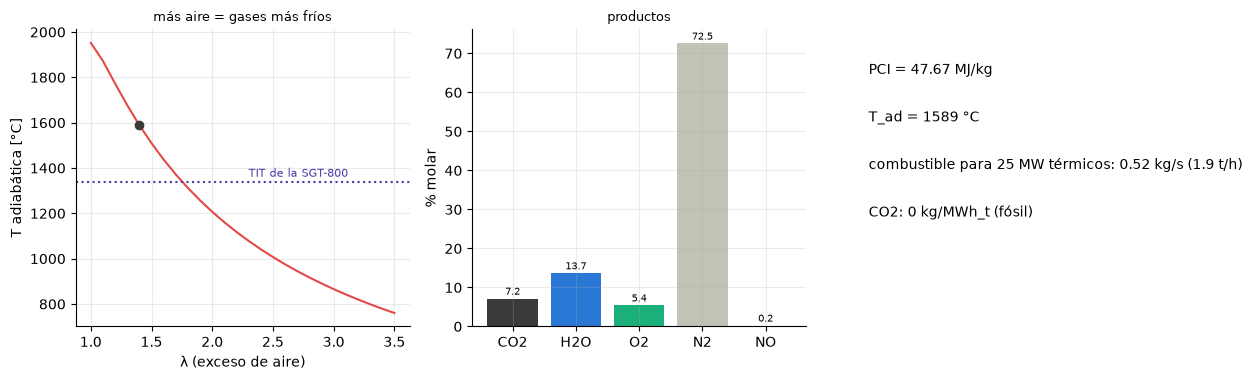

In [11]:
def w3_combustion(comb, lam, w, T_aire):
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
    lams = np.linspace(1.0, 3.5, 26)
    if comb == "gas natural":
        Ts = [gas_natural(l, T_aire).T for l in lams]; g = gas_natural(lam, T_aire); Tad = g.T
        X = {k: v for k, v in g.mole_fraction_dict(1e-3).items()}; LHV = LHV_GN; co2 = CO2_GN
    else:
        Ts = [biomasa(comb, l, w)["Tad"] for l in lams]; b = biomasa(comb, lam, w); Tad = b["Tad"]
        tot = sum(b["X"].values()); X = {k: v/tot for k, v in b["X"].items()}; LHV = b["LHV_ar"]; co2 = b["co2_kg"]
    axs[0].plot(lams, np.array(Ts) - 273.15, color=COL["gas"]); axs[0].plot(lam, Tad - 273.15, "o", color=COL["tinta"])
    axs[0].axhline(TIT0 - 273.15, ls=":", color=COL["vapor"]); axs[0].text(2.3, TIT0 - 250, "TIT de la SGT-800", fontsize=8, color=COL["vapor"])
    axs[0].set_xlabel("λ (exceso de aire)"); axs[0].set_ylabel("T adiabática [°C]"); axs[0].set_title("más aire = gases más fríos", fontsize=9.5)
    ks = [k for k in ["CO2", "H2O", "O2", "N2", "CO", "NO", "OH"] if k in X]
    axs[1].bar(ks, [100*X[k] for k in ks], color=[COL["tinta"], COL["agua"], COL["red"], COL["metal"], COL["aviso"], COL["tibio"], COL["vapor"]][:len(ks)])
    axs[1].set_ylabel("% molar"); axs[1].set_title("productos", fontsize=9.5)
    for i, k in enumerate(ks): axs[1].text(i, 100*X[k] + 1, f"{100*X[k]:.1f}", ha="center", fontsize=7.5)
    Q = 25e6; mf = Q/LHV
    axs[2].axis("off")
    for i, s in enumerate([f"PCI = {LHV/1e6:.2f} MJ/kg", f"T_ad = {Tad - 273.15:.0f} °C",
                           f"combustible para 25 MW térmicos: {mf:.2f} kg/s ({3.6*mf:.1f} t/h)",
                           f"CO2: {co2*3600/LHV*1e6/1e3:.0f} kg/MWh_t " + ("(biogénico)" if comb != "gas natural" else "(fósil)")]):
        axs[2].text(0, 0.85 - 0.16*i, s, fontsize=10, transform=axs[2].transAxes)
    plt.tight_layout(); plt.show()
_w3 = dict(comb=ToggleButtons(options=["gas natural", "EFB", "PMF"], value="gas natural", description="combustible"),
           lam=FloatSlider(value=1.4, min=1.0, max=3.5, step=0.05, description="λ", continuous_update=False),
           w=FloatSlider(value=0.4849, min=0.0, max=0.6, step=0.01, description="humedad w", continuous_update=False),
           T_aire=FloatSlider(value=298.15, min=298.15, max=800.0, step=10, description="T aire [K]", continuous_update=False))
display(VBox([_w3["comb"], HBox([_w3["lam"], _w3["w"], _w3["T_aire"]]), interactive_output(w3_combustion, _w3)]))

**Widget 3. Combustible, aire y humedad.**
1. Con gas natural, $T_{aire}$ = 741 K (salida del compresor) y λ ≈ 2.2, la llama sale a la TIT de la SGT-800.
2. Con **EFB** (48 % de humedad), el PCI cae de 17.7 a 7.9 MJ/kg: el agua se lleva su calor latente por la chimenea. Baja $w$ a 10 % (secado previo) y mira cuánto sube $T_{ad}$.
3. El CO₂ de la biomasa es **biogénico**: se reabsorbe en el siguiente ciclo de cultivo (Lección 3). El del gas natural es fósil.

## 6. La caldera de recuperación (HRSG) y el pinch

Los gases (8) ceden calor en contraflujo al sobrecalentador (SH), al evaporador (EV) y al economizador (ECO). Como el agua **hierve a temperatura constante**, el perfil del agua tiene una meseta. El punto más estrecho entre las dos curvas está a la salida del EV en el lado gas: es el **pinch** $\Delta T_{pp}$. Fijado el pinch, el caudal de vapor sale de un balance sobre SH + EV:

$$\dot m_s=\frac{\dot m_g\,[h_g(T_8)-h_g(T_{sat}+\Delta T_{pp})]}{h_3-h_{ECO,sal}},\qquad h_{ECO,sal}=h_l(p,\,T_{sat}-\Delta T_{ap}),$$

y el ECO fija la temperatura de chimenea. Un pinch pequeño recupera más calor pero exige más área (costo).

> 🎓 **Hallazgo en la entrega (verificado con CoolProp).** La caldera de serpentín se modeló con $c_p$ constante, una correlación de Watson para $h_{fg}$ y la ecuación de Antoine. El calor por kilogramo de agua resultó 2841 kJ/kg, cuando el real a 12 MPa/540 °C desde 44 °C es **3256 kJ/kg (−13 %)**. Con ese error, 21.68 kg/s de vapor parecen caber en los 61.6 MW disponibles. En realidad necesitan **70.6 MW**: el perfil de agua **cruza** al del gas (violación de la 2.ª ley). El widget lo muestra con el punto de la entrega.

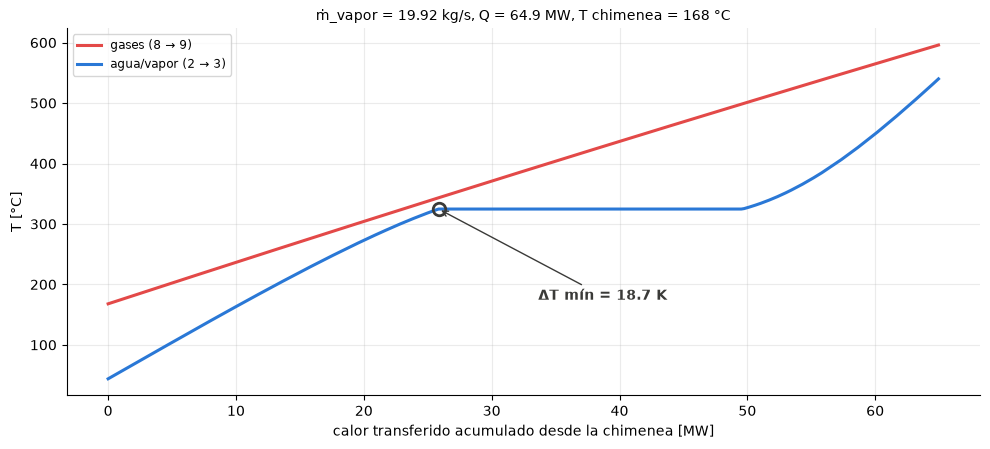

In [12]:
GAS_EXH = GasTab(Y_EXH, "Y")
def hrsg_diseno(p=12e6, T3=813.15, pinch=10.0, approach=10.0, mg=135.5, T8=None, h_fw=None, ms=None, gas=GAS_EXH):
    # balance estacionario por secciones (SH, EV, ECO); si ms se impone, se busca dónde se viola la 2.a ley
    T8 = TG["T8"] if T8 is None else T8; s = sat(p); Ts = s["Ts"]
    h_fw = h_l(p, 317.0) if h_fw is None else h_fw
    h3 = h_v(p, T3); h_eco = h_l(p, Ts - approach)
    if ms is None:
        ms = mg*(gas.hT(T8) - gas.hT(Ts + pinch))/(h3 - h_eco)
    # perfiles T-Q (Q acumulado desde la chimenea)
    Q_eco, Q_ev, Q_sh = ms*(h_eco - h_fw), ms*(s["hs"] - h_eco), ms*(h3 - s["hs"]); Qt = Q_eco + Q_ev + Q_sh
    Q = np.linspace(0, Qt, 300); Tw = np.empty_like(Q)
    for i, q in enumerate(Q):
        h = h_fw + q/ms
        Tw[i] = T_ph_l(p, h) if h < s["hw"] else (Ts if h <= s["hs"] else T_ph_v(p, h))
    hg_in = gas.hT(T8); Tg = np.array([gas.Th(hg_in - (Qt - q)/mg) for q in Q])
    dT = Tg - Tw; T_stack = Tg[0]
    return dict(ms=ms, Q=Q, Tw=Tw, Tg=Tg, dTmin=dT.min(), Q_dTmin=Q[np.argmin(dT)], T_stack=T_stack, Qt=Qt,
                Q_disp=mg*(hg_in - gas.hT(Ts + pinch)) + Q_eco, viola=dT.min() < 0)

def w4_pinch(p_MPa, T3_C, pinch, ms_forzado):
    d = hrsg_diseno(p=p_MPa*1e6, T3=T3_C + 273.15, pinch=pinch, ms=None if ms_forzado == 0 else ms_forzado)
    fig, ax = plt.subplots(figsize=(10, 4.6))
    ax.plot(d["Q"]/1e6, d["Tg"] - 273.15, color=COL["gas"], lw=2.2, label="gases (8 → 9)")
    ax.plot(d["Q"]/1e6, d["Tw"] - 273.15, color=COL["agua"], lw=2.2, label="agua/vapor (2 → 3)")
    if d["viola"]:
        m = d["Tg"] < d["Tw"]; ax.fill_between(d["Q"]/1e6, d["Tg"] - 273.15, d["Tw"] - 273.15, where=m, color=COL["aviso"], alpha=0.3,
                                               label="VIOLACIÓN de la 2.ª ley (el gas sería más frío que el agua)")
    yq = np.interp(d['Q_dTmin'], d['Q'], d['Tw']) - 273.15
    ax.plot(d["Q_dTmin"]/1e6, yq, "o", ms=9, mfc="none", mec=COL["aviso"] if d["viola"] else COL["tinta"], mew=2)
    ax.annotate(f"ΔT mín = {d['dTmin']:.1f} K", xy=(d["Q_dTmin"]/1e6, yq), xytext=(d["Q_dTmin"]/1e6 + 0.12*d["Qt"]/1e6, yq - 150),
                arrowprops=dict(arrowstyle="->", color=COL["tinta"]), fontsize=10, color=COL["aviso"] if d["viola"] else COL["tinta"], weight="bold")
    ax.set_xlabel("calor transferido acumulado desde la chimenea [MW]"); ax.set_ylabel("T [°C]"); ax.legend(loc="upper left", fontsize=8.5)
    ax.set_title(f"ṁ_vapor = {d['ms']:.2f} kg/s, Q = {d['Qt']/1e6:.1f} MW, T chimenea = {d['T_stack'] - 273.15:.0f} °C", fontsize=10)
    plt.tight_layout(); plt.show()
    if d["viola"]: print("⚠ El caudal impuesto no cabe: la caldera necesitaría un gas más caliente que el disponible. Reduzca ṁ.")
_w4 = dict(p_MPa=FloatSlider(value=12, min=3, max=14, step=0.5, description="p evap [MPa]", continuous_update=False),
           T3_C=FloatSlider(value=540, min=400, max=580, step=5, description="T3 [°C]", continuous_update=False),
           pinch=FloatSlider(value=10, min=3, max=40, step=1, description="pinch [K]", continuous_update=False),
           ms_forzado=Dropdown(options=[("según pinch", 0), ("entrega: 21.68 kg/s", 21.68), ("18 kg/s", 18.0)], value=0, description="ṁ_vapor"))
display(VBox([HBox([_w4["p_MPa"], _w4["T3_C"]]), HBox([_w4["pinch"], _w4["ms_forzado"]]), interactive_output(w4_pinch, _w4)]))

**Widget 4. Pinch y violación de la 2.ª ley.**
1. Selecciona **"entrega: 21.68 kg/s"**: aparece la zona roja. Ese caudal exigiría gases más fríos que el agua.
2. Baja la presión de evaporación: la meseta baja, el pinch se aleja de la chimenea, se genera **más** vapor y menos calor sale por la chimenea. A cambio, cada kg de vapor rinde menos trabajo en la turbina, y esa es la razón de las HRSG de 2 y 3 presiones.
3. Reduce el pinch a 3 K: se gana poco vapor a cambio de un área mucho mayor.

## 7. Dinámica del domo: el modelo de Åström y Bell

La caldera de la entrega se modeló con un retardo de primer orden de constante **impuesta** ($\tau$ = 100 s). Aquí la dinámica sale de los balances de masa y energía del circuito de circulación natural (Åström & Bell, 2000). Las constantes de tiempo resultan de las masas de agua, vapor y metal.

**Estados:** presión del domo $p$, volumen total de agua $V_{wt}$, calidad a la salida de los elevadores $\alpha_r$ y volumen de vapor bajo la superficie $V_{sd}$.

$$
\begin{aligned}
e_{11}\dot V_{wt}+e_{12}\dot p&=q_f-q_s &&\text{(masa global)}\\
e_{21}\dot V_{wt}+e_{22}\dot p&=Q+q_fh_f-q_sh_s &&\text{(energía global)}\\
e_{32}\dot p+e_{33}\dot\alpha_r&=Q-\alpha_rh_cq_{dc} &&\text{(elevadores)}\\
e_{42}\dot p+e_{43}\dot\alpha_r+e_{44}\dot V_{sd}&=\tfrac{\rho_s}{T_d}(V_{sd}^0-V_{sd})+\tfrac{h_f-h_w}{h_c}q_f &&\text{(vapor en el domo)}
\end{aligned}
$$

Términos auxiliares:
- **circulación natural:** $k\,q_{dc}^2/2=\rho_wA_{dc}(\rho_w-\rho_s)g\bar\alpha_vV_r$;
- **fracción de vacío media:** $\bar\alpha_v=\frac{\rho_w}{\rho_w-\rho_s}\big[1-\frac{\rho_s}{(\rho_w-\rho_s)\alpha_r}\ln(1+\frac{\rho_w-\rho_s}{\rho_s}\alpha_r)\big]$;
- **nivel:** $\ell=(V_{wd}+V_{sd})/A_d$, con $V_{wd}=V_{wt}-V_{dc}-(1-\bar\alpha_v)V_r$.

Los coeficientes $e_{ij}$ dependen de $\rho$, $h$ y sus derivadas sobre la curva de saturación, todas tomadas de CoolProp.

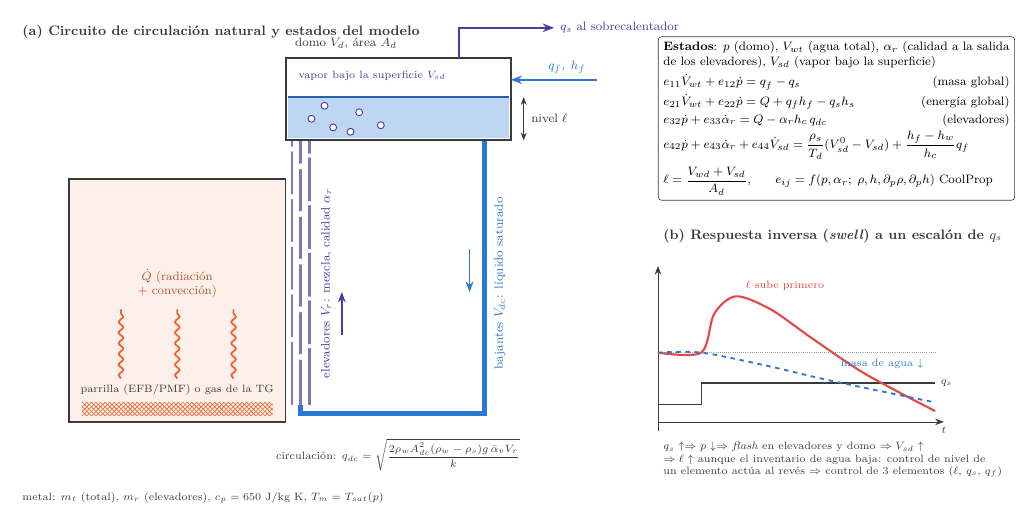

**Por qué el nivel engaña (*swell*).** Si sube la demanda de vapor, la presión cae, el agua del domo y de los elevadores hierve de golpe (*flash*) y las burbujas hinchan la mezcla. El nivel **sube** aunque el inventario de agua **baje**. Un control que solo mira el nivel cerraría el agua en el peor momento. Por eso se usa el control de **3 elementos**: nivel, caudal de vapor y caudal de agua.

In [13]:
# === Modelo de Åström-Bell: una sola función de derivadas, usada aquí y en la planta completa (§10) ==========
def av_mean(ar, rw, rs):
    eta = (rw - rs)/rs*max(ar, 1e-6)
    return rw/(rw - rs)*(1 - math.log1p(eta)/eta)

def domo_derivadas(x, A, Q, qf, hf, qs):
    Vwt, p, ar, Vsd = x
    s = sat(p); rw, rs, hw, hs = s["rw"], s["rs"], s["hw"], s["hs"]
    drw, drs, dhw, dhs, dTs = s["drw"], s["drs"], s["dhw"], s["dhs"], s["dTs"]
    hc = hs - hw; Vst = A["Vt"] - Vwt; Vr = A["Vr"]
    av = av_mean(ar, rw, rs); dp_ = p*1e-4; da = max(ar*1e-4, 1e-7); s2 = sat(p + dp_)
    av_p = (av_mean(ar, s2["rw"], s2["rs"]) - av)/dp_; av_a = (av_mean(ar + da, rw, rs) - av)/da
    qdc = math.sqrt(max(2*rw*A["Adc"]*(rw - rs)*G*av*Vr/A["k"], 0.0))
    Vwd = Vwt - A["Vdc"] - (1 - av)*Vr
    e11, e12 = rw - rs, Vst*drs + Vwt*drw
    e21 = rw*hw - rs*hs
    e22 = Vst*(hs*drs + rs*dhs) + Vwt*(hw*drw + rw*dhw) - A["Vt"] + A["mt"]*A["Cp"]*dTs
    e32 = Vr*(hc*(1 - ar)*(drs*av + rs*av_p) + rw*(1 - av)*dhw - ar*hc*(drw*(1 - av) - rw*av_p) + rs*av*dhs - 1) + A["mr"]*A["Cp"]*dTs
    e33 = ((1 - ar)*rs + ar*rw)*hc*Vr*av_a
    e42 = Vsd*drs + (rs*Vsd*dhs + rw*Vwd*dhw - Vsd - Vwd + A["md"]*A["Cp"]*dTs)/hc + ar*(1 + A["beta"])*Vr*((1 - av)*drw + av*drs + (rs - rw)*av_p)
    e43 = ar*(1 + A["beta"])*Vr*(rs - rw)*av_a
    b1, b2 = qf - qs, Q + qf*hf - qs*hs
    det = e11*e22 - e12*e21
    dVwt = (b1*e22 - e12*b2)/det; dp = (e11*b2 - e21*b1)/det
    dar = (Q - ar*hc*qdc - e32*dp)/e33
    dVsd = (rs/A["Td"]*(A["Vsd0"] - Vsd) + (hf - hw)/hc*qf - e42*dp - e43*dar)/rs
    if Vsd <= 0.0 and dVsd < 0.0: dVsd = 0.0
    return [dVwt, dp, dar, dVsd]

def nivel_domo(x, A):
    Vwt, p, ar, Vsd = x; s = sat(p); av = av_mean(ar, s["rw"], s["rs"])
    return (Vwt - A["Vdc"] - (1 - av)*A["Vr"] + Vsd)/A["Ad"]

def domo_equilibrio(A, p0, Q0, hf, qdc0, Vsd_ss, Vwt0):
    # parámetros que dependen del punto de operación: A_dc (da q_dc0) y V_sd^0 (da V_sd de equilibrio)
    s = sat(p0); hc = s["hs"] - s["hw"]; qs0 = Q0/(s["hs"] - hf); ar = Q0/(hc*qdc0); av = av_mean(ar, s["rw"], s["rs"])
    A = dict(A); A["Vt"] = A["Vd"] + A["Vr"] + A["Vdc"]
    A["Adc"] = A["k"]*qdc0**2/(2*s["rw"]*(s["rw"] - s["rs"])*G*av*A["Vr"])
    A["Vsd0"] = Vsd_ss - A["Td"]*(hf - s["hw"])*qs0/(hc*s["rs"])
    return A, [Vwt0, p0, ar, Vsd_ss], qs0

# Parámetros de la planta sueca P16-G16 usados en las simulaciones del informe (TFRT-7577, p. 18)
AB_TEXTO = dict(Vd=40.0, Vr=37.0, Vdc=11.0, Ad=20.0, mt=300e3, mr=160e3, md=0.0, k=25.0, beta=0.3, Td=12.0, Cp=650.0)
AB_APENDICE = dict(Vd=37.0, Vr=37.0, Vdc=11.0, Ad=23.0, mt=300e3, mr=100e3, k=200.0, beta=0.3)
HF_AB = CP.PropsSI("H", "T", 240 + 273.15, "P", 9e6, "Water")     # SUPUESTO: agua de alimentación a 240 °C (no publicada)
display(pd.DataFrame({"texto (p. 18)": AB_TEXTO, "apéndice A": AB_APENDICE}).T.fillna("—"))
print("El informe usa valores distintos en el texto y en el apéndice; se toman los del texto, que generaron sus figuras.")

,Vd,Vr,Vdc,Ad,mt,mr,md,k,beta,Td,Cp
texto (p. 18),40.0,37.0,11.0,20.0,300000.0,160000.0,0.0,25.0,0.3,12.0,650.0
apéndice A,37.0,37.0,11.0,23.0,300000.0,100000.0,—,200.0,0.3,—,—


El informe usa valores distintos en el texto y en el apéndice; se toman los del texto, que generaron sus figuras.


In [14]:
# === Paso 1 (modelo vs. modelo): la masa metálica efectiva que reproduce las Figs. 4 y 5 del informe ===========
# Figs. 4/5 (carga media, p0 = 8.5 MPa): +10 MW de combustible -> p sube ~0.30 MPa en 150 s; +10 kg/s de vapor -> p cae ~0.50 MPa.
def escalon_AB(A0, tipo, mt, md=0.0, Q0=85e6, t_fin=200.0):
    A = dict(A0); A["mt"], A["md"] = mt, md
    A, x0, qs0 = domo_equilibrio(A, 8.5e6, Q0, HF_AB, 1200.0, 5.0, 57.0)
    Qf = (lambda t: Q0 + 10e6*(t > 50)) if tipo == "Q" else (lambda t: Q0)
    qsf = (lambda t: qs0 + 10*(t > 50)) if tipo == "qs" else (lambda t: qs0)
    sol = solve_ivp(lambda t, x: domo_derivadas(x, A, Qf(t), qs0, HF_AB, qsf(t)), (0, t_fin), x0, max_step=0.5,
                    method="LSODA", dense_output=True)
    tt = np.linspace(0, t_fin, 401); X = sol.sol(tt); l0 = nivel_domo(x0, A)
    return tt, X, np.array([nivel_domo(X[:, i], A) - l0 for i in range(len(tt))]), A
REF_FIG45 = {"Q": 0.30e6, "qs": -0.50e6}
def err_mt(mt):
    return [(escalon_AB(AB_TEXTO, k, mt)[1][1, -1] - 8.5e6 - v)/abs(v) for k, v in REF_FIG45.items()]
MT_EF = float(least_squares(lambda x: err_mt(x[0]*1e5), [4.0]).x[0]*1e5)
for mt in (300e3, MT_EF):
    e = err_mt(mt); print(f"m_t = {mt/1e3:5.0f} t: error en Δp(200 s) Fig. 4 = {100*e[0]:+5.1f} %, Fig. 5 = {100*e[1]:+5.1f} %")
AB = dict(AB_TEXTO); AB["mt"] = MT_EF
print(f"-> masa metálica efectiva m_t = {MT_EF/1e3:.0f} t (el informe declara 300 t; sus ajustes cuadráticos de propiedades difieren de CoolProp).")
print("   m_d = 0: el metal del domo no condensa el vapor bajo la superficie en la escala de T_d (con m_d = m_t - m_r el swell sale con signo errado).")

m_t =   300 t: error en Δp(200 s) Fig. 4 = +43.1 %, Fig. 5 = -26.0 %
m_t =   529 t: error en Δp(200 s) Fig. 4 =  +5.6 %, Fig. 5 =  +6.4 %
-> masa metálica efectiva m_t = 529 t (el informe declara 300 t; sus ajustes cuadráticos de propiedades difieren de CoolProp).
   m_d = 0: el metal del domo no condensa el vapor bajo la superficie en la escala de T_d (con m_d = m_t - m_r el swell sale con signo errado).


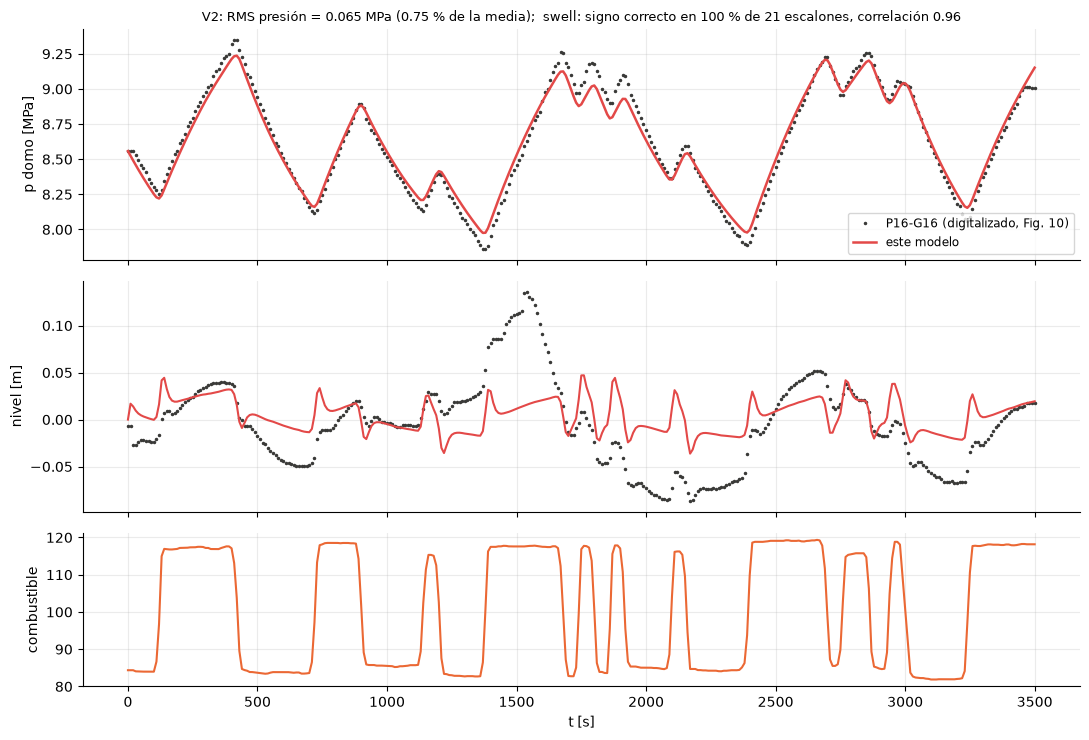

V2: RMS de presión = 0.065 MPa = 0.75 % de la media; swell con signo correcto en 100 % de 21 escalones (correlación 0.96)
Calibrado (2 parámetros, como hicieron los autores con sus transductores): Q = 1.101·combustible [MW], K_v = 7.47 kg/s/MPa
Salto de nivel 30 s tras subir el combustible: planta +3.2 cm, modelo +4.5 cm; al bajar: planta -3.4 cm, modelo -4.2 cm
La deriva lenta del nivel la produce el agua de alimentación, que el operador corrigió a mano y que la figura no publica:
por eso el nivel se valida en sus saltos rápidos (swell), no punto a punto.


In [15]:
# === Paso 2 (modelo vs. PLANTA): Fig. 10 de Åström & Bell, escalones de combustible en la P16-G16 ================
D10 = json.load(open(os.path.join("data", "astrom_bell_fig10.json")))
t10, F10, P10, L10 = (np.array(D10[k]) for k in ("t_s", "combustible", "p_MPa", "nivel_m"))
def sim_fig10(kappa, Kv, Kp=20.0):
    # Q = kappa*combustible (MW); valvula de vapor fija: q_s = Kv*p (MPa); agua: correccion lenta del operador (SUPUESTO)
    Qf = lambda t: kappa*1e6*np.interp(t, t10, F10)
    A, x0, qs0 = domo_equilibrio(AB, P10[0]*1e6, Qf(0), HF_AB, 1200.0, 5.0, 57.0)
    l0 = nivel_domo(x0, A)
    def f(t, x):
        qs = Kv*x[1]/1e6; qf = qs + Kp*(l0 - nivel_domo(x, A))
        return domo_derivadas(x, A, Qf(t), qf, HF_AB, qs)
    sol = solve_ivp(f, (0, t10[-1]), x0, t_eval=t10, max_step=2.0, method="LSODA")
    return sol.y[1]/1e6, np.array([nivel_domo(sol.y[:, i], A) - l0 for i in range(len(t10))])
if "fig10" in CACHE and not RECALCULAR: KAP, KV = CACHE["fig10"]["kappa"], CACHE["fig10"]["Kv"]
else:
    _r = least_squares(lambda th: sim_fig10(*th)[0] - P10, [1.0, 7.0], diff_step=1e-3); KAP, KV = map(float, _r.x)
    CACHE["fig10"] = dict(kappa=KAP, Kv=KV)
P10m, L10m = sim_fig10(KAP, KV)
def saltos(l, F=F10):
    idx = np.where(np.abs(np.diff(F)) > 8)[0]; st = []
    for i in idx:
        if not st or i - st[-1] > 4: st.append(i)
    st = np.array(st); a, b = np.maximum(st - 1, 0), np.minimum(st + 3, len(F) - 1)
    return l[b] - l[a], np.sign(F[b] - F[a])
jd, sg = saltos(L10); jm, _ = saltos(L10m)
rms_p = np.sqrt(np.mean((P10m - P10)**2))
V2 = dict(rms_p=rms_p, rms_p_pct=100*rms_p/P10.mean(), signo=np.mean(np.sign(jd) == np.sign(jm)), corr=np.corrcoef(jd, jm)[0, 1],
          sube_d=jd[sg > 0].mean(), sube_m=jm[sg > 0].mean(), baja_d=jd[sg < 0].mean(), baja_m=jm[sg < 0].mean(), n=len(jd))
fig, ax = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1.2, 0.8]})
ax[0].plot(t10, P10, ".", ms=3, color=COL["medido"], label="P16-G16 (digitalizado, Fig. 10)"); ax[0].plot(t10, P10m, color=COL["modelo"], lw=1.8, label="este modelo")
ax[0].set_ylabel("p domo [MPa]"); ax[0].legend(fontsize=8.5, loc="lower right")
ax[1].plot(t10, L10, ".", ms=3, color=COL["medido"]); ax[1].plot(t10, L10m, color=COL["modelo"], lw=1.5); ax[1].set_ylabel("nivel [m]")
ax[2].plot(t10, F10, color=COL["tibio"]); ax[2].set_ylabel("combustible"); ax[2].set_xlabel("t [s]")
ax[0].set_title(f"V2: RMS presión = {rms_p:.3f} MPa ({V2['rms_p_pct']:.2f} % de la media);  swell: signo correcto en {100*V2['signo']:.0f} % de "
                f"{V2['n']} escalones, correlación {V2['corr']:.2f}", fontsize=9.5)
plt.tight_layout(); plt.show()
print(f"V2: RMS de presión = {rms_p:.3f} MPa = {V2['rms_p_pct']:.2f} % de la media; swell con signo correcto en {100*V2['signo']:.0f} % de {V2['n']} escalones (correlación {V2['corr']:.2f})")
print(f"Calibrado (2 parámetros, como hicieron los autores con sus transductores): Q = {KAP:.3f}·combustible [MW], K_v = {KV:.2f} kg/s/MPa")
print(f"Salto de nivel 30 s tras subir el combustible: planta {V2['sube_d']*100:+.1f} cm, modelo {V2['sube_m']*100:+.1f} cm; al bajar: "
      f"planta {V2['baja_d']*100:+.1f} cm, modelo {V2['baja_m']*100:+.1f} cm")
print("La deriva lenta del nivel la produce el agua de alimentación, que el operador corrigió a mano y que la figura no publica:")
print("por eso el nivel se valida en sus saltos rápidos (swell), no punto a punto.")

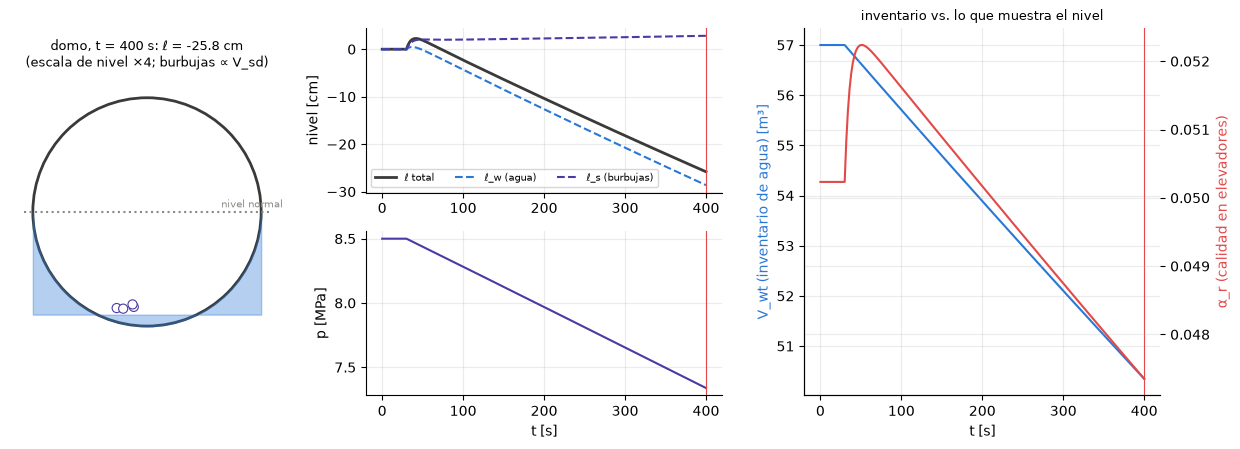

In [16]:
# === Widget 5: shrink & swell en el domo de la P16-G16 ========================================================
def sim_W5(pert, mag, Q0, ctrl, t_fin=400.0):
    A, x0, qs0 = domo_equilibrio(AB, 8.5e6, Q0*1e6, HF_AB, 1200.0*Q0/85.0, 5.0, 57.0)
    l0 = nivel_domo(x0, A); Kp, Ti = 0.4*qs0/0.1, 150.0
    step = lambda t: mag*(t > 30)
    def f(t, z):
        x, xi = z[:4], z[4]; l = nivel_domo(x, A) - l0
        qs = qs0 + (step(t) if pert == "q_s (vapor)" else 0.0)
        Q = Q0*1e6 + (1e6*step(t) if pert == "Q (combustible)" else 0.0)
        if ctrl == "lazo abierto": qf = qs0 + (step(t) if pert == "q_f (agua)" else 0.0)
        elif ctrl == "1 elemento (nivel)": qf = max(qs0 - Kp*l + xi, 0)
        else: qf = max(qs - Kp*l + xi, 0)
        return domo_derivadas(x, A, Q, qf, HF_AB, qs) + [(-Kp*l/Ti) if ctrl != "lazo abierto" else 0.0]
    tt = np.linspace(0, t_fin, 201)
    sol = solve_ivp(f, (0, t_fin), list(x0) + [0.0], t_eval=tt, max_step=1.0, method="LSODA")
    X = sol.y[:4]; L = np.array([nivel_domo(X[:, i], A) - l0 for i in range(len(tt))])
    Lw = np.array([(X[0, i] - A["Vdc"] - (1 - av_mean(X[2, i], *[sat(X[1, i])[k] for k in ("rw", "rs")]))*A["Vr"])/A["Ad"] for i in range(len(tt))])
    return dict(t=tt, X=X, L=L, Lw=Lw - Lw[0], Ls=(X[3] - X[3, 0])/A["Ad"], A=A)
_W5C = {}
def w5_domo(pert, mag, Q0, ctrl, k):
    key = (pert, mag, Q0, ctrl)
    if key not in _W5C: _W5C.clear(); _W5C[key] = sim_W5(pert, mag, Q0, ctrl)
    S = _W5C[key]; i = min(k, len(S["t"]) - 1); t = S["t"][i]
    fig = plt.figure(figsize=(12.5, 4.6)); gs = fig.add_gridspec(2, 3, width_ratios=[1.0, 1.3, 1.3])
    ax = fig.add_subplot(gs[:, 0])
    l = S["L"][i]; vsd = S["X"][3, i]
    ax.add_patch(Circle((0, 0), 1.0, fc="white", ec=COL["tinta"], lw=2))
    yl = np.clip(l*4.0, -0.9, 0.9)
    xs = np.linspace(-1, 1, 200); ys = -np.sqrt(np.clip(1 - xs**2, 0, 1))
    ax.fill_between(xs, ys, np.minimum(yl, np.sqrt(np.clip(1 - xs**2, 0, 1))), color=COL["agua"], alpha=0.35)
    rng = np.random.default_rng(int(t)); nb = int(12*vsd/5.0)
    for _ in range(nb):
        bx = rng.uniform(-0.8, 0.8); by = rng.uniform(-0.85, max(yl - 0.05, -0.8))
        if bx**2 + by**2 < 0.85: ax.add_patch(Circle((bx, by), 0.04, fc="white", ec=COL["vapor"], lw=0.8))
    ax.axhline(0, xmin=0.05, xmax=0.95, ls=":", color=COL["gris"]); ax.text(0.65, 0.04, "nivel normal", fontsize=7.5, color=COL["gris"])
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"domo, t = {t:.0f} s: ℓ = {100*l:+.1f} cm\n(escala de nivel ×4; burbujas ∝ V_sd)", fontsize=9)
    a1 = fig.add_subplot(gs[0, 1]); a1.plot(S["t"], 100*S["L"], color=COL["tinta"], lw=2, label="ℓ total")
    a1.plot(S["t"], 100*S["Lw"], "--", color=COL["agua"], label="ℓ_w (agua)"); a1.plot(S["t"], 100*S["Ls"], "--", color=COL["vapor"], label="ℓ_s (burbujas)")
    a1.axvline(t, color=COL["aviso"], lw=0.8); a1.set_ylabel("nivel [cm]"); a1.legend(fontsize=7.5, ncol=3)
    a2 = fig.add_subplot(gs[1, 1]); a2.plot(S["t"], S["X"][1]/1e6, color=COL["vapor"]); a2.axvline(t, color=COL["aviso"], lw=0.8)
    a2.set_ylabel("p [MPa]"); a2.set_xlabel("t [s]")
    a3 = fig.add_subplot(gs[:, 2]); a3.plot(S["t"], S["X"][0], color=COL["agua"]); a3.set_ylabel("V_wt (inventario de agua) [m³]", color=COL["agua"])
    a3b = a3.twinx(); a3b.plot(S["t"], S["X"][2], color=COL["gas"]); a3b.set_ylabel("α_r (calidad en elevadores)", color=COL["gas"])
    a3.axvline(t, color=COL["aviso"], lw=0.8); a3.set_xlabel("t [s]"); a3.set_title("inventario vs. lo que muestra el nivel", fontsize=9)
    plt.tight_layout(); plt.show()
_w5 = dict(pert=ToggleButtons(options=["q_s (vapor)", "Q (combustible)", "q_f (agua)"], value="q_s (vapor)", description="escalón en"),
           mag=FloatSlider(value=10, min=-15, max=15, step=1, description="magnitud", continuous_update=False),
           Q0=FloatSlider(value=85, min=45, max=120, step=5, description="carga Q0 [MW]", continuous_update=False),
           ctrl=ToggleButtons(options=["lazo abierto", "1 elemento (nivel)", "3 elementos"], value="lazo abierto", description="control"),
           k=IntSlider(value=200, min=0, max=200, description="instante"))
_p5 = Play(value=200, min=0, max=200, step=2, interval=120); jslink((_p5, "value"), (_w5["k"], "value"))
display(VBox([_w5["pert"], HBox([_w5["mag"], _w5["Q0"]]), _w5["ctrl"], HBox([_p5, _w5["k"]]), interactive_output(w5_domo, _w5)]))

**Widget 5. *Shrink & swell*.** Pulsa *play* para animar el domo.
1. **+10 kg/s de vapor en lazo abierto:** el nivel sube primero (las burbujas $\ell_s$ crecen) mientras el inventario $V_{wt}$ ya baja.
2. **Control de 1 elemento:** al ver el nivel alto, el controlador reduce el agua justo cuando falta, y el nivel cae después mucho más.
3. **3 elementos:** el caudal de vapor entra como anticipativo y el agua sigue al vapor desde el primer instante.
4. Baja la carga $Q_0$: el swell es mayor a baja carga, como reporta el informe, porque hay menos vapor en los elevadores para amortiguar el *flash*.

## 8. Turbina de vapor y bomba de alimentación

**Turbina de vapor.** En la expansión de 12 MPa a 7 kPa el volumen específico crece ~700 veces, mucho más que en la turbina de gas (~10). El canal se abre más de lo que una sola carcasa admite. Por eso las turbinas de vapor grandes se dividen en cuerpos de alta, media y baja presión, con escape de doble flujo. La línea de expansión se calcula con CoolProp (vapor real, incluida la zona húmeda). El caudal ante cambios de presión sigue el **cono de Stodola**:

$$\dot m=K\,\frac{\sqrt{p_{in}^2-p_{out}^2}}{\sqrt{T_{in}}}\;\approx\;K\,\frac{p_{in}}{\sqrt{T_{in}}}\quad(p_{out}\ll p_{in}) .$$

**Bomba centrífuga (Euler con deslizamiento).** A la salida del rodete, $c_{\theta2}=U_2-c_{r2}/\tan\beta_2$. Como hay un número finito de álabes, el flujo no sigue al álabe y $c_{\theta2}'=\sigma c_{\theta2}$ (Wiesner: $\sigma=1-\sqrt{\sin\beta_2}/z^{0.7}$). Altura real: $H=\eta_h\,\sigma\,U_2c_{\theta2}/g$ menos las pérdidas por choque fuera del caudal de diseño.

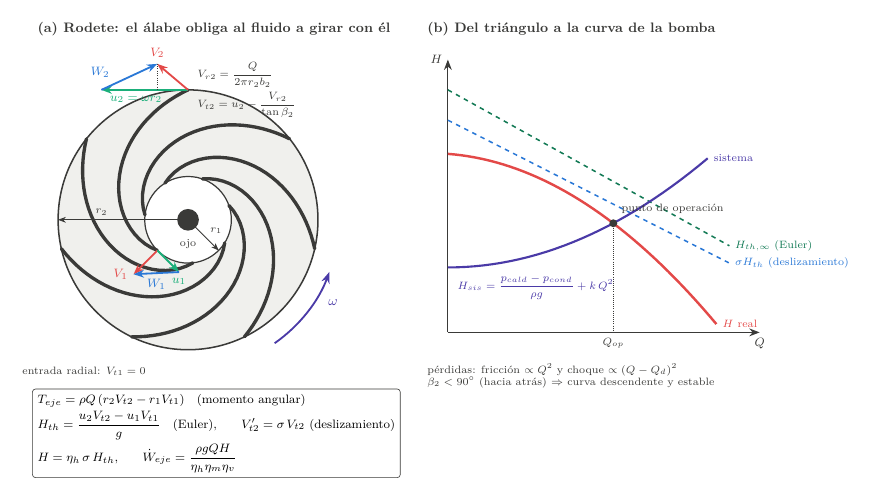

> 🎓 **Hallazgos en la entrega.**
> - **Turbina de vapor:** se usó la densidad de **gas ideal** con $c_p$ constante también dentro de la zona húmeda. Además, el radio medio crece de 0.42 a 2.65 m, así que a 4000 rpm la punta del álabe 30 iría a **~1180 m/s**. Los álabes de última etapa reales trabajan por debajo de ~700 m/s.
> - **Bomba:** con $\Pi$ = 4 desde 1 atm desarrolla ~50 m de columna, pero alimentar un domo a 12 MPa exige **~1250 m**. Hace falta una bomba **multietapa** (la cuenta se hace abajo).

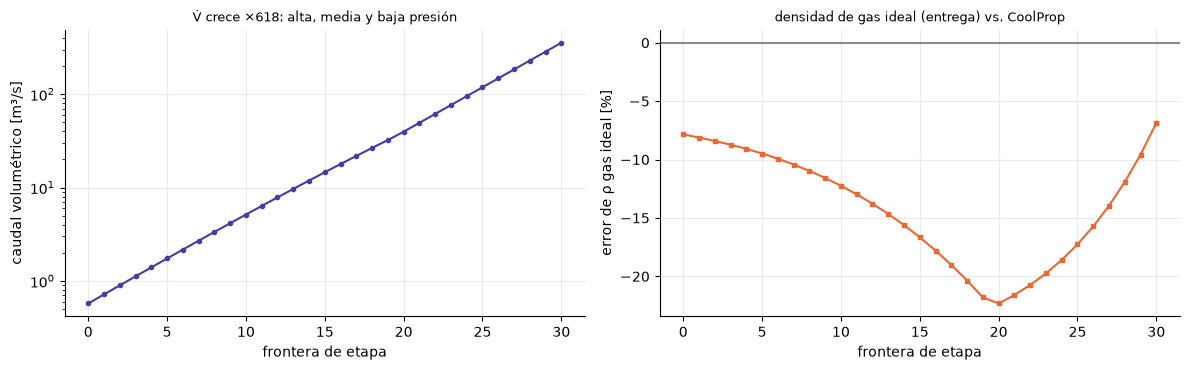

P_eje = 23.97 MW, x4 = 0.867 (humedad 13.3 %, erosión de la última etapa)
Entrega: U_punta etapa 30 = 1182 m/s; error máximo de ρ ideal = 22 %


In [17]:
# === Turbina de vapor: 30 etapas de igual Δh, gas real (CoolProp) vs. gas ideal de la entrega =================
def linea_tv(p3=12e6, T3=813.15, pc=7.0e3, eta=0.86, ms=20.0, N=30, rpm=3600.0):
    h3 = CP.PropsSI("H", "P", p3, "T", T3, "Water"); s3 = CP.PropsSI("S", "P", p3, "T", T3, "Water")
    h4 = h3 - eta*(h3 - CP.PropsSI("H", "P", pc, "S", s3, "Water"))
    # línea de expansión: recta en h-s (aprox. de Baumann), presiones geométricas
    ps = p3*(pc/p3)**(np.arange(N + 1)/N); hs = np.linspace(h3, h4, N + 1)
    rho = np.array([CP.PropsSI("D", "P", p, "H", h, "Water") for p, h in zip(ps, hs)])
    T = np.array([CP.PropsSI("T", "P", p, "H", h, "Water") for p, h in zip(ps, hs)])
    x = np.array([CP.PropsSI("Q", "P", p, "H", h, "Water") for p, h in zip(ps, hs)])
    # gas ideal con cp constante (método de la entrega): T baja con dh/cp, rho = p/(R T)
    T_id = T3 - (h3 - hs)/2300.0; rho_id = ps/(461.5*np.maximum(T_id, 200.0))
    U_lim = 650.0; w = 2*np.pi*rpm/60; Vdot = ms/rho
    # área necesaria con c_a = 0.5 U_m y radio medio limitado por U_tip <= U_lim (aprox. r_tip ~ r_m + h/2)
    return dict(p=ps, h=hs, rho=rho, T=T, x=x, rho_id=rho_id, Vdot=Vdot, P=ms*(h3 - h4), h4=h4, x4=x[-1])
TV = linea_tv(ms=hrsg_diseno()["ms"])
err_id = 100*(TV["rho_id"] - TV["rho"])/TV["rho"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].semilogy(np.arange(31), TV["Vdot"], "o-", color=COL["vapor"], ms=3); ax[0].set_xlabel("frontera de etapa"); ax[0].set_ylabel("caudal volumétrico [m³/s]")
ax[0].set_title(f"V̇ crece ×{TV['Vdot'][-1]/TV['Vdot'][0]:.0f}: alta, media y baja presión", fontsize=9.5)
ax[1].plot(np.arange(31), err_id, "s-", color=COL["entrega"], ms=3); ax[1].axhline(0, color=COL["gris"])
ax[1].set_xlabel("frontera de etapa"); ax[1].set_ylabel("error de ρ gas ideal [%]"); ax[1].set_title("densidad de gas ideal (entrega) vs. CoolProp", fontsize=9.5)
i_sat = np.argmax(TV["x"] < 1.0) if np.any(TV["x"] < 1.0) else None
if i_sat: ax[1].axvspan(i_sat, 30, color=COL["agua"], alpha=0.12); ax[1].text(i_sat + 0.3, err_id.min()*0.8, "zona húmeda", fontsize=8)
plt.tight_layout(); plt.show()
w_tv = 2*np.pi*4000/60
print(f"P_eje = {TV['P']/1e6:.2f} MW, x4 = {TV['x4']:.3f} (humedad {100*(1 - TV['x4']):.1f} %, erosión de la última etapa)")
print(f"Entrega: U_punta etapa 30 = {2.822382*w_tv:.0f} m/s; error máximo de ρ ideal = {np.abs(err_id).max():.0f} %")

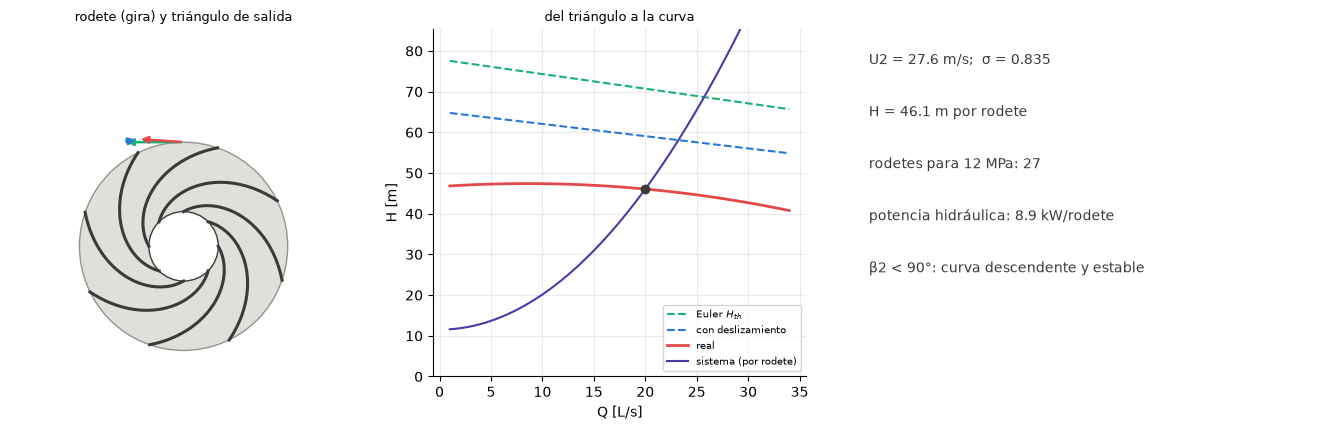

In [18]:
# === Bomba: Euler + deslizamiento de Wiesner + pérdidas; parámetros de la entrega ===============================
BOMBA = dict(r1=0.040, r2=0.120, b1=0.025, b2=0.018, beta1=20.0, beta2=30.0, z=8, eta_h=0.78, eta_m=0.95, eta_v=0.98, N=2200.0, Qd=0.020)
def curva_bomba(N, beta2, z, Q, b2=BOMBA["b2"], r2=BOMBA["r2"], eta_h=BOMBA["eta_h"], Qd=None):
    U2 = 2*np.pi*N/60*r2; cr2 = Q/(2*np.pi*r2*b2); ct2 = U2 - cr2/np.tan(np.radians(beta2))
    sigma = 1 - np.sqrt(np.sin(np.radians(beta2)))/z**0.7
    Hth = U2*ct2/G; Qd = BOMBA["Qd"]*N/BOMBA["N"] if Qd is None else Qd
    H = eta_h*sigma*Hth - 0.35*U2**2/(2*G)*((Q - Qd)/Qd)**2*0.3            # pérdida por choque fuera de diseño (SUPUESTO k = 0.105)
    return dict(U2=U2, cr2=cr2, ct2=ct2, sigma=sigma, Hth=Hth, H=H)
b0 = curva_bomba(BOMBA["N"], BOMBA["beta2"], BOMBA["z"], BOMBA["Qd"])
H_req = (12e6 - 7e3)/(990*G)
print(f"Bomba de la entrega en diseño: U2 = {b0['U2']:.1f} m/s, σ(Wiesner) = {b0['sigma']:.3f} (entrega: 0.90), H_th = {b0['Hth']:.1f} m, H = {b0['H']:.1f} m")
print(f"Alimentar el domo exige H = {H_req:.0f} m -> {int(np.ceil(H_req/b0['H']))} rodetes como este en serie a 2200 rpm, "
      f"o {int(np.ceil(H_req/curva_bomba(5500, 30, 8, 0.02*5500/2200)['H']))} a 5500 rpm (bomba de alimentación real)")

def w6_bomba(N, beta2, z, Q_rel, k):
    Qd = BOMBA["Qd"]*N/BOMBA["N"]; Q = Q_rel*Qd
    b = curva_bomba(N, beta2, z, Q); Qs = np.linspace(0.05, 1.7, 60)*Qd
    cu = [curva_bomba(N, beta2, z, q) for q in Qs]
    fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.4), gridspec_kw={"width_ratios": [1, 1, 1.2]})
    ax = axs[0]; r1, r2 = BOMBA["r1"], BOMBA["r2"]; giro = np.radians(k*N/60*360*0.002) % (2*np.pi)
    ax.add_patch(Circle((0, 0), r2, fc=COL["metal"], ec=COL["tinta"], alpha=0.5)); ax.add_patch(Circle((0, 0), r1, fc="white", ec=COL["tinta"]))
    rr = np.linspace(r1, r2, 30)
    for j in range(int(z)):
        th0 = giro + 2*np.pi*j/z; th = th0 - np.log(rr/r1)/np.tan(np.radians(beta2))
        ax.plot(rr*np.cos(th), rr*np.sin(th), color=COL["tinta"], lw=2.2)
    P2 = np.array([0, r2]); sc = 0.0025
    for v, c, nm in [((-b["U2"], 0), COL["red"], "U2"), ((-b["ct2"]*b["sigma"], b["cr2"]), COL["gas"], "c2'"), ((-b["ct2"]*b["sigma"] + b["U2"], b["cr2"]), COL["agua"], "w2")]:
        o = P2 if nm != "w2" else P2 + np.array([-b["U2"], 0])*sc
        ax.annotate("", xy=o + np.array(v)*sc if nm != "w2" else P2 + np.array([-b["ct2"]*b["sigma"], b["cr2"]])*sc, xytext=o,
                    arrowprops=dict(arrowstyle="-|>", color=c, lw=1.8))
    ax.set_xlim(-0.2, 0.2); ax.set_ylim(-0.15, 0.25); ax.set_aspect("equal"); ax.axis("off"); ax.set_title("rodete (gira) y triángulo de salida", fontsize=9)
    axs[1].plot(Qs*1e3, [c["Hth"] for c in cu], "--", color=COL["red"], label="Euler $H_{th}$")
    axs[1].plot(Qs*1e3, [c["Hth"]*c["sigma"] for c in cu], "--", color=COL["agua"], label="con deslizamiento")
    axs[1].plot(Qs*1e3, [c["H"] for c in cu], color=COL["gas"], lw=2, label="real")
    Hsis = lambda q: 0.25*b0["H"] + 0.75*b0["H"]*(q/BOMBA["Qd"])**2
    axs[1].plot(Qs*1e3, Hsis(Qs), color=COL["vapor"], lw=1.5, label="sistema (por rodete)")
    axs[1].plot(Q*1e3, b["H"], "o", color=COL["tinta"]); axs[1].set_xlabel("Q [L/s]"); axs[1].set_ylabel("H [m]"); axs[1].legend(fontsize=7.5)
    axs[1].set_ylim(0, max(c["Hth"] for c in cu)*1.1); axs[1].set_title("del triángulo a la curva", fontsize=9)
    axs[2].axis("off"); n = int(np.ceil(H_req/max(b["H"], 1)))
    for i, s in enumerate([f"U2 = {b['U2']:.1f} m/s;  σ = {b['sigma']:.3f}", f"H = {b['H']:.1f} m por rodete", f"rodetes para 12 MPa: {n}",
                           f"potencia hidráulica: {990*G*Q*b['H']/1e3:.1f} kW/rodete",
                           "β2 < 90°: curva descendente y estable" if beta2 < 90 else "β2 ≥ 90°: curva plana o creciente (inestable)"]):
        axs[2].text(0, 0.9 - 0.15*i, s, fontsize=10, transform=axs[2].transAxes, color=COL["aviso"] if (i == 4 and beta2 >= 90) else COL["tinta"])
    plt.tight_layout(); plt.show()
_w6 = dict(N=FloatSlider(value=2200, min=1000, max=6000, step=100, description="N [rpm]", continuous_update=False),
           beta2=FloatSlider(value=30, min=15, max=120, step=5, description="β2 [°]", continuous_update=False),
           z=IntSlider(value=8, min=3, max=14, description="álabes z", continuous_update=False),
           Q_rel=FloatSlider(value=1.0, min=0.2, max=1.6, step=0.05, description="Q/Q_d", continuous_update=False),
           k=IntSlider(value=0, min=0, max=200, description="t"))
_p6 = Play(value=0, min=0, max=200, step=2, interval=100); jslink((_p6, "value"), (_w6["k"], "value"))
display(VBox([HBox([_w6["N"], _w6["beta2"]]), HBox([_w6["z"], _w6["Q_rel"]]), HBox([_p6, _w6["k"]]), interactive_output(w6_bomba, _w6)]))

**Widget 6. Bomba: del triángulo a la curva.**
1. Sube $\beta_2$ por encima de 90° (álabes curvados hacia adelante): la curva $H$-$Q$ se vuelve creciente, y dos bombas en paralelo podrían "pelearse" el caudal.
2. Pocos álabes ($z$ = 3) dan más deslizamiento y menos altura con la misma geometría.
3. Duplica $N$: la altura crece con $N^2$ y los rodetes necesarios bajan a la cuarta parte. Por eso las bombas de alimentación giran a 5000-6000 rpm.

## 9. Condensador transitorio

El condensador de la entrega (3000 tubos, $L$ = 10 m, $D_o$ = 25 mm, coraza de 1.8 m, 650 kg/s de agua a 25 °C) se describe con una red de capacitancias concentradas.
- **Lado de los tubos:** $h_i$ por Dittus-Boelter.
- **Lado de la coraza:** condensación de Nusselt en banco horizontal, $h_o=0.725\,[\rho_l(\rho_l-\rho_v)gh_{fg}k_l^3/(\mu_lD_o\Delta T)]^{1/4}N_f^{-1/6}$.

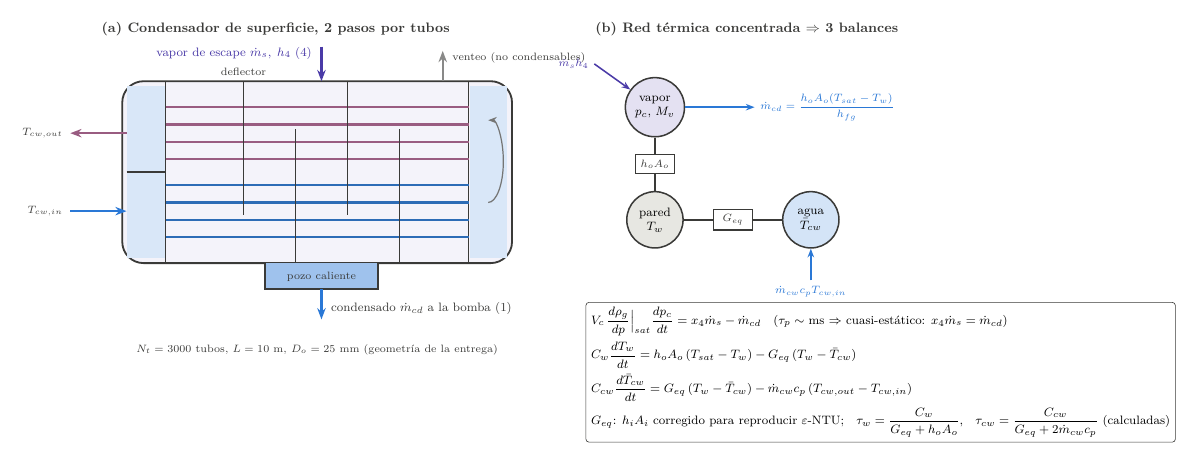

**Corrección de la red concentrada.** Si el agua se representa con su temperatura media aritmética $\bar T_{cw}$, la ley $h_iA_i(T_w-\bar T_{cw})$ sobreestima la diferencia útil cuando $NTU=UA/\dot m c_p\approx 2.4$: el estacionario se desvía ~20 % del método ε-NTU. Se usa en su lugar una conductancia equivalente $G_{eq}$, definida por $1/G_{eq}=1/(\varepsilon\dot mc_p)-1/(2\dot mc_p)-1/(h_oA_o)$ con $\varepsilon=1-e^{-UA/\dot mc_p}$, para que el estacionario de la red coincida con ε-NTU.

**Las constantes de tiempo se calculan, no se imponen.** La masa de vapor responde en **milisegundos**, $\tau_p=V_c(d\rho_g/dp)/[h_oA_o(dT_{sat}/dp)/h_{fg}]$. Integrarla obligaría a pasos de 1 ms durante horas, así que se resuelve como balance **cuasi-estacionario** ($x_4\dot m_s=\dot m_{cd}$). La pared y el agua de enfriamiento sí se integran en el tiempo.

In [19]:
# === Condensador (geometría de la entrega) =====================================================================
COND = dict(Nt=3000, L=10.0, Do=0.025, Di=0.021, pasos=2, D_coraza=1.8, rho_m=7850.0, c_m=500.0)
COND["Ao"] = COND["Nt"]*np.pi*COND["Do"]*COND["L"]; COND["Ai"] = COND["Nt"]*np.pi*COND["Di"]*COND["L"]
COND["Cw"] = COND["Nt"]*np.pi/4*(COND["Do"]**2 - COND["Di"]**2)*COND["L"]*COND["rho_m"]*COND["c_m"]
COND["Ccw"] = COND["Nt"]*np.pi/4*COND["Di"]**2*COND["L"]*997.0*4180.0
COND["Vc"] = np.pi/4*COND["D_coraza"]**2*COND["L"] - COND["Nt"]*np.pi/4*COND["Do"]**2*COND["L"]
def h_i_cw(mcw, R_f=0.0):
    rho, mu, k, Pr = 996.0, 8.0e-4, 0.615, 5.4                       # agua a ~30 °C
    v = mcw/(rho*COND["Nt"]/COND["pasos"]*math.pi/4*COND["Di"]**2); Re = rho*v*COND["Di"]/mu
    h = 0.023*Re**0.8*Pr**0.4*k/COND["Di"]
    return 1/(1/h + R_f), v, Re                                        # R_f: resistencia de ensuciamiento [m² K/W]
def G_cw(mcw, h_o, R_f=0.0):
    # conductancia equivalente pared-agua de la red concentrada: hace que su estado estacionario coincida con el
    # método ε-NTU (con T̄_cw = media aritmética, el h_iA_i desnudo sobreestima el ΔT útil cuando NTU ~ 2-4)
    C = mcw*4180.0; UA = 1/(1/(h_o*COND["Ao"]) + 1/(h_i_cw(mcw, R_f)[0]*COND["Ai"])); eps = 1 - math.exp(-UA/C)
    return 1/(1/(eps*C) - 1/(2*C) - 1/(h_o*COND["Ao"]))
def h_o_nusselt(Tsat, Tw):
    dT = max(Tsat - Tw, 0.5); Tf = Tsat - 0.5*dT                       # dT acotado: evita x**0.25 de un negativo
    rl, mu, kl = (CP.PropsSI(k, "T", Tf, "Q", 0, "Water") for k in ("D", "V", "L"))
    rv = CP.PropsSI("D", "T", Tsat, "Q", 1, "Water"); hfg = CP.PropsSI("H", "T", Tsat, "Q", 1, "Water") - CP.PropsSI("H", "T", Tsat, "Q", 0, "Water")
    return 0.725*(rl*(rl - rv)*G*hfg*kl**3/(mu*COND["Do"]*dT))**0.25*np.sqrt(COND["Nt"])**(-1/6)
def condensador_pc(ms_v, Tw, h_o):
    # balance cuasi-estacionario del vapor: ms_v*hfg = h_o*Ao*(Tsat - Tw)
    pc = 9e3
    for _ in range(3):
        c = csat(pc); Tsat = Tw + ms_v*(c["hg"] - c["hf"])/(h_o*COND["Ao"]); pc = pc_de_Tsat(Tsat)
    return pc, Tsat
# constantes de tiempo en el punto de diseño (vapor de §6, expansión de §8)
_ms, _x4 = hrsg_diseno()["ms"], TV["x4"]; c7 = csat(7e3); hfg7 = c7["hg"] - c7["hf"]
hi0 = h_i_cw(650.0)[0]; ho0 = h_o_nusselt(312.0, 309.7)
dTs_dp = (csat(7.5e3)["Ts"] - csat(6.5e3)["Ts"])/1e3; drg_dp = (csat(7.5e3)["rg"] - csat(6.5e3)["rg"])/1e3
G0 = G_cw(650.0, ho0)
TAU_COND = dict(p=COND["Vc"]*drg_dp/(ho0*COND["Ao"]*dTs_dp/hfg7), w=COND["Cw"]/(G0 + ho0*COND["Ao"]), cw=COND["Ccw"]/(G0 + 2*650.0*4180.0))
print(f"h_i = {hi0:.0f} W/m²K (v = {h_i_cw(650)[1]:.2f} m/s), h_o = {ho0:.0f} W/m²K, A_o = {COND['Ao']:.0f} m²; "
      f"G_eq = {G0/1e6:.2f} MW/K frente a h_iA_i = {hi0*COND['Ai']/1e6:.2f} MW/K")
print("Constantes de tiempo calculadas: " + ", ".join(f"τ_{k} = {v:.3g} s" for k, v in TAU_COND.items()) + "  (la entrega imponía τ = 80 s)")

h_i = 5426 W/m²K (v = 1.26 m/s), h_o = 7264 W/m²K, A_o = 2356 m²; G_eq = 6.20 MW/K frente a h_iA_i = 10.74 MW/K
Constantes de tiempo calculadas: τ_p = 0.0037 s, τ_w = 0.73 s, τ_cw = 3.72 s  (la entrega imponía τ = 80 s)


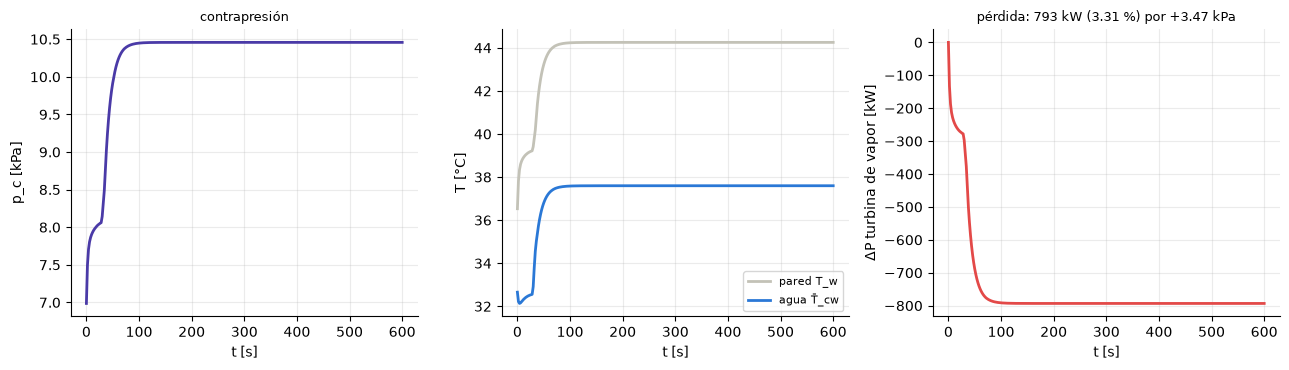

In [20]:
def sim_condensador(pert, mag, t_fin=600.0):
    ms_v = _ms*_x4; Tin0, mcw0 = 298.15, 650.0
    Tin = (lambda t: Tin0 + mag*(t > 30)) if pert == "T agua de mar/torre" else (lambda t: Tin0)
    mcw = (lambda t: mcw0*(1 - mag/100*(t > 30))) if pert == "caudal de agua (−%)" else (lambda t: mcw0)
    Rf = (lambda t: mag*1e-5*(t > 30)) if pert == "ensuciamiento" else (lambda t: 0.0)
    def f(t, y):
        Tw, Tc = y; G = G_cw(mcw(t), ho0, Rf(t)); pc, Ts = condensador_pc(ms_v, Tw, ho0)
        Qc = ho0*COND["Ao"]*(Ts - Tw); Qi = G*(Tw - Tc)
        return [(Qc - Qi)/COND["Cw"], (Qi - 2*mcw(t)*4180.0*(Tc - Tin(t)))/COND["Ccw"]]
    # estado inicial estacionario: el agua recibe todo el calor de condensación
    Tc0 =Tin0 + ms_v*hfg7/(2*mcw0*4180); Tw0 = Tc0 + ms_v*hfg7/(h_i_cw(mcw0)[0]*COND["Ai"])
    tt = np.linspace(0, t_fin, 301)
    sol = solve_ivp(f, (0, t_fin), [Tw0, Tc0], t_eval=tt, method="LSODA", max_step=2.0)
    pc = np.array([condensador_pc(ms_v, Tw, ho0)[0] for Tw in sol.y[0]])
    h3 = h_v(12e6, 813.15); s3 = s_ph_v(12e6, h3)
    P = np.array([_ms*0.86*(h3 - h_ps_c(p, s3)) for p in pc])
    return tt, sol.y, pc, P
def w7_condensador(pert, mag):
    tt, Y, pc, P = sim_condensador(pert, mag)
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
    axs[0].plot(tt, pc/1e3, color=COL["vapor"], lw=2); axs[0].set_ylabel("p_c [kPa]"); axs[0].set_xlabel("t [s]"); axs[0].set_title("contrapresión", fontsize=9.5)
    axs[1].plot(tt, Y[0] - 273.15, color=COL["metal"], lw=2, label="pared T_w"); axs[1].plot(tt, Y[1] - 273.15, color=COL["agua"], lw=2, label="agua T̄_cw")
    axs[1].legend(fontsize=8); axs[1].set_ylabel("T [°C]"); axs[1].set_xlabel("t [s]")
    axs[2].plot(tt, (P - P[0])/1e6*1e3, color=COL["gas"], lw=2); axs[2].set_ylabel("ΔP turbina de vapor [kW]"); axs[2].set_xlabel("t [s]")
    axs[2].set_title(f"pérdida: {(P[0] - P[-1])/1e3:.0f} kW ({100*(P[0] - P[-1])/P[0]:.2f} %) por {(pc[-1] - pc[0])/1e3:+.2f} kPa", fontsize=9.5)
    plt.tight_layout(); plt.show()
_w7 = dict(pert=ToggleButtons(options=["T agua de mar/torre", "caudal de agua (−%)", "ensuciamiento"], value="T agua de mar/torre", description="escalón en"),
           mag=FloatSlider(value=5, min=0, max=30, step=1, description="magnitud", continuous_update=False))
display(VBox([_w7["pert"], _w7["mag"], interactive_output(w7_condensador, _w7)]))

**Widget 7. Condensador.** La magnitud significa K (temperatura), % (caudal) o $10^{-5}$ m²K/W (ensuciamiento).
1. +5 K en el agua de enfriamiento (la tarde en la costa Caribe) suben la contrapresión y la turbina de vapor pierde potencia en ~1 minuto. Es el retardo térmico de la pared y del agua en los tubos, **no** un τ impuesto.
2. El ensuciamiento ($R_f$ ~ 10-20·10⁻⁵ m²K/W tras meses sin limpieza) tiene el mismo efecto, pero permanente. Es la razón de la limpieza con bolas de esponja (Taprogge) en línea.

## 10. La planta ensamblada

Los bloques anteriores se acoplan como muestra el diagrama:
- **Cuasi-estáticos:** turbina de gas (mapa de carga parcial del modelo por etapas), turbina de vapor (Stodola + CoolProp), bomba y presión del condensador.
- **EDO en el tiempo:**
  - metal del sobrecalentador y del economizador (10 celdas en contraflujo cada uno);
  - domo de Åström-Bell escalado;
  - pared y agua del condensador;
  - frecuencia de la red y controladores.

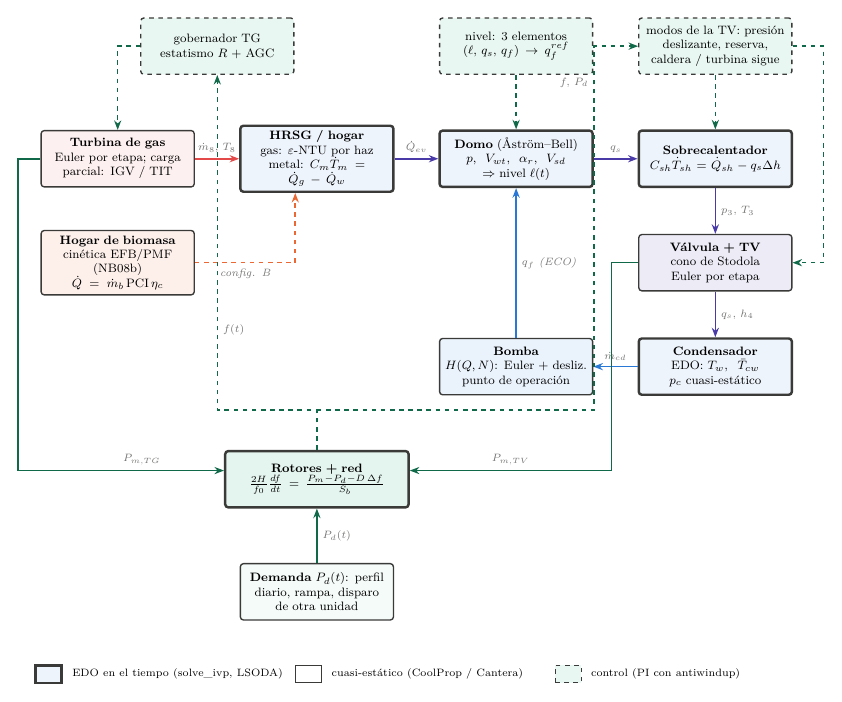

**Carga parcial de la turbina de gas.**
1. Primero se cierran los álabes guía (IGV), que reducen $\dot m$ hasta 75 % manteniendo $T_8$ = 596 °C. Así la HRSG sigue recibiendo gas caliente.
2. Después baja la TIT.

La presión del vapor **desliza**: la válvula de la turbina de vapor queda abierta y $p\propto\dot m_s$ (Stodola). Así se evitan las pérdidas por estrangulamiento.

**Escalado del domo.** Volúmenes y masas de la P16-G16 se escalan con el caudal de vapor, $V_i^{HRSG}=V_i^{P16}\,\dot m_s/\dot m_s^{P16}$ (64 kg/s, el punto de carga media donde se validó en §7). **SUPUESTO** de semejanza geométrica.

**Metal de la HRSG.** La masa de tubo aletado se fija proporcional a la UA del lado gas ($\mu$ = 0.3 kg·K/W, SUPUESTO). Con ella, $\tau_{metal}=\mu c_m/(1+UA_g/UA_s)$ resulta igual en todas las secciones.

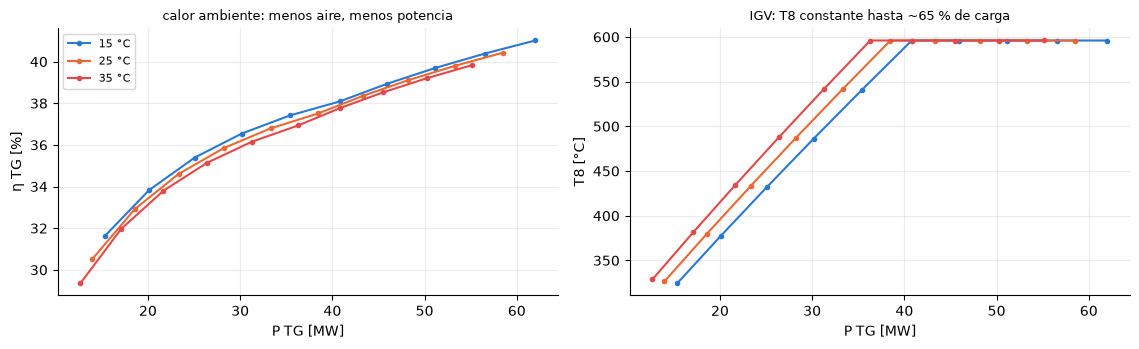

In [21]:
# === Mapa de carga parcial de la SGT-800 (T ambiente 15/25/35 °C) — pesado: se guarda en la caché =================
T8_MAX = TG["T8"]
def punto_tg(m_rel, TIT, T1):
    return ciclo_tg(m_exh=135.5*m_rel, PI=21.1*m_rel*np.sqrt(TIT/TIT0), TIT=TIT, eta_pt=ETA_PT, T1=T1)   # tobera ahogada: p3 ∝ ṁ√TIT
def mapa_tg(T1):
    filas = []; mmax = np.sqrt(T_ISO/T1)                       # caudal corregido constante: ṁ ∝ 1/√T1
    for mr in np.linspace(mmax, 0.75*mmax, 5):                 # rama IGV: T8 ≤ T8 nominal
        r = punto_tg(mr, TIT0, T1); TIT = TIT0
        if r["T8"] > T8_MAX:
            TIT = brentq(lambda x: punto_tg(mr, x, T1)["T8"] - T8_MAX, 1100, TIT0, xtol=0.5); r = punto_tg(mr, TIT, T1)
        filas.append((r["P"], 135.5*mr, r["T8"], r["Qf"], r["m_f"], TIT))
    for TIT in np.linspace(filas[-1][5], 1050, 6)[1:]:          # rama de TIT con IGV al mínimo
        r = punto_tg(0.75*mmax, TIT, T1); filas.append((r["P"], 135.5*0.75*mmax, r["T8"], r["Qf"], r["m_f"], TIT))
    filas.sort()
    return {k: [float(f[i]) for f in filas] for i, k in enumerate(["P", "m_exh", "T8", "Qf", "m_f", "TIT"])}
if "gt_map" in CACHE and not RECALCULAR: GT_MAP = CACHE["gt_map"]
else:
    t0 = time.time(); GT_MAP = {str(T): mapa_tg(T + 273.15) for T in (15, 25, 35)}; CACHE["gt_map"] = GT_MAP
    print(f"mapa calculado en {time.time() - t0:.0f} s")
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
for T, c in zip(("15", "25", "35"), (COL["agua"], COL["tibio"], COL["gas"])):
    m = GT_MAP[T]; P = np.array(m["P"])/1e6
    ax[0].plot(P, 100*np.array(m["P"])/np.array(m["Qf"]), "o-", color=c, ms=3, label=f"{T} °C")
    ax[1].plot(P, np.array(m["T8"]) - 273.15, "o-", color=c, ms=3)
ax[0].set_xlabel("P TG [MW]"); ax[0].set_ylabel("η TG [%]"); ax[0].legend(fontsize=8); ax[0].set_title("calor ambiente: menos aire, menos potencia", fontsize=9.5)
ax[1].set_xlabel("P TG [MW]"); ax[1].set_ylabel("T8 [°C]"); ax[1].set_title("IGV: T8 constante hasta ~65 % de carga", fontsize=9.5)
plt.tight_layout(); plt.show()

In [22]:
# === Celdas de intercambio en contraflujo con nodo metálico (SH, ECO) ======================================
def seccion_celdas(Tg_in, mg, gtab, Ts_in, q, p, Tm, UAg, UAs, liquido=False):
    # gas: celda 0 -> N-1 ; agua/vapor: celda N-1 -> 0. Cada lado intercambia con el metal: T_sal = T_m + (T_ent - T_m) e^{-NTU}
    N = len(Tm); Qg = [0.0]*N; Tg = Tg_in; Tm = [float(v) for v in Tm]
    for j in range(N):
        ntu = UAg/(mg*gtab.cpT(Tg)); Tgo = Tm[j] + (Tg - Tm[j])*math.exp(-ntu)
        Qg[j] = mg*(gtab.hT(Tg) - gtab.hT(Tgo)); Tg = Tgo
    hf_, cpf = (h_l, cp_l) if liquido else (h_v, cp_v)
    Qs = [0.0]*N; Ts = Ts_in; hs_ = hf_(p, Ts)
    for j in range(N - 1, -1, -1):
        ntu = UAs/(max(q, 1e-3)*cpf(p, Ts)); Tso = Tm[j] + (Ts - Tm[j])*math.exp(-ntu)
        if liquido: Tso = min(Tso, tsat_p(p) - 0.5)           # el economizador no hierve
        h_o = hf_(p, Tso); Qs[j] = q*(h_o - hs_); Ts, hs_ = Tso, h_o
    return np.array(Qg), np.array(Qs), Tg, Ts, hs_

def _clip(x, a, b): return a if x < a else (b if x > b else x)
NSEC = 10
IDX = {k: i for i, k in enumerate(["df", "u", "Mc", "xpl", "xagc", "Pr", "y", "xy"])}
IDX["sh"] = slice(8, 8 + NSEC); IDX["eco"] = slice(8 + NSEC, 8 + 2*NSEC)
for i, k in enumerate(["Vwt", "p", "ar", "Vsd", "xl", "qf", "Tw", "Tcw"]): IDX[k] = 8 + 2*NSEC + i
NX = 8 + 2*NSEC + 8; IDOMO = slice(IDX["Vwt"], IDX["Vwt"] + 4)
AB_REF = dict(AB, qs=64.0, qdc=1200.0, Vwt=57.0, Vsd=5.0)     # P16-G16, carga media (validada en §7)

In [23]:
class Planta:
    # Diseño estacionario + EDO de la planta y de la red. tipo: "CC" (SGT-800 + HRSG) o "BIO" (hogar de biomasa, config. B)
    def __init__(self, tipo="CC", combustible="EFB", T_amb=15):
        self.tipo, self.comb = tipo, combustible
        self.C = dict(f0=F0, R=0.05, D=1.0, H_TG=5.0, H_TV=4.0, H_r=4.0, R_r=0.05, tau_r=6.0, tau_GT=8.0, Ki_pl=1/40,
                      T_agc=60.0, tau_y=2.0, tau_fv=3.0, Ti_l=200.0, eta_s=0.86, eta_mg=0.985, eta_bomba=0.80, y0=0.92,
                      tau_feed=20.0, tau_char=90.0, chi_v=0.75)          # SUPUESTOS de control y de máquinas (ver texto)
        self.T_cw_in, self.m_cw = 298.15, 650.0
        if tipo == "CC":
            m = GT_MAP[str(int(T_amb))]; self.map = {k: np.array(v) for k, v in m.items()}
            self._map = Tabla1D(self.map["P"], {k: self.map[k] for k in ["m_exh", "T8", "Qf", "m_f"]})
            self.P_TG_max, self.P_TG_min = self.map["P"].max(), self.map["P"].min()
            self.gas = GAS_EXH; self.p_d, self.T3_d, self.pinch, self.approach = 12e6, 813.15, 10.0, 10.0
            self.mg_d, self.Tg_in_d = np.interp(self.P_TG_max, self.map["P"], self.map["m_exh"]), np.interp(self.P_TG_max, self.map["P"], self.map["T8"])
            self.S_TG, self.S_TV = 75.0, 35.0                                  # MVA (SUPUESTO)
            self.co2_kg = CO2_GN
        else:
            b = biomasa(combustible, 1.4); self.bio = b
            self.LHV_ar, self.mg_por_mf, self.co2_kg = b["LHV_ar"], 1 + b["AFR"], b["co2_kg"]
            self.gas = GasTab(b["X"], "X"); self.p_d, self.T3_d, self.approach = 3.0e6, 573.15, 10.0     # artículo: 30 t/h, 573 K, 10-30 bar
            self.S_TG, self.S_TV = 0.0, 10.0
        self._diseno()

    def _h4(self, p_in, h3, pc):
        return h3 - self.C["eta_s"]*(h3 - h_ps_c(pc, s_ph_v(p_in, h3)))

    def _diseno(self):
        C, p = self.C, self.p_d; s = sat(p); h3 = h_v(p, self.T3_d); Tcd = 317.0
        for _ in range(4):
            pc = pc_de_Tsat(Tcd); c = csat(pc)
            h_fw = c["hf"] + (p - pc)/c["rf"]/C["eta_bomba"]; T_fw = T_ph_l(p, h_fw)
            T_eco = s["Ts"] - self.approach; h_eco = h_l(p, T_eco)
            if self.tipo == "CC":
                Tg_ev_out = s["Ts"] + self.pinch
                ms = self.mg_d*(self.gas.hT(self.Tg_in_d) - self.gas.hT(Tg_ev_out))/(h3 - h_eco)
                self.Tstack_d = self.gas.Th(self.gas.hT(Tg_ev_out) - ms*(h_eco - h_fw)/self.mg_d)
            else:
                ms = 30e3/3600; Q_util = ms*(h3 - h_fw); Tst = 433.15             # SUPUESTO: chimenea a 160 °C
                hin = self.gas.hT(298.15) + self.LHV_ar/self.mg_por_mf
                self.eta_b = (hin - self.gas.hT(Tst))/(hin - self.gas.hT(298.15))
                self.mf_d = Q_util/(self.eta_b*self.LHV_ar); self.mg_d = self.mf_d*self.mg_por_mf
                self.Tg_in_d = self.gas.Th(hin); self.Tstack_d = Tst
                Tg_ev_out = self.gas.Th(self.gas.hT(self.Tg_in_d) - ms*(s["hs"] - h_eco)/self.mg_d)
            h4 = self._h4(p, h3, pc); P_ST = ms*(h3 - h4)*C["eta_mg"]; Q_cond = ms*(h4 - c["hf"])
            ho = h_o_nusselt(Tcd, Tcd - 2.5) if _ == 0 else ho
            Tbar = self.T_cw_in + Q_cond/(2*self.m_cw*4180.0); Tw = Tbar + Q_cond/G_cw(self.m_cw, ho)
            ho = h_o_nusselt(Tcd, Tw); Tcd = Tw + Q_cond/(ho*COND["Ao"])
        self.d = dict(ms=ms, h3=h3, pc=pc, h_fw=h_fw, T_fw=T_fw, h_eco=h_eco, T_eco=T_eco, Tg_ev_out=Tg_ev_out,
                      P_ST=P_ST, Q_cond=Q_cond, Tw=Tw, Tbar=Tbar, Tcd=Tcd, h4=h4)
        self.h_o = ho; self.G_cw = G_cw(self.m_cw, ho)
        # domo escalado por semejanza desde la P16-G16
        sc = ms/AB_REF["qs"]; self.sc = sc
        A = {k: AB_REF[k]*sc for k in ["Vd", "Vr", "Vdc", "Ad", "mt", "mr", "md"]}
        A.update(k=AB_REF["k"], beta=AB_REF["beta"], Td=AB_REF["Td"], Cp=AB_REF["Cp"])
        Qev = ms*(s["hs"] - h_eco)
        self.A, x0d, _ = domo_equilibrio(A, p, Qev, h_eco, AB_REF["qdc"]/AB_REF["qs"]*ms, AB_REF["Vsd"]*sc, AB_REF["Vwt"]*sc)
        self.x0_domo = x0d; self.l_ref = nivel_domo(x0d, self.A)
        self.K_t = ms/p                                                     # Stodola (bloque estrangulado)
        # UA de SH y ECO ajustadas al diseño; masa de metal proporcional a la UA
        self.UAs_ratio, self.c_m, self.mu_UA = 4.0, 500.0, 0.3
        if self.tipo == "CC":
            Tg_sh_in = self.Tg_in_d; Tg_sh_out = self.gas.Th(self.gas.hT(Tg_sh_in) - ms*(h3 - s["hs"])/self.mg_d)
            self.NTU_ev = np.log((Tg_sh_out - s["Ts"])/(Tg_ev_out - s["Ts"])); Tg_eco_in = Tg_ev_out
        else:
            self.NTU_ev = np.log((self.Tg_in_d - s["Ts"])/(Tg_ev_out - s["Ts"])); Tg_sh_in = Tg_ev_out
            Tg_eco_in = self.gas.Th(self.gas.hT(Tg_sh_in) - ms*(h3 - s["hs"])/self.mg_d)
        def estacionario(UAg, Tg_in, Ts_in, liquido):
            UAs = self.UAs_ratio*UAg
            f = lambda Tm: (lambda r: (r[0] - r[1])/1e5)(seccion_celdas(Tg_in, self.mg_d, self.gas, Ts_in, ms, p, Tm, UAg/NSEC, UAs/NSEC, liquido))
            Tm = fsolve(f, np.linspace(Tg_in - 30, Ts_in + 10, NSEC), xtol=1e-10)
            return Tm, seccion_celdas(Tg_in, self.mg_d, self.gas, Ts_in, ms, p, Tm, UAg/NSEC, UAs/NSEC, liquido)
        UA_sh = brentq(lambda UA: estacionario(UA, Tg_sh_in, s["Ts"], False)[1][3] - self.T3_d, 1e3, 5e6)
        UA_eco = brentq(lambda UA: estacionario(UA, Tg_eco_in, T_fw, True)[1][3] - T_eco, 1e3, 5e7)
        self.UA = dict(sh=UA_sh, eco=UA_eco)
        self.Tm_d = dict(sh=estacionario(UA_sh, Tg_sh_in, s["Ts"], False)[0], eco=estacionario(UA_eco, Tg_eco_in, T_fw, True)[0])
        self.M_sh, self.M_eco = self.mu_UA*UA_sh, self.mu_UA*UA_eco
        self.tau_metal = self.mu_UA*self.c_m/(1 + 1/self.UAs_ratio)
        C["Kp_l"] = 0.2*ms/0.1                                              # 20 % del caudal por 0.1 m de error de nivel
        self.P_nom = (self.P_TG_max + P_ST) if self.tipo == "CC" else P_ST
        self.x0 = self.estado_diseno()

    def estado_diseno(self):
        x = np.zeros(NX); x[IDX["sh"]] = self.Tm_d["sh"]; x[IDX["eco"]] = self.Tm_d["eco"]
        x[IDOMO] = self.x0_domo; x[IDX["qf"]] = self.d["ms"]; x[IDX["y"]] = 1.0
        x[IDX["Tw"]], x[IDX["Tcw"]] = self.d["Tw"], self.d["Tbar"]
        if self.tipo == "CC": x[IDX["u"]] = self.P_TG_max; x[IDX["xpl"]] = self.P_TG_max/1e6
        else:
            x[IDX["u"]] = self.mf_d; x[IDX["Mc"]] = (1 - self.C["chi_v"])*self.mf_d*self.C["tau_char"]
            x[IDX["xpl"]] = self.mf_d; x[IDX["xy"]] = 1.0
        return x

    def configurar(self, esc):
        # esc: P_sched(t) [MW pedidos a la planta], P_load(t) [MW del sistema], S_r [MVA del resto del sistema; 0 = isla]
        C = self.C; self.esc = esc; self.S_r = esc.get("S_r", 0.0); S_p = self.S_TG + self.S_TV
        self.M_sys = 2*(C["H_TG"]*self.S_TG + C["H_TV"]*self.S_TV + C["H_r"]*self.S_r)/C["f0"]          # MW·s/Hz
        self.alpha_p = S_p/(S_p + self.S_r)
        self.beta_bias = (self.P_nom/1e6/C["R"] + self.S_r*0.85/C["R_r"])/C["f0"]                        # MW/Hz
        self.modo, self.nivel_modo = esc.get("modo", "pasiva"), esc.get("nivel", "3e")
        self.T_cw = esc.get("T_cw_in", lambda t: self.T_cw_in); self.P_r0 = esc.get("P_r0", 0.0)

    def algebra(self, t, x):
        C, A, d = self.C, self.A, self.d
        p = x[IDX["p"]]; s = sat(p); o = {}
        o["nivel"] = nivel_domo(x[IDOMO], A) - self.l_ref
        if self.tipo == "CC":
            P_GT = x[IDX["u"]]; g = self._map.todo(P_GT); mg, Tg = g["m_exh"], g["T8"]
            o.update(P_GT=P_GT, mf=g["m_f"], Qf=g["Qf"])
        else:
            mf = x[IDX["u"]]; Qrel = C["chi_v"]*mf*self.LHV_ar + x[IDX["Mc"]]/C["tau_char"]*self.LHV_ar
            mg = mf*self.mg_por_mf; Tg = self.gas.Th(self.gas.hT(298.15) + Qrel/max(mg, 1e-3))
            o.update(P_GT=0.0, mf=mf, Qf=mf*self.LHV_ar, Qrel=Qrel)
        o["mg"], o["Tg_in"] = mg, Tg; rmg = mg/self.mg_d
        UAg_sh, UAg_eco = self.UA["sh"]*rmg**0.6, self.UA["eco"]*rmg**0.6
        y = x[IDX["y"]]; Tsh = x[IDX["sh"]]; qs = self.K_t*y*p
        Tg_sh_in = Tg if self.tipo == "CC" else s["Ts"] + (Tg - s["Ts"])*math.exp(-self.NTU_ev*rmg**-0.4)
        for _ in range(2):                                    # q_s depende de T3 (Stodola) y T3 de q_s
            UAs_sh = self.UAs_ratio*self.UA["sh"]*max(qs/d["ms"], 0.05)**0.8
            Qg_sh, Qs_sh, Tg_sh_out, T3, h3 = seccion_celdas(Tg_sh_in, mg, self.gas, s["Ts"], qs, p, Tsh, UAg_sh/NSEC, UAs_sh/NSEC)
            qs = self.K_t*y*p*math.sqrt(self.T3_d/T3)
        p_sv = 1.10*self.p_d          # válvulas de seguridad (SUPUESTO: tarado +10 %, plena apertura a +3 %, capacidad 2 x caudal de diseño)
        o["q_sv"] = 2.0*d["ms"]*min(max((p - p_sv)/(0.03*p_sv), 0.0), 1.0)
        o.update(qs=qs, T3=T3, h3=h3, Qg_sh=Qg_sh, Qs_sh=Qs_sh)
        if self.tipo == "CC":
            Tg_ev_out = s["Ts"] + (Tg_sh_out - s["Ts"])*math.exp(-self.NTU_ev*rmg**-0.4)
            o["Qev"] = mg*(self.gas.hT(Tg_sh_out) - self.gas.hT(Tg_ev_out)); Tg_eco_in = Tg_ev_out
        else:
            o["Qev"] = mg*(self.gas.hT(Tg) - self.gas.hT(Tg_sh_in)); Tg_eco_in = Tg_sh_out
        qf = x[IDX["qf"]]; UAs_eco = self.UAs_ratio*self.UA["eco"]*max(qf/d["ms"], 0.05)**0.8
        Qg_eco, Qs_eco, Tstack, T_eco, h_eco = seccion_celdas(Tg_eco_in, mg, self.gas, d["T_fw"], qf, p, x[IDX["eco"]], UAg_eco/NSEC, UAs_eco/NSEC, True)
        o.update(Qg_eco=Qg_eco, Qs_eco=Qs_eco, Tstack=Tstack, h_fd=h_eco, T_eco=T_eco)
        Tw = x[IDX["Tw"]]; p_in = max(y, 0.05)*p; pc = d["pc"]
        for _ in range(2):
            h4 = self._h4(p_in, h3, pc); c = csat(pc); x4 = min(max((h4 - c["hf"])/(c["hg"] - c["hf"]), 0.0), 1.0)
            pc, Tsat_c = condensador_pc(qs*x4, Tw, self.h_o)
        c = csat(pc); P_ST = qs*(h3 - h4)*C["eta_mg"]; P_b = qf*(p - pc)/c["rf"]/C["eta_bomba"]
        o.update(pc=pc, h4=h4, x4=x4, P_ST=P_ST, P_bomba=P_b, Q_cond=qs*(h4 - c["hf"]))
        o["P_neto"] = o["P_GT"] + P_ST - P_b
        o["eta"] = o["P_neto"]/max(o["Qf"], 1.0); o["co2"] = o["mf"]*self.co2_kg/max(o["P_neto"], 1e3)*3.6e9
        o["f"] = C["f0"] + x[IDX["df"]]; o["Q_stack"] = mg*(self.gas.hT(Tstack) - self.gas.hT(298.15))
        return o

    def rhs(self, t, x):
        C, A, d, e = self.C, self.A, self.d, self.esc
        o = self.algebra(t, x); dx = np.zeros(NX); df = x[IDX["df"]]; fr = df/C["f0"]
        # red: ecuación de oscilación del sistema agregado (MW)
        P_load = e["P_load"](t); P_pl = (o["P_GT"] + o["P_ST"])/1e6
        dx[IDX["df"]] = (P_pl + x[IDX["Pr"]] - P_load*(1 + C["D"]*fr))/self.M_sys
        dx[IDX["xagc"]] = -self.beta_bias*df/C["T_agc"]                                   # AGC (control secundario)
        if self.S_r > 0:                                                                   # resto del sistema: gobernador equivalente
            Pr_ref = self.P_r0 + (1 - self.alpha_p)*x[IDX["xagc"]] - self.S_r*0.85/C["R_r"]*fr
            dx[IDX["Pr"]] = (Pr_ref - x[IDX["Pr"]])/C["tau_r"]
        P_dem = e["P_sched"](t) + self.alpha_p*x[IDX["xagc"]]
        if self.tipo == "CC":
            dx[IDX["xpl"]] = C["Ki_pl"]*(P_dem - P_pl)                                     # control de carga de la planta (integral)
            Pmax, Pmin = self.P_TG_max/1e6, self.P_TG_min/1e6; xpl = x[IDX["xpl"]]
            if (xpl > Pmax*1.02 and dx[IDX["xpl"]] > 0) or (xpl < Pmin*0.98 and dx[IDX["xpl"]] < 0): dx[IDX["xpl"]] = 0.0
            P_ref = _clip(xpl - Pmax/C["R"]*fr, Pmin, Pmax)                               # + estatismo de la TG
            dx[IDX["u"]] = (P_ref*1e6 - x[IDX["u"]])/C["tau_GT"]
            y_ref = 1.0 if self.modo == "pasiva" else _clip(C["y0"] - 0.5*fr/C["R"], 0.3, 1.0)
        else:
            ep = (self.p_d - x[IDX["p"]])/self.p_d; ePw = (P_dem - P_pl)/(self.P_nom/1e6); mf_d = self.mf_d
            if self.modo == "caldera_sigue":       # combustible -> presión ; válvula -> potencia (+ estatismo)
                dx[IDX["xpl"]] = mf_d*ep/30.0; u_ref = _clip(x[IDX["xpl"]] + 4.0*mf_d*ep, 0.2*mf_d, 1.4*mf_d)
                dx[IDX["xy"]] = ePw/40.0; y_ref = _clip(x[IDX["xy"]] + 1.5*ePw - 0.5*fr/C["R"], 0.2, 1.0)
            else:                                   # turbina sigue: combustible -> potencia (lento) ; válvula -> presión + estatismo
                dx[IDX["xpl"]] = mf_d*ePw/120.0; u_ref = _clip(x[IDX["xpl"]] + 0.5*mf_d*ePw, 0.2*mf_d, 1.4*mf_d)
                dx[IDX["xy"]] = -ep/60.0; y_ref = _clip(x[IDX["xy"]] - 2.0*ep - 0.5*fr/C["R"], 0.2, 1.0)
            # antiwindup: los integradores no siguen acumulando contra un límite
            for k_, lo, hi in (("xpl", 0.2*mf_d, 1.4*mf_d), ("xy", 0.2, 1.0)):
                if (x[IDX[k_]] >= hi and dx[IDX[k_]] > 0) or (x[IDX[k_]] <= lo and dx[IDX[k_]] < 0): dx[IDX[k_]] = 0.0
            dx[IDX["u"]] = (u_ref - x[IDX["u"]])/C["tau_feed"]
            dx[IDX["Mc"]] = (1 - C["chi_v"])*x[IDX["u"]] - x[IDX["Mc"]]/C["tau_char"]
        if e.get("t_disparo_TV") is not None and t >= e["t_disparo_TV"]: y_ref = 0.0             # disparo de la turbina de vapor
        dx[IDX["y"]] = (y_ref - x[IDX["y"]])/C["tau_y"]
        dx[IDX["sh"]] = (o["Qg_sh"] - o["Qs_sh"])/(self.M_sh*self.c_m/NSEC)                # metal de la HRSG
        dx[IDX["eco"]] = (o["Qg_eco"] - o["Qs_eco"])/(self.M_eco*self.c_m/NSEC)
        dx[IDOMO] = domo_derivadas(x[IDOMO], A, o["Qev"], x[IDX["qf"]], o["h_fd"], o["qs"] + o["q_sv"])  # Åström-Bell
        el = -o["nivel"]; dx[IDX["xl"]] = C["Kp_l"]*el/C["Ti_l"]                           # nivel: 3 o 1 elementos
        base = (o["qs"] + o["q_sv"]) if self.nivel_modo == "3e" else d["ms"]                 # 3 elementos: vapor TOTAL que sale del domo
        dx[IDX["qf"]] = (_clip(base + C["Kp_l"]*el + x[IDX["xl"]], 0.0, 1.5*d["ms"]) - x[IDX["qf"]])/C["tau_fv"]
        c = csat(o["pc"]); Tin = self.T_cw(t)                                             # condensador
        Qc = o["qs"]*o["x4"]*(c["hg"] - c["hf"]); Qwi = self.G_cw*(x[IDX["Tw"]] - x[IDX["Tcw"]])
        dx[IDX["Tw"]] = (Qc - Qwi)/COND["Cw"]; dx[IDX["Tcw"]] = (Qwi - 2*self.m_cw*4180.0*(x[IDX["Tcw"]] - Tin))/COND["Ccw"]
        return dx

    def estado_carga(self, frac, modo=None, t_rampa=1800.0, t_asent=2400.0):
        # estado estacionario a carga parcial: rampa lenta desde el diseño conectada a una red muy rígida
        modo = modo or ("pasiva" if self.tipo == "CC" else "caldera_sigue")
        P_fin, P_ini = frac*self.P_nom/1e6, self.P_nom/1e6; S_r = 1e5; Pr0 = 0.85*S_r*0.5
        rampa = lambda t: P_ini + (P_fin - P_ini)*min(t/t_rampa, 1.0)
        self.configurar(dict(P_sched=rampa, P_load=lambda t: rampa(t) + Pr0, S_r=S_r, P_r0=Pr0, modo=modo))
        x0 = self.x0.copy(); x0[IDX["Pr"]] = Pr0
        sol = solve_ivp(self.rhs, (0, t_rampa + t_asent), x0, method="LSODA", max_step=30, rtol=1e-5, atol=1e-6)
        x = sol.y[:, -1].copy(); x[IDX["Pr"]] = x[IDX["xagc"]] = x[IDX["df"]] = 0.0
        return x

    def simular(self, t_fin, x0, dt_out=10.0, max_step=10.0):
        return solve_ivp(self.rhs, (0, t_fin), x0, method="LSODA", t_eval=np.arange(0, t_fin + 1e-9, dt_out), max_step=max_step, rtol=1e-5, atol=1e-6)

PL_CC = Planta("CC"); PL_BIO = Planta("BIO", "EFB")
for nom, pl in (("Ciclo combinado SGT-800", PL_CC), ("Biomasa EFB (config. B)", PL_BIO)):
    pl.configurar(dict(P_sched=lambda t: pl.P_nom/1e6, P_load=lambda t: pl.P_nom/1e6, S_r=1e4))
    r = np.abs(pl.rhs(0, pl.x0)); o = pl.algebra(0, pl.x0)
    print(f"{nom}: P_neta = {o['P_neto']/1e6:.2f} MW, η = {100*o['eta']:.1f} %, ṁ_vapor = {pl.d['ms']:.2f} kg/s, p_c = {o['pc']/1e3:.1f} kPa, "
          f"T_chimenea = {o['Tstack'] - 273.15:.0f} °C, x4 = {o['x4']:.3f}; τ_metal = {pl.tau_metal:.0f} s; |dx/dt| máx (estacionario) = {r.max():.1e}")

Ciclo combinado SGT-800: P_neta = 85.02 MW, η = 56.2 %, ṁ_vapor = 19.92 kg/s, p_c = 8.1 kPa, T_chimenea = 167 °C, x4 = 0.871; τ_metal = 120 s; |dx/dt| máx (estacionario) = 2.3e-03
Biomasa EFB (config. B): P_neta = 7.09 MW, η = 26.9 %, ṁ_vapor = 8.33 kg/s, p_c = 4.7 kPa, T_chimenea = 160 °C, x4 = 0.822; τ_metal = 120 s; |dx/dt| máx (estacionario) = 2.4e-03


In [24]:
# === Tabla de estados de diseño (numeración de Çengel) y validación V3 contra el SCC-800 1x1 ======================
o = PL_CC.algebra(0, PL_CC.x0); d = PL_CC.d
estados = pd.DataFrame([
    ("5", "entrada del compresor", P_ISO*0.99/1e3, T_ISO - 273.15, TG["m_a"]), ("6", "salida del compresor", TG["comp"]["p2"]/1e3, TG["comp"]["T2"] - 273.15, TG["m_a"]),
    ("7", "entrada de la turbina (TIT)", TG["comb"]["p3"]/1e3, TIT0 - 273.15, 135.5), ("8", "escape TG / entrada HRSG", P_ISO/1e3, TG["T8"] - 273.15, 135.5),
    ("9", "chimenea", P_ISO/1e3, o["Tstack"] - 273.15, 135.5), ("1", "salida del condensador", o["pc"]/1e3, csat(o["pc"])["Ts"] - 273.15, d["ms"]),
    ("2", "salida de la bomba", 12e3, d["T_fw"] - 273.15, d["ms"]), ("3", "entrada de la turbina de vapor", 12e3, o["T3"] - 273.15, o["qs"]),
    ("4", "escape de la turbina de vapor", o["pc"]/1e3, csat(o["pc"])["Ts"] - 273.15, o["qs"])],
    columns=["estado", "descripción", "p [kPa]", "T [°C]", "ṁ [kg/s]"]).set_index("estado")
display(estados.round(1))
V3 = dict(eta=100*o["eta"], banda=(53.8, 58.0), ratio=o["P_neto"]/o["P_GT"], ratio_ref=80.7/57.0)
print(f"V3: η neta del ciclo combinado = {V3['eta']:.1f} % — banda SCC-800 1x1 = {V3['banda'][0]}-{V3['banda'][1]} % -> "
      + ("DENTRO" if V3['banda'][0] <= V3['eta'] <= V3['banda'][1] else "FUERA"))
print(f"    P_CC/P_TG = {V3['ratio']:.3f} vs {V3['ratio_ref']:.3f} del SCC-800 (HRSG de 2 presiones) -> {100*(V3['ratio'] - V3['ratio_ref'])/V3['ratio_ref']:+.1f} %"
      " (una sola presión recupera menos)")

,descripción,p [kPa],T [°C],ṁ [kg/s]
estado,,,,
5,entrada del compresor,100.3,15.0,132.3
6,salida del compresor,2116.6,467.9,132.3
7,entrada de la turbina (TIT),2031.9,1338.1,135.5
8,escape TG / entrada HRSG,101.3,596.0,135.5
9,chimenea,101.3,167.3,135.5
1,salida del condensador,8.1,41.8,19.9
2,salida de la bomba,12000.0,42.8,19.9
3,entrada de la turbina de vapor,12000.0,540.0,19.9
4,escape de la turbina de vapor,8.1,41.8,19.9


V3: η neta del ciclo combinado = 56.2 % — banda SCC-800 1x1 = 53.8-58.0 % -> DENTRO
    P_CC/P_TG = 1.371 vs 1.416 del SCC-800 (HRSG de 2 presiones) -> -3.1 % (una sola presión recupera menos)


,P_GT,P_ST,P_neta,Qf,eta,p_domo,T3,T_chim,p_c,Q_chim,Q_cond,P_bomba
carga,,,,,,,,,,,,
1.0,62.00,23.32,85.02,151.16,56.25,12.00,540.00,167.32,8.13,20.36,41.65,0.30
0.9,55.14,21.65,76.54,137.11,55.82,11.09,545.29,164.25,7.64,18.35,38.71,0.26
0.8,48.35,19.91,68.05,123.01,55.32,10.16,550.29,160.78,7.16,16.34,35.69,0.21
0.7,41.62,18.11,59.55,108.86,54.71,9.22,555.15,156.86,6.70,14.32,32.58,0.18
0.6,36.06,15.14,51.07,96.14,53.12,7.84,522.22,166.75,6.06,15.21,28.07,0.13
0.5,30.68,11.98,42.58,83.73,50.85,6.35,478.83,179.62,5.45,16.60,23.19,0.09


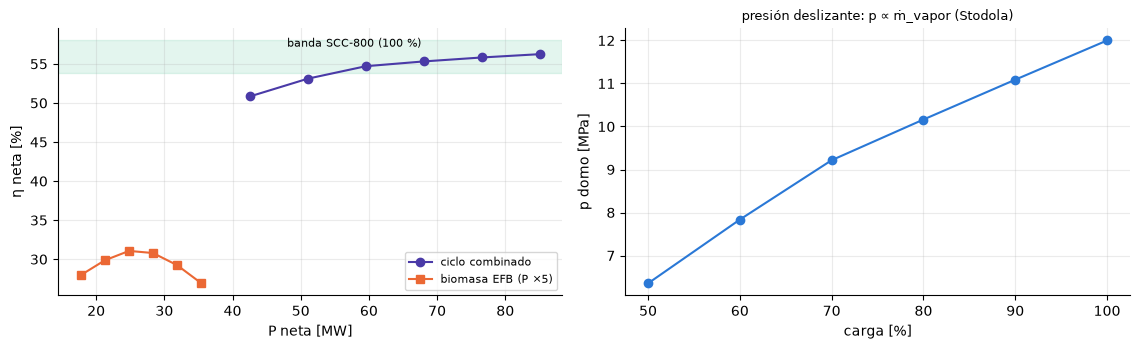

In [25]:
# === Carga parcial con presión deslizante (estados estacionarios por simulación) ==============================
FRACS = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]
def tabla_carga(pl):
    filas = []
    for fr in FRACS:
        x = pl.x0 if fr == 1.0 else pl.estado_carga(fr); o = pl.algebra(0, x)
        filas.append(dict(carga=fr, P_GT=o["P_GT"]/1e6, P_ST=o["P_ST"]/1e6, P_neta=o["P_neto"]/1e6, Qf=o["Qf"]/1e6, eta=100*o["eta"],
                          p_domo=x[IDX["p"]]/1e6, T3=o["T3"] - 273.15, T_chim=o["Tstack"] - 273.15, p_c=o["pc"]/1e3,
                          Q_chim=o["Q_stack"]/1e6, Q_cond=o["Q_cond"]/1e6, P_bomba=o["P_bomba"]/1e6))
    return pd.DataFrame(filas)
if "carga_parcial" in CACHE and not RECALCULAR: CARGA = {k: pd.DataFrame(v) for k, v in CACHE["carga_parcial"].items()}
else:
    CARGA = {"CC": tabla_carga(PL_CC), "BIO": tabla_carga(PL_BIO)}; CACHE["carga_parcial"] = {k: v.to_dict("list") for k, v in CARGA.items()}
display(CARGA["CC"].round(2).set_index("carga"))
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax[0].plot(CARGA["CC"].P_neta, CARGA["CC"].eta, "o-", color=COL["vapor"], label="ciclo combinado"); ax[0].plot(CARGA["BIO"].P_neta*5, CARGA["BIO"].eta, "s-", color=COL["tibio"], label="biomasa EFB (P ×5)")
ax[0].axhspan(53.8, 58.0, color=COL["red"], alpha=0.12); ax[0].text(48, 57.2, "banda SCC-800 (100 %)", fontsize=8)
ax[0].set_xlabel("P neta [MW]"); ax[0].set_ylabel("η neta [%]"); ax[0].legend(fontsize=8)
ax[1].plot(CARGA["CC"].carga*100, CARGA["CC"].p_domo, "o-", color=COL["agua"]); ax[1].set_xlabel("carga [%]"); ax[1].set_ylabel("p domo [MPa]")
ax[1].set_title("presión deslizante: p ∝ ṁ_vapor (Stodola)", fontsize=9.5)
plt.tight_layout(); plt.show()

## 11. La red y la demanda

**Ecuación de oscilación.** Todos los rotores sincronizados forman una sola inercia equivalente. Un desbalance entre generación y demanda cambia su energía cinética y con ella la frecuencia:

$$\frac{2\sum_iH_iS_i}{f_0}\,\frac{d\,\Delta f}{dt}=\sum P_{m}-P_d\Big(1+D\frac{\Delta f}{f_0}\Big),$$

con $H$ [s] la constante de inercia (energía cinética a velocidad nominal / potencia nominal) y $D$ la sensibilidad de la carga a la frecuencia.

**Controles en cascada:**
1. **Primario (segundos), estatismo:** cada gobernador cambia su potencia $\Delta P=-\frac{P_n}{R}\frac{\Delta f}{f_0}$ con $R$ = 5 %. Detiene la caída de la frecuencia pero no la restablece.
2. **Secundario (minutos), AGC:** integra el error de área $\beta\Delta f$ y reparte la corrección para devolver la frecuencia a 60 Hz.
3. **Terciario (despacho):** fija la consigna horaria de cada planta según el perfil de demanda.

**Quién responde y cuándo.** La turbina de gas cambia de potencia en segundos (combustible y gases). La turbina de vapor solo sigue cuando el metal de la HRSG y el agua del domo cambian de temperatura, lo que toma minutos. Hay dos maneras de usar la energía almacenada en el domo para una respuesta rápida:
- **reserva estrangulada** en la válvula de la TV: cuesta eficiencia por la pérdida de estrangulamiento;
- en la caldera de biomasa, el modo **"caldera sigue"**: rápido, pero hace oscilar presión y nivel. El modo **"turbina sigue"** cuida la caldera y es lento.

Cada escenario se integra con el modelo completo (36 EDO) y se guarda en la caché. El tablero también simula escenarios propios en vivo (~5 s).

In [26]:
# === Escenarios de demanda: se integran una vez y se guardan en la caché ==========================================
def perfil_diario(t_h):
    # forma ESTILIZADA de la demanda diaria (valle a las 4 h, meseta diurna, pico a las 19:30 h); NO son datos medidos
    x = 2*np.pi*(t_h % 24)/24
    return 0.80 - 0.12*np.cos(x - 0.35) - 0.06*np.cos(2*x - 0.9) + 0.035*np.cos(3*x - 2.6) + 0.10*np.exp(-0.5*((t_h % 24 - 19.6)/1.3)**2)
_pd = perfil_diario(np.linspace(0, 24, 1441)); PD_MIN, PD_MAX = _pd.min(), _pd.max()
def frac_dia(t): return 0.55 + 0.45*(perfil_diario(t/3600) - PD_MIN)/(PD_MAX - PD_MIN)
def ruido(t): return 0.004*(np.sin(2*np.pi*t/37) + 0.7*np.sin(2*np.pi*t/113 + 1) + 0.5*np.sin(2*np.pi*t/290 + 2))
ESCENARIOS = {
    "Día típico (red, 24 h)": dict(t_fin=86400.0, dt=120.0, frac0=None),
    "Rampa de demanda (isla, 1 h)": dict(t_fin=3600.0, dt=10.0, frac0=0.6),
    "Disparo de otra unidad (red, 20 min)": dict(t_fin=1200.0, dt=4.0, frac0=0.8),
    "Escalón de carga +8 % (isla, 20 min)": dict(t_fin=1200.0, dt=4.0, frac0=0.8)}
MODOS = {"CC": ["pasiva", "reserva"], "BIO": ["caldera_sigue", "turbina_sigue"]}
SALIDAS = ["f", "P_GT", "P_ST", "P_neto", "eta", "co2", "Tstack", "T3", "pc", "qs", "nivel", "Qf", "Tg_in", "Qev", "q_sv"]

def armar_escenario(pl, nombre, modo, paso=None, red=None, dT_cw=0.0, nivel="3e", disparo_TV=None):
    E = ESCENARIOS.get(nombre, dict(t_fin=1200.0, dt=4.0, frac0=0.8)); Pn = pl.P_nom/1e6
    S_p = pl.S_TG + pl.S_TV; S_r = 10*S_p; Pr0 = 0.85*S_r*0.8
    Tcw = (lambda t: 298.15 + dT_cw*(t > 60)) if dT_cw else (lambda t: 298.15)
    if nombre.startswith("Día"):
        frac0 = frac_dia(0.0); Ps = lambda t: frac_dia(t)*Pn
        esc = dict(P_sched=Ps, P_load=lambda t: Ps(t) + Pr0*(1 + ruido(t)), S_r=S_r, P_r0=Pr0,
                   T_cw_in=lambda t: 298.15 + 3*np.sin(2*np.pi*(t/3600 - 9)/24))       # agua de enfriamiento: +3 K a las 15 h
    elif nombre.startswith("Rampa"):
        frac0 = 0.6; Pl = lambda t: Pn*(0.6 + 0.35*min(max((t - 300)/1200, 0), 1)); esc = dict(P_sched=Pl, P_load=Pl, S_r=0.0, T_cw_in=Tcw)
    elif nombre.startswith("Disparo"):
        frac0 = 0.8; Ps = lambda t: 0.8*Pn
        esc = dict(P_sched=Ps, P_load=lambda t: Ps(t) + Pr0 + 0.05*(S_r + S_p)*0.85*(t > 60), S_r=S_r, P_r0=Pr0, T_cw_in=Tcw)
    elif nombre.startswith("Escalón"):
        frac0 = 0.8; Ps = lambda t: 0.8*Pn; esc = dict(P_sched=Ps, P_load=lambda t: Ps(t)*(1 + 0.08*(t > 60)), S_r=0.0, T_cw_in=Tcw)
    else:                                   # escenario propio (widget en vivo)
        frac0 = 0.8; Ps = lambda t: 0.8*Pn
        if red == "isla": esc = dict(P_sched=Ps, P_load=lambda t: Ps(t)*(1 + paso/100*(t > 60)), S_r=0.0, T_cw_in=Tcw)
        else: esc = dict(P_sched=Ps, P_load=lambda t: Ps(t) + Pr0 + paso/100*(S_r + S_p)*0.85*(t > 60), S_r=S_r, P_r0=Pr0, T_cw_in=Tcw)
    esc["modo"] = modo; esc["nivel"] = nivel; esc["t_disparo_TV"] = disparo_TV
    return esc, frac0, E["t_fin"], E["dt"]

_X0C = {}
def correr(pl, nombre, modo, **kw):
    esc, frac0, t_fin, dt = armar_escenario(pl, nombre, modo, **kw)
    key = (id(pl), round(frac0, 4), modo)
    if key not in _X0C: _X0C[key] = pl.estado_carga(frac0, modo)
    x0 = _X0C[key].copy()
    pl.configurar(esc)
    if esc.get("S_r", 0) > 0: x0[IDX["Pr"]] = esc["P_r0"]
    sol = pl.simular(t_fin, x0, dt_out=dt, max_step=min(10.0, dt))
    out = {k: [] for k in SALIDAS}
    for i in range(sol.y.shape[1]):
        o = pl.algebra(sol.t[i], sol.y[:, i])
        for k in SALIDAS: out[k].append(float(o[k]))
    out["t"] = sol.t.tolist(); out["p"] = (sol.y[IDX["p"]]/1e6).tolist(); out["y"] = sol.y[IDX["y"]].tolist()
    out["qf"] = sol.y[IDX["qf"]].tolist(); out["P_dem"] = [float(esc["P_sched"](t)) for t in sol.t]
    out["P_load"] = [float(esc["P_load"](t) - esc.get("P_r0", 0.0)) for t in sol.t]
    out["Tm_sh"] = sol.y[IDX["sh"]].mean(axis=0).tolist(); out["ok"] = bool(sol.success); out["isla"] = esc.get("S_r", 0.0) == 0
    return out

RES = {} if RECALCULAR else CACHE.get("escenarios", {}); t0 = time.time(); nuevos = 0
for tipo, pl in (("CC", PL_CC), ("BIO", PL_BIO)):            # solo se integran las combinaciones que faltan en la caché
    for nombre in ESCENARIOS:
        for modo in MODOS[tipo]:
            clave = f"{tipo}|{nombre}|{modo}"
            if clave in RES: continue
            t1 = time.time(); RES[clave] = correr(pl, nombre, modo); nuevos += 1
            print(f"  {tipo:3s} {nombre:38s} {modo:14s} {time.time() - t1:6.1f} s", flush=True)
if nuevos:
    CACHE["escenarios"] = RES; json.dump(CACHE, open(ARCH, "w")); print(f"{nuevos} escenarios integrados en {time.time() - t0:.0f} s")
print(f"{len(RES)} escenarios disponibles; todos exitosos: {all(v['ok'] for v in RES.values())}")

16 escenarios disponibles; todos exitosos: True


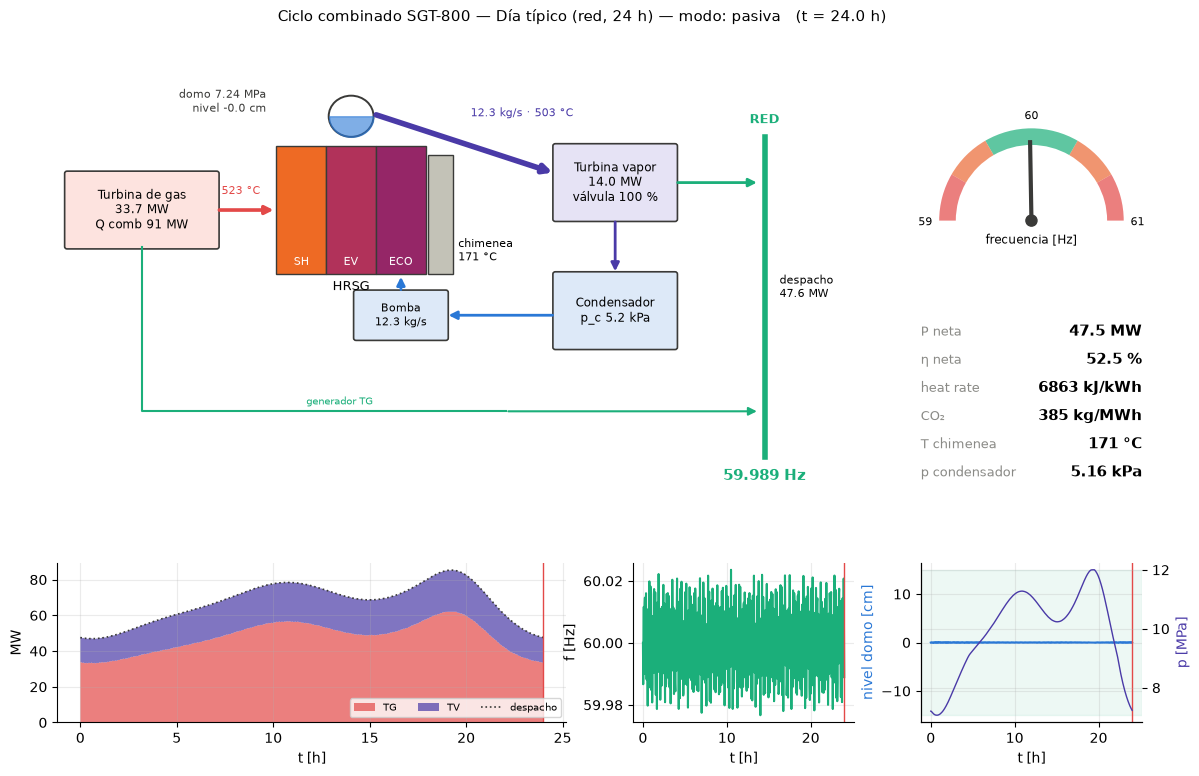

In [27]:
# === Widget 8: TABLERO GLOBAL DE PLANTA ============================================================================
def _tcolor(T, Tmin=300.0, Tmax=900.0):
    return plt.get_cmap("inferno")(0.15 + 0.75*np.clip((T - Tmin)/(Tmax - Tmin), 0, 1))
def dibujar_mimico(ax, S, i, tipo):
    g = lambda k: S[k][i]
    ax.set_xlim(0, 16); ax.set_ylim(0, 9); ax.axis("off")
    caja = lambda x, y, w, h, fc, txt, fs=8.5: (ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=fc, ec=COL["tinta"], lw=1.2)),
                                               ax.text(x + w/2, y + h/2, txt, ha="center", va="center", fontsize=fs))
    flecha = lambda a, b, c, w: ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=12, color=c, lw=w))
    if tipo == "CC":
        caja(0.2, 5.6, 3.0, 1.6, "#fde3df", f"Turbina de gas\n{g('P_GT')/1e6:.1f} MW\nQ comb {g('Qf')/1e6:.0f} MW")
        flecha((3.2, 6.4), (4.4, 6.4), COL["gas"], 1 + 3*g("P_GT")/62e6); ax.text(3.3, 6.75, f"{g('Tg_in') - 273.15:.0f} °C", fontsize=8, color=COL["gas"])
    else:
        caja(0.2, 5.6, 3.0, 1.6, "#fdebd8", f"Hogar EFB\n{g('Qf')/1e6:.1f} MW comb.\nT llama {g('Tg_in') - 273.15:.0f} °C")
        for k_ in range(3): ax.plot([0.9 + 0.7*k_]*2, [5.1, 5.1 + 0.4*g("Qf")/S["Qf"][0]], color=COL["tibio"], lw=3)
        flecha((3.2, 6.4), (4.4, 6.4), COL["tibio"], 2)
    # HRSG con 3 secciones coloreadas por temperatura del metal/gas
    secs = [("SH", g("Tm_sh")), ("EV", tsat_p(g("p")*1e6)), ("ECO", 0.5*(g("Tstack") + tsat_p(g("p")*1e6)))]
    for k_, (nm, T) in enumerate(secs):
        ax.add_patch(Rectangle((4.4 + 1.0*k_, 5.0), 1.0, 2.8, fc=_tcolor(T), ec=COL["tinta"])); ax.text(4.9 + k_, 5.2, nm, ha="center", fontsize=8, color="white")
    ax.text(5.9, 4.65, "HRSG" if tipo == "CC" else "caldera", ha="center", fontsize=9)
    ax.add_patch(Rectangle((7.45, 5.0), 0.5, 2.6, fc=COL["metal"], ec=COL["tinta"])); ax.text(8.05, 5.3, f"chimenea\n{g('Tstack') - 273.15:.0f} °C", ha="left", fontsize=8)
    # domo con nivel
    lv = g("nivel"); ax.add_patch(Circle((5.9, 8.55 - 0.1), 0.45, fc="white", ec=COL["tinta"], lw=1.4))
    yl = 8.45 + np.clip(lv*2.0, -0.4, 0.4); xs = np.linspace(5.46, 6.34, 40); top = 8.45 + np.sqrt(np.clip(0.2025 - (xs - 5.9)**2, 0, None))
    bot = 8.45 - np.sqrt(np.clip(0.2025 - (xs - 5.9)**2, 0, None)); ax.fill_between(xs, bot, np.minimum(top, yl), color=COL["agua"], alpha=0.6)
    alarma = abs(lv) > 0.15
    ax.text(4.2, 8.55, f"domo {g('p'):.2f} MPa\nnivel {100*lv:+.1f} cm", fontsize=8, ha="right", color=COL["aviso"] if alarma else COL["tinta"], weight="bold" if alarma else "normal")
    # vapor a la TV
    flecha((6.35, 8.5), (10.0, 7.2), COL["vapor"], 1 + 3*g("qs")/S["qs"][0]); ax.text(8.3, 8.45, f"{g('qs'):.1f} kg/s · {g('T3') - 273.15:.0f} °C", fontsize=8, color=COL["vapor"])
    caja(10.0, 6.2, 2.4, 1.6, "#e6e3f5", f"Turbina vapor\n{g('P_ST')/1e6:.1f} MW\nválvula {100*g('y'):.0f} %")
    caja(10.0, 3.4, 2.4, 1.6, "#dde9f8", f"Condensador\np_c {g('pc')/1e3:.1f} kPa")
    flecha((11.2, 6.2), (11.2, 5.0), COL["vapor"], 2)
    caja(6.0, 3.6, 1.8, 1.0, "#dde9f8", f"Bomba\n{g('qf'):.1f} kg/s", 8)
    flecha((10.0, 4.1), (7.8, 4.1), COL["agua"], 2); flecha((6.9, 4.6), (6.9, 5.0), COL["agua"], 2)
    # red
    ax.plot([14.2, 14.2], [1.0, 8.0], color=COL["red"], lw=4); ax.text(14.2, 8.3, "RED", ha="center", fontsize=9, color=COL["red"], weight="bold")
    flecha((12.4, 7.0), (14.1, 7.0), COL["red"], 2)
    if tipo == "CC":
        ax.plot([1.7, 1.7, 9.0], [5.6, 2.0, 2.0], color=COL["red"], lw=1.5); flecha((9.0, 2.0), (14.1, 2.0), COL["red"], 1.5)
        ax.text(5.0, 2.15, "generador TG", fontsize=7.5, color=COL["red"])
    df = g("f") - F0; cf = COL["red"] if abs(df) < 0.1 else (COL["tibio"] if abs(df) < 0.3 else COL["aviso"])
    ax.text(14.2, 0.5, f"{g('f'):.3f} Hz", ha="center", fontsize=11, weight="bold", color=cf)
    ax.text(14.5, 4.5, (f"demanda\n{S['P_load'][i]:.1f} MW" if S.get("isla", False) else f"despacho\n{S['P_dem'][i]:.1f} MW"), fontsize=8)

def dibujar_dial(ax, f):
    ax.set_xlim(-1.2, 1.2); ax.set_ylim(-0.3, 1.2); ax.set_aspect("equal"); ax.axis("off")
    for a0, a1, c in [(0, 30, COL["aviso"]), (30, 60, COL["tibio"]), (60, 120, COL["red"]), (120, 150, COL["tibio"]), (150, 180, COL["aviso"])]:
        ax.add_patch(Wedge((0, 0), 1.0, a0, a1, width=0.18, fc=c, alpha=0.7))
    ang = np.radians(90 - (f - F0)/1.0*90); ax.plot([0, 0.85*np.cos(ang)], [0, 0.85*np.sin(ang)], color=COL["tinta"], lw=3); ax.add_patch(Circle((0, 0), 0.06, color=COL["tinta"]))
    for v, a in [(59, 180), (60, 90), (61, 0)]: ax.text(1.15*np.cos(np.radians(a)), 1.15*np.sin(np.radians(a)) - 0.05, f"{v}", ha="center", fontsize=8)
    ax.text(0, -0.25, "frecuencia [Hz]", ha="center", fontsize=8.5)

def w8_tablero(planta, escenario, modo, k, S=None):
    tipo = "CC" if planta.startswith("Ciclo") else "BIO"
    if S is None:
        clave = f"{tipo}|{escenario}|{modo}"
        if clave not in RES: print("Combinación no disponible:", clave); return
        S = RES[clave]
    # protección de frecuencia de la unidad (SUPUESTO: 57.5-62.5 Hz): si se viola, la unidad dispara y la serie se corta ahí
    fa = np.array(S["f"]); fuera = np.where((fa < 57.5) | (fa > 62.5))[0]; n_trip = int(fuera[0]) if len(fuera) else None
    if n_trip is not None: S = {kk: (vv[:n_trip + 1] if isinstance(vv, list) else vv) for kk, vv in S.items()}
    n = len(S["t"]); i = min(int(k/100*(n - 1)), n - 1); t = np.array(S["t"])
    esc_h = t[-1] > 20000; tx = t/3600 if esc_h else t/60; ux = "h" if esc_h else "min"
    fig = plt.figure(figsize=(14, 8.2)); gsp = fig.add_gridspec(3, 4, height_ratios=[1.1, 1.1, 1.0], hspace=0.35, wspace=0.3)
    dibujar_mimico(fig.add_subplot(gsp[:2, :3]), S, i, tipo)
    dibujar_dial(fig.add_subplot(gsp[0, 3]), S["f"][i])
    ak = fig.add_subplot(gsp[1, 3]); ak.axis("off")
    hr = 3600/max(S["eta"][i], 1e-3)
    # en un transitorio que consume (o repone) energía almacenada, P/Q_comb no es una eficiencia: se oculta fuera de rango físico
    fisico = 0.0 < S["eta"][i] < (0.62 if tipo == "CC" else 0.40)
    eta_txt, hr_txt, co2_txt = ((f"{100*S['eta'][i]:.1f} %", f"{hr:.0f} kJ/kWh", f"{S['co2'][i]:.0f} kg/MWh") if fisico else ("transitorio",) * 3)
    for j, (lab, val) in enumerate([("P neta", f"{S['P_neto'][i]/1e6:.1f} MW"), ("η neta", eta_txt), ("heat rate", hr_txt),
                                     ("CO₂" + (" biogénico" if tipo == "BIO" else ""), co2_txt), ("T chimenea", f"{S['Tstack'][i] - 273.15:.0f} °C"),
                                     ("p condensador", f"{S['pc'][i]/1e3:.2f} kPa")]):
        ak.text(0.0, 0.95 - 0.16*j, lab, fontsize=9, color=COL["gris"], transform=ak.transAxes)
        ak.text(1.0, 0.95 - 0.16*j, val, fontsize=11, ha="right", weight="bold", transform=ak.transAxes)
    a1 = fig.add_subplot(gsp[2, :2]); PG, PS = np.array(S["P_GT"])/1e6, np.array(S["P_ST"])/1e6
    a1.stackplot(tx, PG, PS, colors=[COL["gas"], COL["vapor"]], alpha=0.7, labels=["TG", "TV"])
    if S.get("isla", False): a1.plot(tx, S["P_load"], color=COL["tinta"], lw=1.2, label="demanda de la isla")
    a1.plot(tx, S["P_dem"], ":", color=COL["tinta"], lw=1.2, label="despacho"); a1.axvline(tx[i], color=COL["aviso"], lw=1)
    a1.set_ylabel("MW"); a1.set_xlabel(f"t [{ux}]"); a1.legend(fontsize=7.5, ncol=4, loc="lower right"); a1.set_ylim(0, None)
    a2 = fig.add_subplot(gsp[2, 2]); a2.plot(tx, S["f"], color=COL["red"]); a2.axvline(tx[i], color=COL["aviso"], lw=1); a2.set_ylabel("f [Hz]"); a2.set_xlabel(f"t [{ux}]")
    a3 = fig.add_subplot(gsp[2, 3]); a3.plot(tx, 100*np.array(S["nivel"]), color=COL["agua"]); a3.axhspan(-15, 15, color=COL["red"], alpha=0.08)
    a3.axvline(tx[i], color=COL["aviso"], lw=1); a3.set_ylabel("nivel domo [cm]", color=COL["agua"]); a3.set_xlabel(f"t [{ux}]")
    a3b = a3.twinx(); a3b.plot(tx, S["p"], color=COL["vapor"], lw=1); a3b.set_ylabel("p [MPa]", color=COL["vapor"])
    fig.suptitle(f"{planta} — {escenario} — modo: {modo}   (t = {tx[i]:.1f} {ux})", fontsize=11)
    if n_trip is not None:
        fig.text(0.5, 0.935, f"⚠ DISPARO de la unidad por protección de frecuencia (57.5-62.5 Hz) a t = {tx[-1]:.1f} {ux}: "
                 "en «turbina sigue» el combustible es demasiado lento para regular una isla", ha="center", fontsize=10, color=COL["aviso"], weight="bold")
    plt.show()

w8_planta = Dropdown(options=["Ciclo combinado SGT-800", "Biomasa EFB (config. B)"], description="planta", layout=Layout(width="330px"))
w8_esc = Dropdown(options=list(ESCENARIOS), description="escenario", layout=Layout(width="420px"))
w8_modo = ToggleButtons(options=MODOS["CC"], description="modo TV")
w8_k = IntSlider(value=100, min=0, max=100, description="tiempo [%]", layout=Layout(width="500px"))
w8_play = Play(value=0, min=0, max=100, step=1, interval=700); jslink((w8_play, "value"), (w8_k, "value"))
def _cambia_planta(ch): w8_modo.options = MODOS["CC" if ch["new"].startswith("Ciclo") else "BIO"]
w8_planta.observe(_cambia_planta, names="value")
display(VBox([HBox([w8_planta, w8_esc]), w8_modo, HBox([w8_play, w8_k]),
              interactive_output(w8_tablero, dict(planta=w8_planta, escenario=w8_esc, modo=w8_modo, k=w8_k))]))

In [28]:
# --- Tablero en vivo: escenario propio (se integra el modelo completo al pulsar) -----------------------------------
v_planta = Dropdown(options=["Ciclo combinado SGT-800", "Biomasa EFB (config. B)"], description="planta", layout=Layout(width="330px"))
v_modo = ToggleButtons(options=MODOS["CC"], description="modo TV")
v_red = ToggleButtons(options=["isla", "interconectada"], value="isla", description="red")
v_paso = FloatSlider(value=8, min=-15, max=15, step=1, description="escalón [%]")
v_cw = FloatSlider(value=0, min=0, max=8, step=1, description="ΔT agua enfr. [K]")
v_go = Button(description="simular 20 min", button_style="primary"); v_out = Output()
v_planta.observe(lambda ch: setattr(v_modo, "options", MODOS["CC" if ch["new"].startswith("Ciclo") else "BIO"]), names="value")
v_k = IntSlider(value=100, min=0, max=100, description="tiempo [%]", layout=Layout(width="500px"))
v_play = Play(value=0, min=0, max=100, step=1, interval=700); jslink((v_play, "value"), (v_k, "value"))
_VIVO = {}
def _simular(_):
    with v_out:
        v_out.clear_output(); print("integrando 36 EDO ..."); t0 = time.time()
        pl = PL_CC if v_planta.value.startswith("Ciclo") else PL_BIO
        _VIVO["S"] = correr(pl, "propio", v_modo.value, paso=v_paso.value, red=v_red.value, dT_cw=v_cw.value)
        _VIVO["planta"] = v_planta.value; v_out.clear_output()
        print(f"listo en {time.time() - t0:.1f} s"); _dibujar_vivo({"new": v_k.value})
def _dibujar_vivo(ch):
    if "S" not in _VIVO: return
    with v_out:
        v_out.clear_output(wait=True)
        w8_tablero(_VIVO["planta"], f"propio: {v_paso.value:+.0f} % en {v_red.value}, ΔT_cw {v_cw.value:.0f} K", v_modo.value, v_k.value, S=_VIVO["S"])
v_go.on_click(_simular); v_k.observe(_dibujar_vivo, names="value")
display(VBox([HBox([v_planta, v_red]), v_modo, HBox([v_paso, v_cw, v_go]), HBox([v_play, v_k]), v_out]))

**Widget 8. Tablero global de planta.**
- **Día típico:** la planta sigue el despacho horario. Por la tarde el agua de enfriamiento se calienta y la contrapresión sube. Observa el pico de las 19:30 h.
- **Disparo de otra unidad:** la frecuencia cae en segundos. La TG responde por estatismo y el AGC la devuelve a 60 Hz en minutos. Compara **pasiva** y **reserva**: con la válvula estrangulada la TV aporta potencia inmediata a costa del domo (mira el nivel y la presión).
- **Escalón en isla:** no hay un sistema grande que amortigüe. El *nadir* de frecuencia depende de la inercia de solo dos rotores.
- **Biomasa:** "caldera sigue" responde rápido con oscilaciones de presión y nivel. "Turbina sigue" cuida la caldera pero tarda (el carbonizado arde en ~90 s). En **isla**, "turbina sigue" no logra sostener la frecuencia y la protección (57.5-62.5 Hz) **dispara la unidad**. Por eso las islas se operan con el gobernador actuando sobre la válvula.
- **En vivo:** prueba un escalón de −15 % (rechazo de carga) y observa la sobrepresión del domo.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


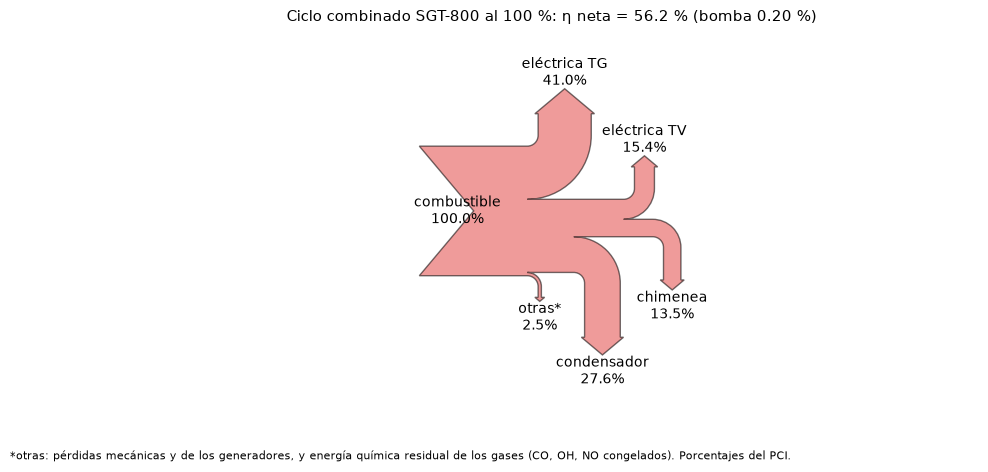

Output()

In [29]:
# === Widget 9: diagrama de Sankey de la energía a carga parcial ================================================
from matplotlib.sankey import Sankey
def w9_sankey(planta, carga):
    tipo = "CC" if planta.startswith("Ciclo") else "BIO"; D = CARGA[tipo]
    f = D.iloc[(D.carga - carga/100).abs().argmin()]
    Q = f.Qf; PGT, PST, Pb = f.P_GT, f.P_ST, f.P_bomba
    pq = lambda v: 100*v/Q
    perd_chim, perd_cond = pq(f.Q_chim), pq(f.Q_cond)
    perd_otros = 100 - pq(PGT) - pq(PST) - perd_chim - perd_cond
    fig = plt.figure(figsize=(11, 5)); ax = fig.add_subplot(1, 1, 1, xticks=[], yticks=[]); ax.axis("off")
    flujos = [100, -pq(PGT), -pq(PST), -perd_chim, -perd_cond, -perd_otros]
    etiquetas = ["combustible", "eléctrica TG", "eléctrica TV", "chimenea", "condensador", "otras*"]
    orient, largos = [0, 1, 1, -1, -1, -1], [0.5, 0.3, 0.3, 0.4, 0.6, 0.2]
    keep = [j for j, v in enumerate(flujos) if abs(v) > 0.05]
    flujos, etiquetas, orient, largos = ([L[j] for j in keep] for L in (flujos, etiquetas, orient, largos))
    sk = Sankey(ax=ax, unit="%", format="%.1f", scale=0.012, gap=0.4)
    sk.add(flows=flujos, labels=etiquetas, orientations=orient, pathlengths=largos,
           facecolor=COL["tibio"] if tipo == "BIO" else COL["gas"], alpha=0.55)
    sk.finish()
    ax.set_title(f"{planta} al {100*f.carga:.0f} %: η neta = {f.eta:.1f} % (bomba {pq(Pb):.2f} %)", fontsize=10.5)
    fig.text(0.02, 0.02, "*otras: pérdidas mecánicas y de los generadores, y energía química residual de los gases (CO, OH, NO congelados). Porcentajes del PCI.", fontsize=8)
    plt.show()
display(interactive_output(w9_sankey, dict(planta=ToggleButtons(options=["Ciclo combinado SGT-800", "Biomasa EFB (config. B)"], description="planta"),
                                           carga=IntSlider(value=100, min=50, max=100, step=10, description="carga [%]"))))

**Widget 9. ¿A dónde va la energía?** En el ciclo combinado, la chimenea y el condensador se llevan casi todo lo que no se convierte en electricidad. A carga parcial la fracción eléctrica baja: la TG pierde eficiencia con la TIT reducida. En la biomasa el condensador domina, porque el vapor a 30 bar y 300 °C convierte poco.

## 12. 🎓 Resultados de la entrega, reproducidos y corregidos

La tabla pone lado a lado lo que reportó la entrega y lo que da este modelo. La columna "referencia" indica el dato externo o el cálculo independiente que decide cuál es correcto.

In [30]:
o = PL_CC.algebra(0, PL_CC.x0); d = PL_CC.d
q_real = (h_v(12e6, 813.15) - CP.PropsSI("H", "P", 12e6, "T", 317.15, "Water"))/1e3
dh_c, dh_t = TG["comp"], TG["turb"]
PI_t3 = dh_t["p"][3]/dh_t["p"][2]
filas = [
    ("P eléctrica TG [MW]", 62.50, TG["P"]/1e6, "SGT-800: 62.0"),
    ("η TG [%]", 39.31, 100*TG["eta"], "SGT-800: 41.1 (gas natural)"),
    ("c_a etapa 15 del compresor [m/s]", 131.9, DFC.ca_real_geo_entrega[14], "continuidad con ρ real"),
    ("Π etapa 3 de la turbina [-]", 0.22, PI_t3, "3 etapas de igual Δh"),
    ("calor por kg de vapor [kJ/kg]", 2841, q_real, "CoolProp (12 MPa, 540 °C, desde 44 °C)"),
    ("ṁ vapor [kg/s]", 21.68, d["ms"], "pinch 10 K (2.ª ley)"),
    ("T chimenea [°C]", 176.6, o["Tstack"] - 273.15, "pinch 10 K"),
    ("P TV [MW]", 23.14, o["P_ST"]/1e6, "—"),
    ("P neta CC [MW]", 85.64, o["P_neto"]/1e6, "—"),
    ("η CC [%]", 53.86, 100*o["eta"], "SCC-800 1x1: 53.8-58.0"),
    ("τ caldera [s]", 100.0, PL_CC.tau_metal, "masa de metal / UA (calculada)"),
    ("τ condensador [s]", 80.0, TAU_COND["cw"], "C_cw/(2ṁc_p) (calculada)"),
    ("H de la bomba [m]", 49.6, H_req, "requerida para 12 MPa"),
    ("U punta última etapa TV [m/s]", 1182, 650, "límite mecánico práctico ~650-700")]
display(pd.DataFrame(filas, columns=["magnitud", "entrega", "este modelo", "referencia"]).set_index("magnitud").round(2))

,entrega,este modelo,referencia
magnitud,,,
P eléctrica TG [MW],62.50,62.00,SGT-800: 62.0
η TG [%],39.31,41.02,SGT-800: 41.1 (gas natural)
c_a etapa 15 del compresor [m/s],131.90,18.05,continuidad con ρ real
Π etapa 3 de la turbina [-],0.22,0.30,3 etapas de igual Δh
calor por kg de vapor [kJ/kg],2841.00,3260.56,"CoolProp (12 MPa, 540 °C, desde 44 °C)"
ṁ vapor [kg/s],21.68,19.92,pinch 10 K (2.ª ley)
T chimenea [°C],176.60,167.32,pinch 10 K
P TV [MW],23.14,23.32,—
P neta CC [MW],85.64,85.02,—


**Lectura.** La entrega acierta en lo global (≈ 85 MW, ≈ 54 %) porque ajustó sus ángulos de álabe a los datos del fabricante. Pero tres de sus mecanismos internos no son físicos:
1. la velocidad axial ignora el cambio de densidad;
2. la caldera viola el pinch por las propiedades aproximadas del agua;
3. las constantes de tiempo son impuestas.

Corregirlos no cambia mucho el estado estacionario, pero **sí cambia la dinámica**. Con el retardo impuesto de 100 s, la caldera nunca muestra *swell*, que es justamente lo que hace difícil operar una planta de vapor.

## 13. Intervenciones tecnológicas de la entrega, cuantificadas

La entrega propone ocho intervenciones (5.1-5.8) de forma cualitativa. Cinco de ellas se pueden medir con el modelo:

In [31]:
# 5.2 Sobrepresión: disparo de la turbina de vapor (válvula cierra en ~2 s) con la fuente de calor encendida.
#     La válvula de seguridad (SUPUESTO: tarada a +10 % de la presión de diseño) debe abrir antes de que el domo la supere.
res13 = {}
for tipo, pl, modo in (("CC", PL_CC, "pasiva"), ("BIO", PL_BIO, "caldera_sigue")):
    S = correr(pl, "propio", modo, paso=0.0, red="interconectada", disparo_TV=60.0); t_ = np.array(S["t"]); p_ = np.array(S["p"])
    p_set = 1.1*pl.p_d/1e6; i = np.argmax(p_ > p_set) if np.any(p_ > p_set) else None
    res13[tipo] = S
    print(f"5.2 [{tipo}] disparo de la TV a 60 s desde 80 % de carga: p_domo {p_[0]:.2f} -> {p_.max():.2f} MPa en 20 min; "
          + (f"la válvula de seguridad ({p_set:.1f} MPa) abre a los {t_[i] - 60:.0f} s y alivia hasta {max(S['q_sv']):.1f} kg/s" if i else f"no alcanza el tarado ({p_set:.1f} MPa)"))
# 5.3 Pérdidas de carga en la línea de vapor: potencia de la TV vs. caída de presión
h3 = h_v(12e6, 813.15); P0 = PL_CC._h4(12e6, h3, PL_CC.d["pc"])
for dp in (0.02, 0.05, 0.10):
    dP = -(PL_CC._h4(12e6*(1 - dp), h3, PL_CC.d["pc"]) - P0)*PL_CC.d["ms"]*PL_CC.C["eta_mg"]      # estrangulamiento: h4 sube
    print(f"5.3 caída de presión de {100*dp:.0f} % antes de la TV -> ΔP_TV = {dP/1e3:+.0f} kW ({100*dP/PL_CC.d['P_ST']:+.2f} %)")
# 5.4 Condensación: sensibilidad de la TV a la temperatura del agua de enfriamiento (§9)
tt, Y, pc, P = sim_condensador("T agua de mar/torre", 1.0)
print(f"5.4 +1 K en el agua de enfriamiento -> +{(pc[-1] - pc[0]):.0f} Pa en el condensador, {-(P[-1] - P[0])/1e3:.0f} kW menos en la TV")
# 5.5 Control de nivel: 1 vs. 3 elementos ante un escalón de +8 % en isla
for niv in ("1e", "3e"):
    S = correr(PL_CC, "propio", "reserva", paso=8, red="isla", nivel=niv); l = 100*np.array(S["nivel"])
    print(f"5.5 nivel con {'1 elemento ' if niv == '1e' else '3 elementos'}: excursión {l.min():+.1f} / {l.max():+.1f} cm")
# 5.8 Cuellos de botella: velocidades en la tubería de vapor principal (SUPUESTO D_int = 0.15 m) y en el condensador
v3 = PL_CC.d["ms"]/(CP.PropsSI("D", "P", 12e6, "T", 813.15, "Water")*np.pi/4*0.15**2)
print(f"5.8 vapor vivo en tubería de 150 mm: {v3:.0f} m/s (recomendado 30-60 m/s); agua en tubos del condensador: {h_i_cw(650)[1]:.2f} m/s (1-2.5 m/s)")

5.2 [CC] disparo de la TV a 60 s desde 80 % de carga: p_domo 10.16 -> 13.51 MPa en 20 min; la válvula de seguridad (13.2 MPa) abre a los 132 s y alivia hasta 30.7 kg/s


5.2 [BIO] disparo de la TV a 60 s desde 80 % de carga: p_domo 3.04 -> 3.32 MPa en 20 min; la válvula de seguridad (3.3 MPa) abre a los 40 s y alivia hasta 4.2 kg/s
5.3 caída de presión de 2 % antes de la TV -> ΔP_TV = -46 kW (-0.20 %)
5.3 caída de presión de 5 % antes de la TV -> ΔP_TV = -116 kW (-0.50 %)
5.3 caída de presión de 10 % antes de la TV -> ΔP_TV = -239 kW (-1.02 %)
5.4 +1 K en el agua de enfriamiento -> +1556 Pa en el condensador, 390 kW menos en la TV


5.5 nivel con 1 elemento : excursión -2.6 / +5.2 cm


5.5 nivel con 3 elementos: excursión -0.7 / +1.2 cm
5.8 vapor vivo en tubería de 150 mm: 32 m/s (recomendado 30-60 m/s); agua en tubos del condensador: 1.26 m/s (1-2.5 m/s)


**Conclusiones de la §13:**
- **5.2:** la válvula de seguridad no es decorativa. Si la turbina de vapor dispara y la TG sigue en servicio, la HRSG continúa generando vapor sin salida y la presión sube en minutos (por eso las HRSG llevan *bypass* al condensador). En la caldera de biomasa el control corta el combustible, pero el carbonizado sigue ardiendo ~90 s.
- **5.3 y 5.4:** cada kPa de contrapresión o cada % de caída de presión tiene un precio en kW que se puede poner en pesos.
- **5.5:** el control de 3 elementos reduce la excursión de nivel. Es la razón técnica de la intervención 5.5 de la entrega.

## 14. Verificación

Cada verificación compara dos caminos **independientes** al mismo número (criterio < 1 %). Las validaciones contra datos externos (V1-V4) se reportan aparte, con su desviación.

In [32]:
# === Verificación ===================================================================
err = {}
# 1) trabajo del compresor: CoolProp (aire real) vs. Cantera (aire ideal) entre las mismas T5 y T6
a = ct.Solution("gri30.yaml"); a.TPX = T_ISO, P_ISO*0.99, AIRE_CT; ha5 = a.enthalpy_mass; a.TPX = TG["comp"]["T2"], TG["comp"]["p2"], AIRE_CT
err["1) Δh compresor CoolProp vs Cantera"] = 100*abs(TG["comp"]["dh"] - (a.enthalpy_mass - ha5))/TG["comp"]["dh"]
# 2) cámara de combustión: balance de entalpía absoluta (Cantera) aire + combustible = productos en equilibrio a la TIT
f_ = ct.Solution("gri30.yaml"); f_.TPX = 288.15, TG["comp"]["p2"], GN; g_ = ct.Solution("gri30.yaml"); g_.TPY = TIT0, TG["comb"]["p3"], TG["comb"]["Y"]
far = TG["comb"]["far"]; err["2) 1.a ley en la cámara"] = 100*abs((a.enthalpy_mass + far*f_.enthalpy_mass)/(1 + far) - g_.enthalpy_mass)/abs(g_.enthalpy_mass)
# 3) HRSG en diseño: calor cedido por el gas = calor recibido por agua/vapor
o = PL_CC.algebra(0, PL_CC.x0); d = PL_CC.d
Qg = o["Qg_sh"].sum() + o["Qev"] + o["Qg_eco"].sum(); Qw = d["ms"]*(d["h3"] - d["h_fw"])
err["3) HRSG: Q gas = Q agua/vapor"] = 100*abs(Qg - Qw)/Qw
# 4) domo en diseño: Q_ev = q_s (h_s - h_f) (balance de energía de Åström-Bell en estado estacionario)
s = sat(PL_CC.p_d); err["4) domo: Q = q_s (h_s - h_f)"] = 100*abs(o["Qev"] - o["qs"]*(s["hs"] - o["h_fd"]))/o["Qev"]
# 5) condensador: estacionario de la red concentrada (alcanzado integrando sus EDO desde 10 K fuera) vs. marcha
#    espacial a lo largo del tubo (400 tramos, coeficientes constantes) con la misma T_sat
Ts5 = csat(o["pc"])["Ts"]; ho5, G5, C5 = PL_CC.h_o, PL_CC.G_cw, 650*4180.0
def red5(t, y):
    Tw, Tc = y; return [(ho5*COND["Ao"]*(Ts5 - Tw) - G5*(Tw - Tc))/COND["Cw"], (G5*(Tw - Tc) - 2*C5*(Tc - 298.15))/COND["Ccw"]]
y5 = solve_ivp(red5, (0, 600), [300.0, 300.0], method="LSODA", rtol=1e-9, atol=1e-9).y[:, -1]; Q_red = 2*C5*(y5[1] - 298.15)
UA5 = 1/(1/(ho5*COND["Ao"]) + 1/(h_i_cw(650)[0]*COND["Ai"])); T = 298.15
for _ in range(400): T += (UA5/400)*(Ts5 - T)/C5
err["5) condensador: red concentrada vs marcha en el tubo"] = 100*abs(Q_red - C5*(T - 298.15))/(C5*(T - 298.15))
# 6) estatismo: con AGC y control de carga apagados, ΔP_TG = -(P_n/R)(Δf/f0) a los 120 s de un escalón en isla
Cg = dict(PL_CC.C); PL_CC.C.update(T_agc=1e12, Ki_pl=0.0)
x0 = PL_CC.estado_carga(0.8); Pn = PL_CC.P_nom/1e6
PL_CC.configurar(dict(P_sched=lambda t: 0.8*Pn, P_load=lambda t: 0.8*Pn*(1 + 0.05*(t > 10)), S_r=0.0, modo="pasiva"))
sl = PL_CC.simular(120, x0, dt_out=1.0); PL_CC.C.clear(); PL_CC.C.update(Cg)
dP_GT = (sl.y[IDX["u"], -1] - sl.y[IDX["u"], 0])/1e6; df_ = sl.y[IDX["df"], -1]
err["6) estatismo ΔP = -(P_n/R)Δf/f0"] = 100*abs(dP_GT - (-(PL_CC.P_TG_max/1e6)/0.05*df_/F0))/abs(dP_GT)
# 7) Stodola: la aproximación ṁ ∝ p_in del modelo vs. el cono completo ṁ ∝ √(p_in² - p_c²), en el peor caso (50 % de carga)
D = CARGA["CC"]; f50 = D.iloc[-1]
err["7) Stodola simplificado vs cono completo"] = 100*(1 - np.sqrt(1 - (f50.p_c*1e3/(f50.p_domo*1e6))**2))
# 8) 1.a ley global de la planta en diseño (base PCI): combustible + bomba = ejes + chimenea + condensador
#    (residuo esperado < 1 %: la energía química de CO/OH/NO congelados desde el equilibrio a la TIT, que el PCI da por quemada)
Wsh_GT, Wsh_ST = o["P_GT"]/(0.99*0.985), o["P_ST"]/PL_CC.C["eta_mg"]
a.TPX = T_ISO, P_ISO, AIRE_CT; ha15 = a.enthalpy_mass; a.TPX = 298.15, P_ISO, AIRE_CT
entra = o["Qf"] + TG["m_a"]*(ha15 - a.enthalpy_mass) + o["P_bomba"]
sale = Wsh_GT + Wsh_ST + o["Q_stack"] + o["Q_cond"]
err["8) 1.a ley global (PCI)"] = 100*abs(entra - sale)/entra
for k, v in err.items(): print(f"{k:42s} {v:8.4f} %  {'OK' if v < 1 else 'REVISAR'}")
print(f"\nValidaciones externas: V1 η SGT-800 {100*(TG['eta'] - 0.411)/0.411:+.2f} %, heat rate {100*(TG['HR'] - 8759)/8759:+.2f} %; "
      f"V2 RMS presión P16-G16 {V2['rms_p_pct']:.2f} %, swell con signo correcto {100*V2['signo']:.0f} %; V3 η CC {V3['eta']:.1f} % en [53.8, 58.0]; "
      f"V4 T_ad CH4 {100*(V4[0] - V4[1])/V4[1]:+.2f} %")

1) Δh compresor CoolProp vs Cantera          0.1291 %  OK
2) 1.a ley en la cámara                      0.0000 %  OK
3) HRSG: Q gas = Q agua/vapor                0.0000 %  OK
4) domo: Q = q_s (h_s - h_f)                 0.0000 %  OK
5) condensador: red concentrada vs marcha en el tubo   0.0711 %  OK
6) estatismo ΔP = -(P_n/R)Δf/f0              0.2583 %  OK
7) Stodola simplificado vs cono completo     0.0000 %  OK
8) 1.a ley global (PCI)                      0.5768 %  OK

Validaciones externas: V1 η SGT-800 -0.20 %, heat rate +0.21 %; V2 RMS presión P16-G16 0.75 %, swell con signo correcto 100 %; V3 η CC 56.2 % en [53.8, 58.0]; V4 T_ad CH4 -0.06 %


In [33]:
# guardar la caché (solo si se recalculó algo nuevo)
_prev = json.load(open(ARCH)) if os.path.exists(ARCH) else {}
if RECALCULAR or set(CACHE) != set(_prev):
    json.dump(CACHE, open(ARCH, "w")); print("caché actualizada:", sorted(CACHE))
else:
    print("caché sin cambios")

caché sin cambios


## Conclusión

Una planta termoeléctrica es una cadena de conversiones, y cada eslabón tiene su propia escala de tiempo:
- **La turbomáquina** convierte entalpía en par por cambio de momento angular (Euler), no con un brazo de palanca. Su "relación de compresión" se reparte en el eje: el canal se cierra o se abre siguiendo $1/\rho$, ~10 veces en la turbina de gas y ~700 en la de vapor.
- **La combustión 0D** fija cuánto calor entra y a qué temperatura. El **pinch** decide cuánto de ese calor recupera el vapor.
- **El domo** almacena energía en agua saturada y metal. Esa reserva amortigua la presión, pero hace que el nivel responda **al revés** ante la demanda.
- **La red** reparte la demanda por frecuencia: la turbina de gas responde en segundos y el vapor en minutos.

Validado contra la SGT-800, la banda del SCC-800 y la operación real de la P16-G16, el modelo permite operar la planta desde el tablero y medir el costo de cada estrategia de control.

### Ejercicios de extensión
1. *(De la entrega, corregido.)* Rediseña el compresor con $c_a$ = 150 m/s y radio de punta constante: ¿cuánto mide el álabe de la etapa 15? ¿Qué pasa con el número de Mach relativo en la punta de la etapa 1?
2. Agrega a la HRSG un segundo nivel de presión (4 MPa) y cuantifica la ganancia en $\dot m_s$ y en $P_{TV}$ (§6). Compara la razón $P_{CC}/P_{TG}$ con la del SCC-800.
3. En el tablero (escenario de disparo), ¿qué constante de inercia $H$ tendría que tener la planta en isla para que el *nadir* no baje de 59.5 Hz? Deduce la expresión de la tasa inicial de caída, $d\Delta f/dt=-\Delta P\,f_0/(2\sum H_iS_i)$.
4. Ajusta la Fig. 11 de Åström & Bell (escalones de agua de alimentación) con el mismo modelo de §7 y discute por qué el swell es menor que con combustible.
5. Con PMF en vez de EFB (§5 y tablero en vivo): ¿cuánto cambian el caudal de combustible, la eficiencia de caldera y la respuesta en "turbina sigue"? Relaciónalo con la humedad.
6. *(Abierto.)* Diseña un control de nivel con compensación del swell, basado en el modelo, que use la derivada de la presión del domo como entrada adicional.

### Referencias
- Åström, K. J., & Bell, R. D. (2000). Drum-boiler dynamics. *Automatica*, 36(3), 363-378. https://doi.org/10.1016/S0005-1098(99)00171-5
- Åström, K. J., & Bell, R. D. (1998). *Drum-Boiler Dynamics* (TFRT-7577). Lund Institute of Technology. https://lup.lub.lu.se/record/8602763
- Siemens Energy. *SGT-800 industrial gas turbine* (póster y ficha técnica).
- Çengel, Y. A., & Boles, M. A. (2019). *Termodinámica* (9.ª ed.). McGraw-Hill.
- Dixon, S. L., & Hall, C. A. (2014). *Fluid Mechanics and Thermodynamics of Turbomachinery* (7th ed.). Butterworth-Heinemann.
- Kehlhofer, R., Hannemann, F., Stirnimann, F., & Rukes, B. (2009). *Combined-Cycle Gas & Steam Turbine Power Plants* (3rd ed.). PennWell.
- Kundur, P. (1994). *Power System Stability and Control*. McGraw-Hill.
- Turns, S. R. (2012). *An Introduction to Combustion* (3rd ed.). McGraw-Hill.
- Wiesner, F. J. (1967). A review of slip factors for centrifugal impellers. *J. Eng. Power*, 89(4), 558-566.